# EDA остатков физических лиц по валютам

Вход — `df_fl` со столбцами `REP_DT`, `CURENCY`, `OST_VAL` и готовыми календарными признаками. Ключ строки — пара `(CURENCY, REP_DT)`. Если `df_fl` есть в ядре, ноутбук использует его. Иначе он читает `df_fl_synthetic.csv` с вымышленными рядами RUB, USD и EUR.

Запустите **Run All** в ядре с `pandas` 2+, `numpy` и `matplotlib`. Для декомпозиции и тестов стационарности нужен `statsmodels`. Денежные показатели анализируются в единицах исходной валюты. По умолчанию отчёт показывается по всем валютам. Например, `EDA_CURRENCIES = ("USD",)` оставит на экране только USD, а `df_stat` по-прежнему будет содержать признаки по всем валютам.

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

USE_SYNTHETIC = False
SYNTHETIC_PATH = Path("df_fl_synthetic.csv")
CURRENCY_COL = "CURENCY"
EDA_CURRENCIES = None  # Например ("RUB", "USD")
DAYFIRST = False       # True для неоднозначных дат в формате день/месяц/год
DUPLICATE_DATES = "raise"  # "first"/"last" — явный выбор строки в исходном порядке

if USE_SYNTHETIC or "df_fl" not in globals():
    if not SYNTHETIC_PATH.is_file():
        raise FileNotFoundError(
            f"Загрузите df_fl в ядро или укажите путь к синтетике: {SYNTHETIC_PATH.resolve()}"
        )
    df_input = pd.read_csv(SYNTHETIC_PATH)
    input_label = f"Синтетические данные · {SYNTHETIC_PATH.name}"
else:
    df_input = df_fl
    input_label = "Рабочие данные · df_fl"

if not isinstance(df_input, pd.DataFrame):
    raise TypeError("df_fl должен быть pandas DataFrame.")
if df_input.columns.has_duplicates:
    raise ValueError(f"Повторяющиеся имена столбцов: {df_input.columns[df_input.columns.duplicated()].tolist()}")
if CURRENCY_COL in {"REP_DT", "OST_VAL"}:
    raise ValueError("Для валюты нужен отдельный столбец.")
required_columns = {"REP_DT", "OST_VAL", CURRENCY_COL}
if missing_columns := required_columns.difference(df_input.columns):
    raise ValueError(f"Входные данные без обязательных столбцов: {sorted(missing_columns)}")
if DUPLICATE_DATES not in {"raise", "first", "last"}:
    raise ValueError('DUPLICATE_DATES должен быть "raise", "first" или "last".')

print(input_label)
print(f"Строк: {len(df_input):,} · столбцов: {df_input.shape[1]} · "
      f"память: {df_input.memory_usage(deep=True).sum() / 1024**2:.2f} МиБ")
schema = pd.DataFrame({
    "Тип": df_input.dtypes.astype(str),
    "Пропуски": df_input.isna().sum(),
    "Доля пропусков, %": df_input.isna().mean().mul(100),
    "Различных значений": df_input.nunique(),
})
display(schema.round(2))
display(df_input.head(5))

Синтетические данные · df_fl_synthetic.csv
Строк: 4,568 · столбцов: 29 · память: 1.43 МиБ


,Тип,Пропуски,"Доля пропусков, %",Различных значений
REP_DT,str,0,0.00,1741
CURENCY,str,1,0.02,3
OST_VAL,str,58,1.27,3936
day_of_week,int64,0,0.00,7
day_of_month,int64,0,0.00,31
day_of_year,float64,1,0.02,366
month,int64,0,0.00,12
quarter,int64,0,0.00,4
year,int64,0,0.00,5
iso_week,int64,0,0.00,53


,REP_DT,CURENCY,OST_VAL,day_of_week,day_of_month,day_of_year,month,quarter,year,iso_week,iso_year,days_to_month_end,is_weekend,is_month_start,is_month_end,is_quarter_start,is_quarter_end,is_year_start,is_year_end,is_holiday,is_day_before_holiday,is_day_after_holiday,days_since_holiday,days_until_holiday,holiday_name,weekday_sin,weekday_cos,month_sin,month_cos
0,2021-01-01,RUB,5931.0,4,1,1.0,1,1,2021,53,2020,30,False,True,False,True,False,True,False,True,False,False,0,0,Условный праздник А,-0.433884,-0.900969,0.0,1.0
1,2021-01-02,RUB,5694.94,5,2,2.0,1,1,2021,53,2020,29,True,False,False,False,False,False,False,False,False,True,1,65,NaN,-0.974928,-0.222521,0.0,1.0
2,2021-01-03,RUB,5739.32,6,3,3.0,1,1,2021,53,2020,28,True,False,False,False,False,False,False,False,False,False,2,64,NaN,-0.781831,0.623490,0.0,1.0
3,2021-01-04,RUB,5815.55,0,4,4.0,1,1,2021,1,2021,27,False,False,False,False,False,False,False,False,False,False,3,63,NaN,0.000000,1.000000,0.0,1.0
4,2021-01-05,RUB,5834.79,1,5,5.0,1,1,2021,1,2021,26,False,False,False,False,False,False,False,False,False,False,4,62,NaN,0.781831,0.623490,0.0,1.0


## Качество входных данных и покрытие календаря

Коды валют приводятся к верхнему регистру, пробелы по краям удаляются. Строки без валюты или пригодной даты показаны в диагностике и исключены. Даты приводятся к началу дня в исходном часовом поясе. Пустые, нечисловые и бесконечные остатки остаются пропусками.

Разные валюты на одну дату — обычные отчётные строки. Точные копии строк сворачиваются. При разных строках на одну пару «валюта и дата» ноутбук по умолчанию показывает конфликт и останавливается. После проверки источника можно выбрать `"first"` или `"last"` по порядку поступления строк.

Календарная сетка строится между первой и последней датой каждой валюты. Отдельно показаны дни без отчёта и дни с отчётом без пригодного остатка. Для отчётности по рабочим дням пропуски на выходных могут отражать график поступления данных.

In [2]:
def parse_report_timestamp(value):
    if not pd.api.types.is_scalar(value) or pd.isna(value) or pd.api.types.is_number(value):
        return pd.NaT
    year_first = isinstance(value, str) and bool(re.match(r"^\s*\d{4}[-/.]", value))
    stamp = pd.to_datetime(value, errors="coerce", dayfirst=DAYFIRST and not year_first)
    if pd.isna(stamp):
        return pd.NaT
    return stamp.tz_localize(None) if stamp.tzinfo is not None else stamp


raw_date = df_input["REP_DT"].reset_index(drop=True)
if isinstance(raw_date.dtype, pd.DatetimeTZDtype):
    parsed_dates = raw_date.dt.tz_localize(None)
elif pd.api.types.is_datetime64_any_dtype(raw_date.dtype):
    parsed_dates = raw_date
else:
    parsed_dates = pd.to_datetime(raw_date.map(parse_report_timestamp), errors="coerce")
normalized_dates = parsed_dates.dt.normalize()
raw_balance = df_input["OST_VAL"].reset_index(drop=True)
if pd.api.types.is_datetime64_any_dtype(raw_balance.dtype) or pd.api.types.is_timedelta64_dtype(raw_balance.dtype):
    numeric_balance = pd.Series(np.nan, index=raw_balance.index)
else:
    numeric_balance = pd.to_numeric(raw_balance, errors="coerce")
if pd.api.types.is_complex_dtype(numeric_balance.dtype):
    complex_values = numeric_balance.to_numpy()
    numeric_balance = pd.Series(
        np.where(complex_values.imag == 0, complex_values.real, np.nan), index=raw_balance.index
    )
numeric_balance = numeric_balance.astype(float)
resolved_balance = numeric_balance.replace([np.inf, -np.inf], np.nan)

keep_copy = "last" if DUPLICATE_DATES == "last" else "first"
copies = df_input.duplicated(keep=keep_copy).reset_index(drop=True)
raw_currency = df_input[CURRENCY_COL].reset_index(drop=True)
currency_labels = raw_currency.astype("string").str.strip().str.upper().replace("", pd.NA)
key_cols = [CURRENCY_COL, "REP_DT"]
normalized_keys = pd.DataFrame({CURRENCY_COL: currency_labels, "REP_DT": normalized_dates})
has_key = normalized_keys.notna().all(axis=1)
valid_keys = normalized_keys.loc[has_key]
repeated_keys = valid_keys.duplicated(keep=False)
date_diff = valid_keys.groupby(CURRENCY_COL)["REP_DT"].diff()
usable_rows = has_key & ~copies
clean_candidates = df_input.reset_index(drop=True).loc[usable_rows].copy()
clean_candidates[key_cols] = normalized_keys.loc[usable_rows]
clean_candidates["OST_VAL"] = resolved_balance.loc[usable_rows]
conflicts = clean_candidates.duplicated(key_cols, keep=False)

input_quality = pd.Series({
    "Строк на входе": len(df_input),
    "Строк без валюты": currency_labels.isna().sum(),
    "Различных валют": currency_labels.nunique(),
    "Пустая дата": raw_date.isna().sum(),
    "Неразбираемая непустая дата": (raw_date.notna() & normalized_dates.isna()).sum(),
    "Дата со временем внутри дня": (parsed_dates.notna() & parsed_dates.ne(normalized_dates)).sum(),
    "Возврат к более ранней дате внутри валюты": date_diff.lt(pd.Timedelta(0)).sum(),
    "Точные копии строк сверх первой": copies.sum(),
    "Повторных пар валюта и дата до удаления копий": len(valid_keys.loc[repeated_keys].drop_duplicates()),
    "Пар валюта и дата с разными строками": len(clean_candidates.loc[conflicts, key_cols].drop_duplicates()),
    "Пустой остаток": raw_balance.isna().sum(),
    "Нечисловой непустой остаток": (raw_balance.notna() & numeric_balance.isna()).sum(),
    "Бесконечный остаток": np.isinf(numeric_balance.to_numpy()).sum(),
}, name="Количество", dtype="int64")
display(input_quality.to_frame())

bad_rows = pd.DataFrame({
    "REP_DT исходный": raw_date,
    "OST_VAL исходный": raw_balance,
    "Валюта исходная": raw_currency,
    "Нет валюты": currency_labels.isna(),
    "Ошибка даты": normalized_dates.isna(),
    "Нечисловой остаток": raw_balance.notna() & numeric_balance.isna(),
    "Бесконечный остаток": np.isinf(numeric_balance.to_numpy()),
})
bad_examples = bad_rows.loc[bad_rows.iloc[:, 3:].any(axis=1)].head(12)
if not bad_examples.empty:
    print("Примеры строк с проблемами разбора, индекс показывает номер исходной строки с нуля.")
    display(bad_examples)

if conflicts.any():
    print("Примеры конфликтующих строк на одну пару «валюта и дата».")
    display(clean_candidates.loc[conflicts].sort_values(key_cols, kind="stable").head(12))
    if DUPLICATE_DATES == "raise":
        raise ValueError("На одну пару «валюта и дата» приходится несколько разных строк. Проверьте источник или задайте DUPLICATE_DATES.")
    clean_candidates = clean_candidates.drop_duplicates(subset=key_cols, keep=DUPLICATE_DATES)

df_work = clean_candidates.sort_values(key_cols, kind="stable").reset_index(drop=True)
if df_work.empty:
    raise ValueError("Во входных данных нет строк с пригодной валютой и датой.")

def build_daily_grid(currency_rows):
    day_index = pd.date_range(currency_rows["REP_DT"].min(), currency_rows["REP_DT"].max(), freq="D", name="REP_DT")
    daily = currency_rows.drop(columns=CURRENCY_COL).set_index("REP_DT").reindex(day_index)
    calendar_status = pd.DataFrame({
        "Есть отчёт": day_index.isin(currency_rows["REP_DT"]),
        "Есть остаток": daily["OST_VAL"].notna(),
    }, index=day_index)
    calendar_status["Нет отчёта"] = ~calendar_status["Есть отчёт"]
    calendar_status["Отчёт без остатка"] = calendar_status["Есть отчёт"] & ~calendar_status["Есть остаток"]

    overview = pd.Series({
        "Первая дата": day_index.min().date(),
        "Последняя дата": day_index.max().date(),
        "Календарных дней": len(day_index),
        "Отчётных дат после очистки": int(calendar_status["Есть отчёт"].sum()),
        "Дней без отчёта": int(calendar_status["Нет отчёта"].sum()),
        "Отчётных дат без остатка": int(calendar_status["Отчёт без остатка"].sum()),
        "Дней с пригодным остатком": int(calendar_status["Есть остаток"].sum()),
        "Покрытие остатками, % календарных дней": round(calendar_status["Есть остаток"].mean() * 100, 2),
        "Покрытие остатками, % отчётных дат": round(currency_rows["OST_VAL"].notna().mean() * 100, 2),
    }, name="Значение")
    return daily, calendar_status, overview


rows_by_currency = {currency: rows for currency, rows in df_work.groupby(CURRENCY_COL, sort=True)}
if EDA_CURRENCIES is None:
    eda_currencies = tuple(rows_by_currency)
else:
    requested = (EDA_CURRENCIES,) if isinstance(EDA_CURRENCIES, str) else EDA_CURRENCIES
    eda_currencies = tuple(dict.fromkeys(str(value).strip().upper() for value in requested))
    unknown = set(eda_currencies).difference(rows_by_currency)
    if unknown:
        raise ValueError(f"В данных нет валют из EDA_CURRENCIES: {sorted(unknown)}. Доступны {list(rows_by_currency)}.")

daily_by_currency, status_by_currency, currency_overviews = {}, {}, {}
for currency, currency_rows in rows_by_currency.items():
    daily, status, days_overview = build_daily_grid(currency_rows)
    daily_by_currency[currency] = daily
    status_by_currency[currency] = status
    currency_overviews[currency] = days_overview

model_daily = pd.concat(daily_by_currency, names=[CURRENCY_COL, "REP_DT"])
currency_overview = pd.DataFrame.from_dict(currency_overviews, orient="index").rename_axis(CURRENCY_COL)
display(currency_overview)


def iter_eda_currencies():
    for currency in eda_currencies:
        print(f"\nВалюта {currency}")
        yield currency

,Количество
Строк на входе,4568
Строк без валюты,1
Различных валют,3
Пустая дата,0
Неразбираемая непустая дата,1
Дата со временем внутри дня,0
Возврат к более ранней дате внутри валюты,0
Точные копии строк сверх первой,1
Повторных пар валюта и дата до удаления копий,1
Пар валюта и дата с разными строками,0


Примеры строк с проблемами разбора, индекс показывает номер исходной строки с нуля.


,REP_DT исходный,OST_VAL исходный,Валюта исходная,Нет валюты,Ошибка даты,Нечисловой остаток,Бесконечный остаток
13,2021-01-13,5896.49,NaN,True,False,False,False
2167,2023-09-15,н/д,RUB,False,False,True,False
2613,2024-02-15,inf,RUB,False,False,False,True
4567,ошибка даты,5937.86,RUB,False,True,False,False


,Первая дата,Последняя дата,Календарных дней,Отчётных дат после очистки,Дней без отчёта,Отчётных дат без остатка,Дней с пригодным остатком,"Покрытие остатками, % календарных дней","Покрытие остатками, % отчётных дат"
CURENCY,,,,,,,,,
EUR,2022-02-01,2025-11-27,1396,1285,111,18,1267,90.76,98.60
RUB,2021-01-01,2025-12-31,1826,1740,86,21,1719,94.14,98.79
USD,2021-06-15,2025-12-19,1649,1540,109,21,1519,92.12,98.64



Валюта EUR


,Есть остаток,Отчёт без остатка,Нет отчёта,Дней,"Покрытие остатками, %"
День недели,,,,,
Пн,185,3,11,199,92.96
Вт,188,4,8,200,94.00
Ср,192,0,8,200,96.00
Чт,192,4,4,200,96.00
Пт,185,2,12,199,92.96
Сб,161,3,35,199,80.90
Вс,164,2,33,199,82.41


,Дней,Серий,"Максимум подряд, дней"
Тип пропуска,,,
Нет отчёта,111,63,14
Отчёт без остатка,18,15,4
Нет пригодного остатка,129,77,14


,Тип пропуска,Начало,Конец,Дней
0,Нет отчёта,2024-04-09,2024-04-22,14
1,Нет отчёта,2023-03-06,2023-03-14,9
2,Нет отчёта,2022-06-24,2022-06-26,3
3,Нет отчёта,2022-05-07,2022-05-08,2
4,Отчёт без остатка,2024-11-09,2024-11-12,4
5,Отчёт без остатка,2022-12-05,2022-12-05,1
6,Отчёт без остатка,2023-08-07,2023-08-07,1
7,Отчёт без остатка,2023-09-15,2023-09-15,1
8,Нет пригодного остатка,2024-04-09,2024-04-22,14
9,Нет пригодного остатка,2023-03-06,2023-03-14,9


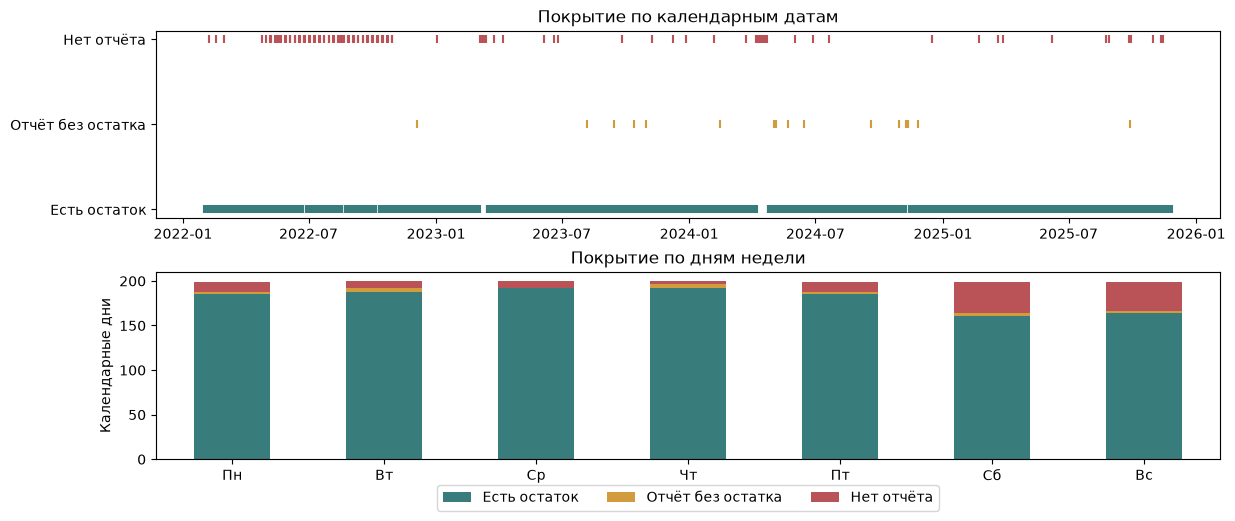


Валюта RUB


,Есть остаток,Отчёт без остатка,Нет отчёта,Дней,"Покрытие остатками, %"
День недели,,,,,
Пн,251,3,7,261,96.17
Вт,251,4,6,261,96.17
Ср,258,0,3,261,98.85
Чт,254,4,2,260,97.69
Пт,248,5,8,261,95.02
Сб,226,3,32,261,86.59
Вс,231,2,28,261,88.51


,Дней,Серий,"Максимум подряд, дней"
Тип пропуска,,,
Нет отчёта,86,51,9
Отчёт без остатка,21,18,4
Нет пригодного остатка,107,69,9


,Тип пропуска,Начало,Конец,Дней
0,Нет отчёта,2023-03-06,2023-03-14,9
1,Нет отчёта,2022-06-24,2022-06-26,3
2,Нет отчёта,2022-05-07,2022-05-08,2
3,Нет отчёта,2022-05-14,2022-05-15,2
4,Отчёт без остатка,2024-11-09,2024-11-12,4
5,Отчёт без остатка,2021-09-03,2021-09-03,1
6,Отчёт без остатка,2021-12-10,2021-12-10,1
7,Отчёт без остатка,2022-12-05,2022-12-05,1
8,Нет пригодного остатка,2023-03-06,2023-03-14,9
9,Нет пригодного остатка,2024-11-09,2024-11-12,4


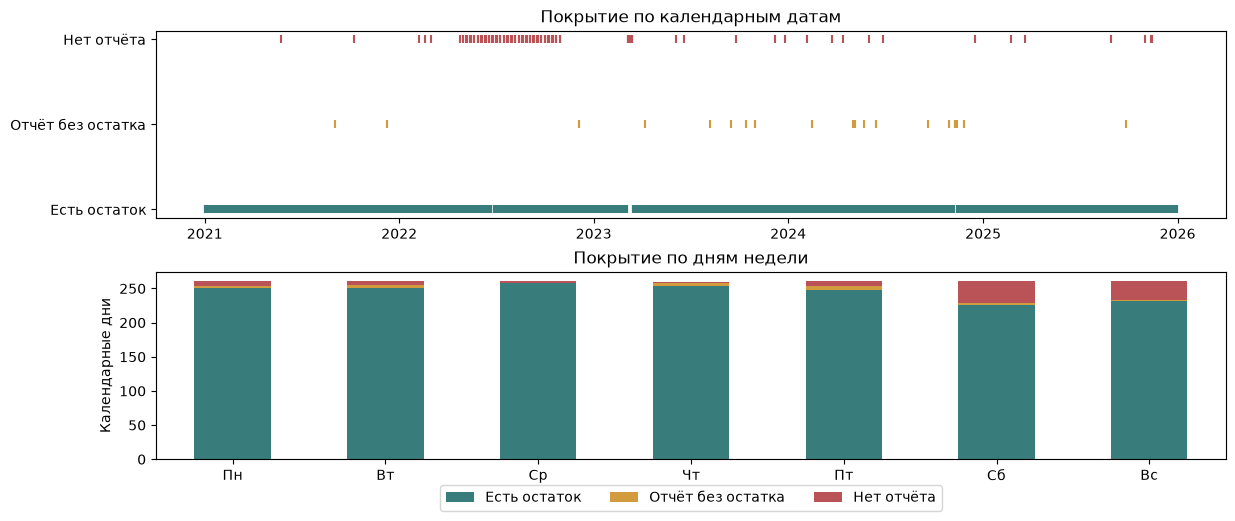


Валюта USD


,Есть остаток,Отчёт без остатка,Нет отчёта,Дней,"Покрытие остатками, %"
День недели,,,,,
Пн,222,3,10,235,94.47
Вт,220,4,12,236,93.22
Ср,228,0,8,236,96.61
Чт,227,4,5,236,96.19
Пт,222,5,9,236,94.07
Сб,197,3,35,235,83.83
Вс,203,2,30,235,86.38


,Дней,Серий,"Максимум подряд, дней"
Тип пропуска,,,
Нет отчёта,109,65,10
Отчёт без остатка,21,18,4
Нет пригодного остатка,130,83,10


,Тип пропуска,Начало,Конец,Дней
0,Нет отчёта,2023-08-15,2023-08-24,10
1,Нет отчёта,2023-03-06,2023-03-14,9
2,Нет отчёта,2022-06-24,2022-06-26,3
3,Нет отчёта,2022-05-07,2022-05-08,2
4,Отчёт без остатка,2024-11-09,2024-11-12,4
5,Отчёт без остатка,2021-09-03,2021-09-03,1
6,Отчёт без остатка,2021-12-10,2021-12-10,1
7,Отчёт без остатка,2022-12-05,2022-12-05,1
8,Нет пригодного остатка,2023-08-15,2023-08-24,10
9,Нет пригодного остатка,2023-03-06,2023-03-14,9


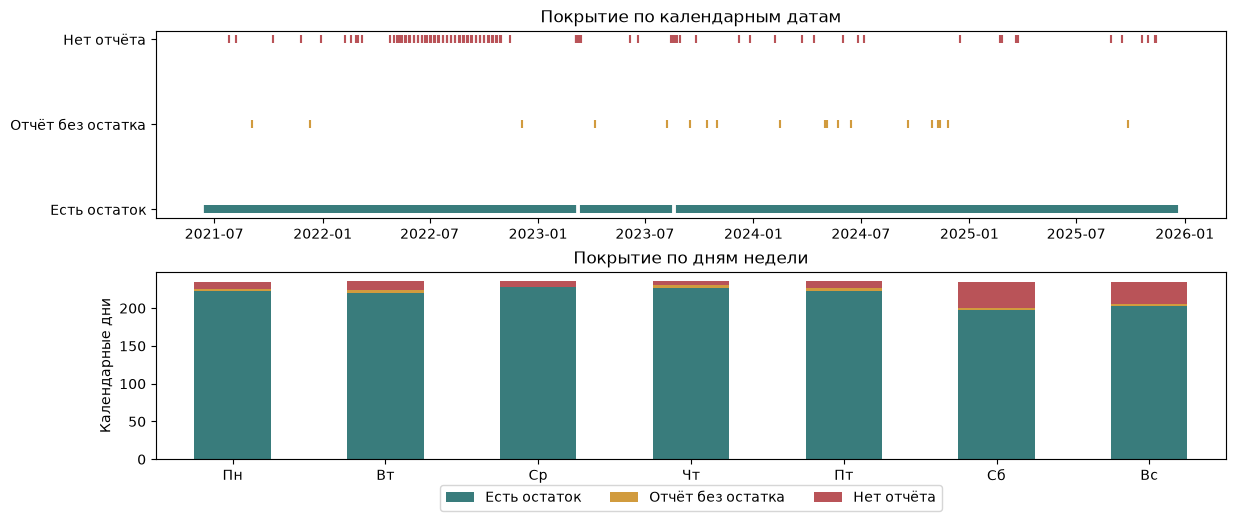

In [3]:
def show_coverage(calendar_status):
    day_index = calendar_status.index
    weekday_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
    status_cols = ["Есть остаток", "Отчёт без остатка", "Нет отчёта"]
    weekday_coverage = calendar_status[status_cols].groupby(day_index.day_of_week).sum()
    weekday_coverage = weekday_coverage.reindex(range(7), fill_value=0)
    weekday_coverage.index = pd.Index(weekday_names, name="День недели")
    weekday_coverage["Дней"] = weekday_coverage.sum(axis=1)
    weekday_coverage["Покрытие остатками, %"] = weekday_coverage["Есть остаток"].div(
        weekday_coverage["Дней"].replace(0, np.nan)
    ).mul(100)
    display(weekday_coverage.round(2))

    gap_summary = []
    long_gaps = []
    for label, mask in [
        ("Нет отчёта", calendar_status["Нет отчёта"]),
        ("Отчёт без остатка", calendar_status["Отчёт без остатка"]),
        ("Нет пригодного остатка", ~calendar_status["Есть остаток"]),
    ]:
        run_id = mask.ne(mask.shift(fill_value=False)).cumsum()
        gap_runs = calendar_status.index.to_series()[mask].groupby(run_id[mask]).agg(
            start="min", end="max", days="size"
        ).rename(columns={"start": "Начало", "end": "Конец", "days": "Дней"})
        gap_summary.append({
            "Тип пропуска": label,
            "Дней": int(mask.sum()),
            "Серий": len(gap_runs),
            "Максимум подряд, дней": int(gap_runs["Дней"].max()) if not gap_runs.empty else 0,
        })
        long_gaps.append(
            gap_runs.nlargest(4, "Дней").assign(**{"Тип пропуска": label})
        )
    display(pd.DataFrame(gap_summary).set_index("Тип пропуска"))
    long_gap_table = pd.concat(long_gaps, ignore_index=True)
    if not long_gap_table.empty:
        display(long_gap_table[["Тип пропуска", "Начало", "Конец", "Дней"]])

    fig, (ax_timeline, ax_weekday) = plt.subplots(2, 1, figsize=(12, 5), layout="constrained")
    status_colors = ["#397c7c", "#d19b3e", "#b95358"]
    for y, (label, color) in enumerate(zip(status_cols, status_colors)):
        covered_days = day_index[calendar_status[label]]
        ax_timeline.scatter(covered_days, np.full(len(covered_days), y), marker="|", s=28, color=color)
    ax_timeline.set(yticks=range(3), yticklabels=status_cols, title="Покрытие по календарным датам")
    weekday_coverage[status_cols].plot.bar(stacked=True, ax=ax_weekday, color=status_colors, rot=0)
    ax_weekday.set(xlabel="", ylabel="Календарные дни", title="Покрытие по дням недели")
    ax_weekday.legend(loc="upper center", bbox_to_anchor=(.5, -.1), ncol=3)
    plt.show()


for currency in iter_eda_currencies():
    show_coverage(status_by_currency[currency])

## Уровень `OST_VAL` и распределение

Единицы измерения берутся из входного `df_fl`. В расчётах участвуют доступные значения. Для процентов по знакам знаменатель — число дней с известным остатком. Каждый календарный день с пропуском остаётся на временной оси.


Валюта EUR


,OST_VAL
count,1267.000000
mean,60.284743
std,17.748884
min,12.310000
1%,30.769800
5%,34.400000
10%,37.168000
25%,43.360000
50%,60.540000
75%,76.055000


,Дней,"Доля, %"
Отрицательные,0,0.0
Нулевые,0,0.0
Положительные,1267,100.0


,Значение
Уникальных значений,1140.000000
IQR,32.695000
MAD от медианы,16.380000
Асимметрия,-0.015225
Эксцесс,-1.299233
"Дней вне границ Тьюки (1,5 IQR)",0.000000
Соседних дней с тем же остатком,1.000000


OST_VAL
Группа       REP_DT             
Минимальные  2022-02-17    12.31
             2022-02-16    17.15
             2022-09-27    25.50
             2022-10-04    26.17
             2022-10-24    26.67
Максимальные 2024-03-01    94.28
             2025-01-24    92.39
             2025-02-12    92.15
             2024-02-26    92.09
             2024-03-08    92.06

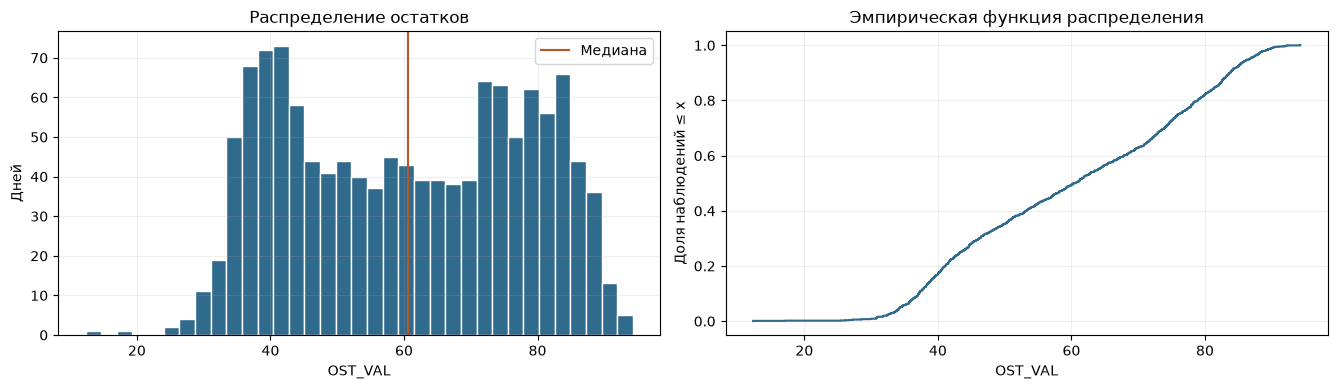


Валюта RUB


,OST_VAL
count,1719.000000
mean,6540.650006
std,503.729837
min,-83.000000
1%,5762.161000
5%,5835.933000
10%,5919.728000
25%,6137.805000
50%,6556.320000
75%,6982.680000


,Дней,"Доля, %"
Отрицательные,1,0.06
Нулевые,1,0.06
Положительные,1717,99.88


,Значение
Уникальных значений,1711.000000
IQR,844.875000
MAD от медианы,423.110000
Асимметрия,-2.648394
Эксцесс,32.116188
"Дней вне границ Тьюки (1,5 IQR)",2.000000
Соседних дней с тем же остатком,0.000000


OST_VAL
Группа       REP_DT             
Минимальные  2022-02-17   -83.00
             2022-02-16     0.00
             2021-01-02  5694.94
             2021-09-12  5704.28
             2021-09-19  5712.20
Максимальные 2025-02-28  7418.42
             2025-08-27  7400.20
             2024-12-31  7353.77
             2025-12-31  7317.26
             2025-12-30  7296.49

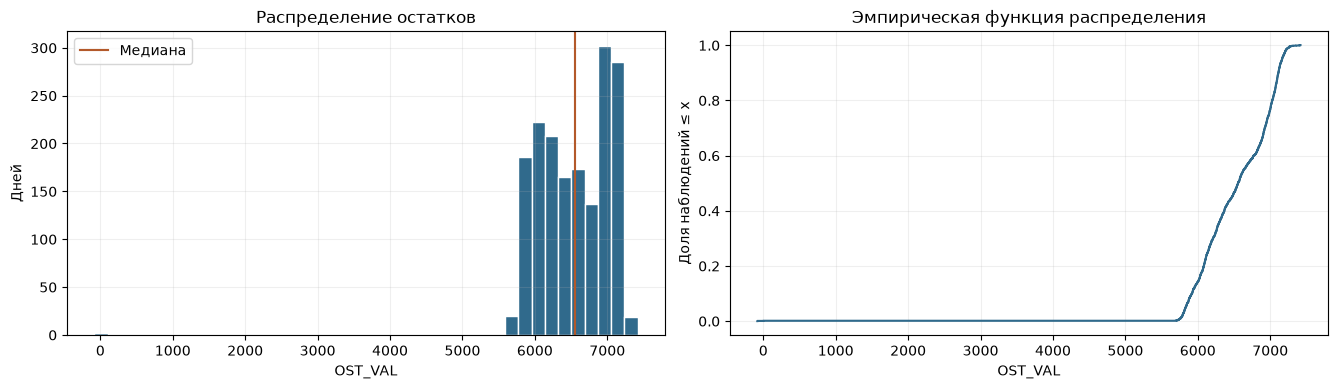


Валюта USD


,OST_VAL
count,1519.000000
mean,78.985945
std,12.199488
min,-13.680000
1%,57.716600
5%,61.315000
10%,63.726000
25%,69.390000
50%,78.830000
75%,87.985000


,Дней,"Доля, %"
Отрицательные,2,0.13
Нулевые,0,0.00
Положительные,1517,99.87


,Значение
Уникальных значений,1262.000000
IQR,18.595000
MAD от медианы,9.290000
Асимметрия,-0.430663
Эксцесс,3.089191
"Дней вне границ Тьюки (1,5 IQR)",2.000000
Соседних дней с тем же остатком,0.000000


OST_VAL
Группа       REP_DT             
Минимальные  2022-02-17   -13.68
             2022-02-16   -13.24
             2022-01-02    53.48
             2022-01-11    56.19
             2023-01-14    56.28
Максимальные 2025-06-03   104.09
             2024-05-17   103.76
             2024-05-14   103.66
             2025-05-06   103.36
             2025-06-06   103.10

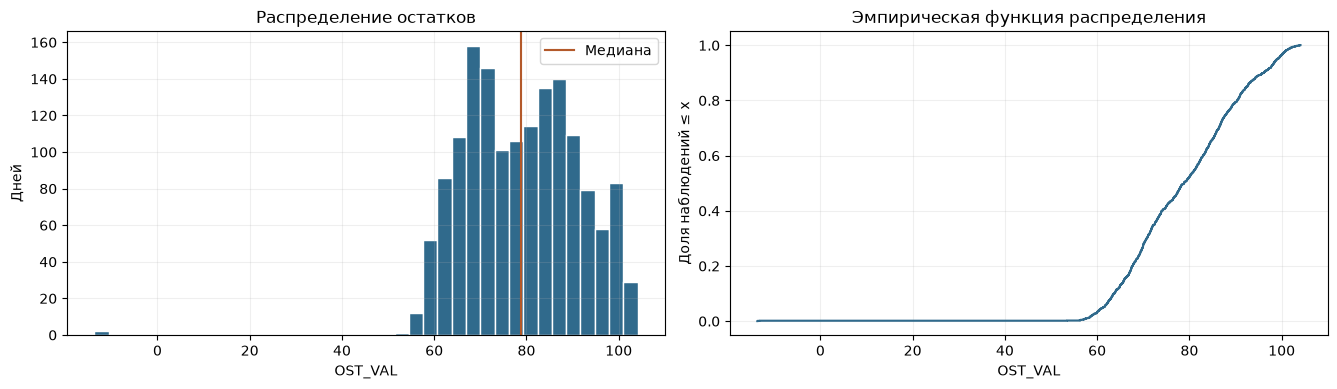

In [4]:
def show_level(eda_target):
    eda_observed = eda_target.dropna()
    eda_quantiles = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    display(eda_observed.describe(percentiles=eda_quantiles).rename("OST_VAL").to_frame())

    eda_sign = pd.Series({
        "Отрицательные": eda_observed.lt(0).sum(),
        "Нулевые": eda_observed.eq(0).sum(),
        "Положительные": eda_observed.gt(0).sum(),
    }, name="Дней")
    eda_sign_table = eda_sign.to_frame()
    eda_sign_table["Доля, %"] = eda_sign.div(len(eda_observed) or np.nan).mul(100)
    display(eda_sign_table.round(2))

    eda_median = eda_observed.median()
    eda_q25, eda_q75 = eda_observed.quantile([0.25, 0.75])
    eda_iqr = eda_q75 - eda_q25
    eda_level_stats = pd.Series({
        "Уникальных значений": eda_observed.nunique(),
        "IQR": eda_iqr,
        "MAD от медианы": (eda_observed - eda_median).abs().median(),
        "Асимметрия": eda_observed.skew(),
        "Эксцесс": eda_observed.kurt(),
        "Дней вне границ Тьюки (1,5 IQR)": (
            int((~eda_observed.between(eda_q25 - 1.5 * eda_iqr, eda_q75 + 1.5 * eda_iqr)).sum())
            if eda_iqr > 0 else np.nan
        ),
        "Соседних дней с тем же остатком": eda_target.eq(eda_target.shift()).sum(),
    }, name="Значение")
    display(eda_level_stats.to_frame())

    if not eda_observed.empty:
        eda_extremes = pd.concat({
            "Минимальные": eda_observed.nsmallest(5),
            "Максимальные": eda_observed.nlargest(5),
        }, names=["Группа", "REP_DT"])
        display(eda_extremes.to_frame())

        eda_bins = min(60, max(5, int(np.sqrt(len(eda_observed)))))
        eda_ordered = np.sort(eda_observed.to_numpy())
        eda_probs = np.arange(1, len(eda_ordered) + 1) / len(eda_ordered)
        fig, axes = plt.subplots(1, 2, figsize=(13, 3.7), constrained_layout=True)
        axes[0].hist(eda_observed, bins=eda_bins, color="#306a8c", edgecolor="white")
        axes[0].axvline(eda_median, color="#b3592a", linewidth=1.5, label="Медиана")
        axes[0].set(title="Распределение остатков", xlabel="OST_VAL", ylabel="Дней")
        axes[0].legend()
        axes[1].step(np.r_[eda_ordered[0], eda_ordered], np.r_[0, eda_probs], where="post", color="#306a8c")
        axes[1].set(title="Эмпирическая функция распределения", xlabel="OST_VAL", ylabel="Доля наблюдений ≤ x")
        for axis in axes:
            axis.grid(alpha=0.2)
        plt.show()
    else:
        print("Для графиков распределения нужны числовые значения OST_VAL.")


for currency in iter_eda_currencies():
    show_level(daily_by_currency[currency]["OST_VAL"])

## Динамика и покрытие по периодам

Скользящая медиана и межквартильный диапазон используют доступные значения за последние 30 календарных дней, включая дату на графике. Для дневного ряда остатка полезны среднее, медиана и последнее доступное значение периода. Покрытие внутри диапазона сравнивает число известных остатков с длиной доступной части периода, а покрытие полного периода также учитывает даты до и после границ ряда.


Валюта EUR


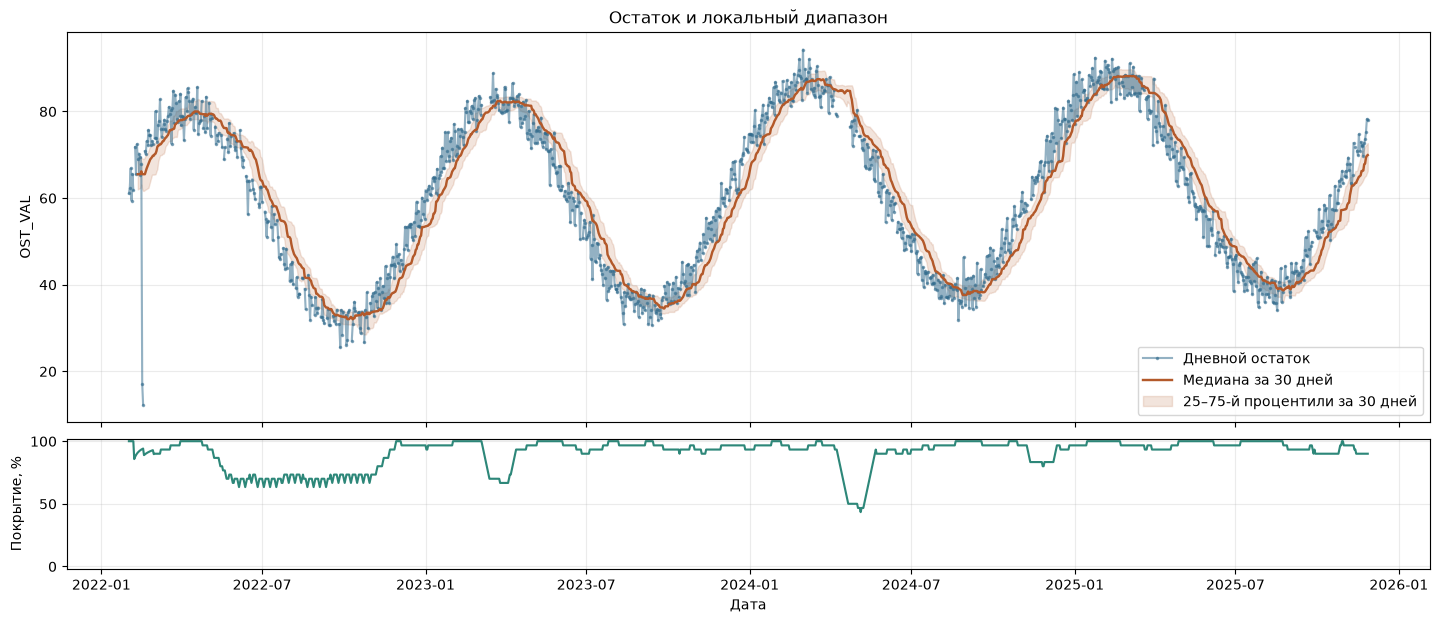

Месяцы. Последние 18 из 46


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2024-06,30,30,27,54.549259,54.090,4.203350,47.89,61.80,54.53,50.98,90.000000,90.000000,2024-06-02,2024-06-30,-11.71
2024-07,31,31,30,43.918667,42.875,3.793043,38.77,51.64,47.66,41.17,96.774194,96.774194,2024-07-01,2024-07-31,-9.81
2024-08,31,31,31,38.173548,37.480,2.631985,31.94,46.33,37.00,35.31,100.000000,100.000000,2024-08-01,2024-08-31,-5.86
2024-09,30,30,29,40.608276,41.200,3.548004,34.40,48.58,41.20,41.28,96.666667,96.666667,2024-09-01,2024-09-30,5.97
2024-10,31,31,30,49.634333,49.045,4.561007,41.20,58.07,47.91,56.11,96.774194,96.774194,2024-10-01,2024-10-31,14.83
2024-11,30,30,25,63.064400,63.980,4.408205,56.56,73.39,56.56,73.39,83.333333,83.333333,2024-11-01,2024-11-30,17.28
2024-12,31,31,30,76.021333,76.770,5.344394,66.24,88.58,74.37,88.58,96.774194,96.774194,2024-12-01,2024-12-31,15.19
2025-01,31,31,31,85.427742,85.910,3.321373,77.02,92.39,77.02,89.10,100.000000,100.000000,2025-01-01,2025-01-31,0.52
2025-02,28,28,27,87.556667,88.170,2.744658,82.11,92.15,85.31,88.21,96.428571,96.428571,2025-02-01,2025-02-28,-0.89


Кварталы. Последние 12 из 16


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2023Q1,90,90,79,74.300000,75.530,7.602367,59.61,88.82,61.74,85.66,87.777778,87.777778,2023-01-01,2023-03-31,30.43
2023Q2,91,91,87,70.520345,72.710,9.557802,50.49,86.56,85.13,54.26,95.604396,95.604396,2023-04-01,2023-06-30,-31.40
2023Q3,92,92,89,39.543596,38.250,5.707517,30.68,55.97,50.59,40.56,96.739130,96.739130,2023-07-01,2023-09-30,-13.70
2023Q4,92,92,87,52.334828,51.550,11.303105,35.52,74.68,35.67,74.68,94.565217,94.565217,2023-10-01,2023-12-31,34.12
2024Q1,91,91,88,83.245000,84.035,4.946246,72.18,94.28,74.70,87.93,96.703297,96.703297,2024-01-01,2024-03-31,13.25
2024Q2,91,91,70,65.303714,64.920,10.485899,47.89,85.99,85.99,50.98,76.923077,76.923077,2024-04-01,2024-06-30,-36.95
2024Q3,92,92,90,40.873111,40.270,4.083035,31.94,51.64,47.66,41.28,97.826087,97.826087,2024-07-01,2024-09-30,-9.70
2024Q4,92,92,85,62.897412,63.980,12.121932,41.20,88.58,47.91,88.58,92.391304,92.391304,2024-10-01,2024-12-31,47.30
2025Q1,90,90,87,85.701264,85.790,3.600650,72.21,92.39,77.02,87.59,96.666667,96.666667,2025-01-01,2025-03-31,-0.99


Годы. Последние 4 из 4


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2022,365,334,273,56.233773,55.220,18.316234,12.31,85.58,61.05,55.23,81.736527,74.794521,2022-02-01,2022-12-31,NaN
2023,365,365,342,58.706082,60.735,16.583960,30.68,88.82,61.74,74.68,93.698630,93.698630,2023-01-01,2023-12-31,19.45
2024,366,366,333,62.827868,63.980,17.702039,31.94,94.28,74.70,88.58,90.983607,90.983607,2024-01-01,2024-12-31,13.90
2025,365,331,319,62.789310,61.520,17.756160,34.10,92.39,77.02,77.94,96.374622,87.397260,2025-01-01,2025-11-27,-10.64


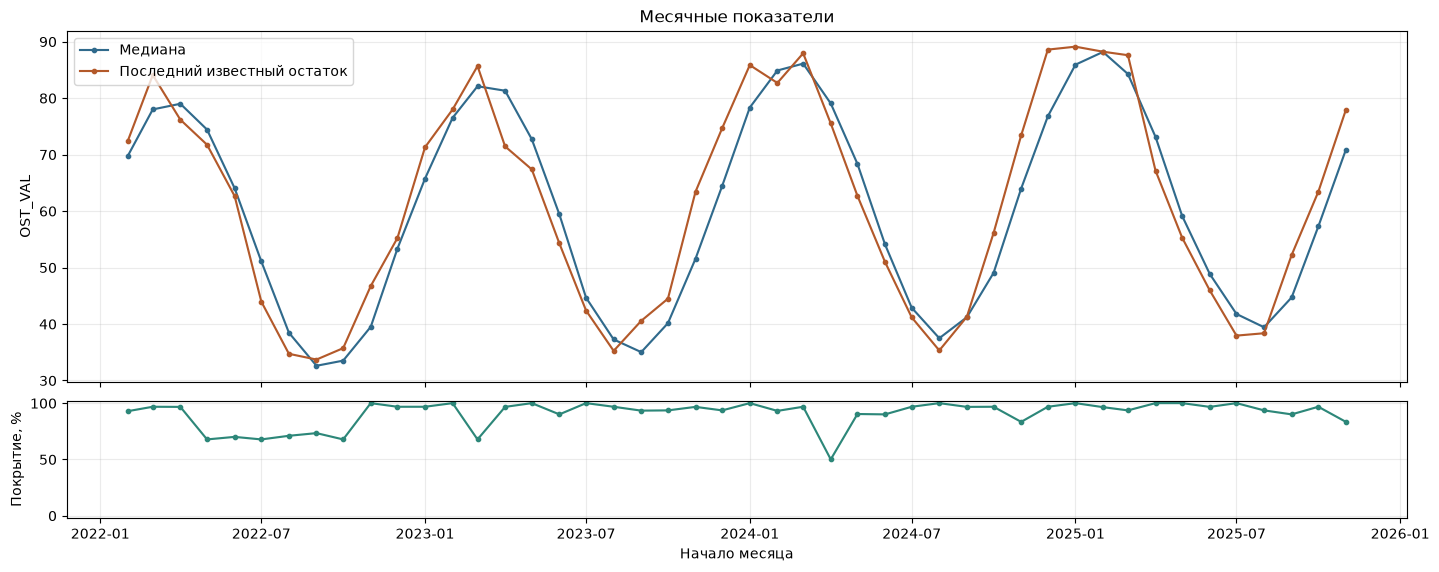


Валюта RUB


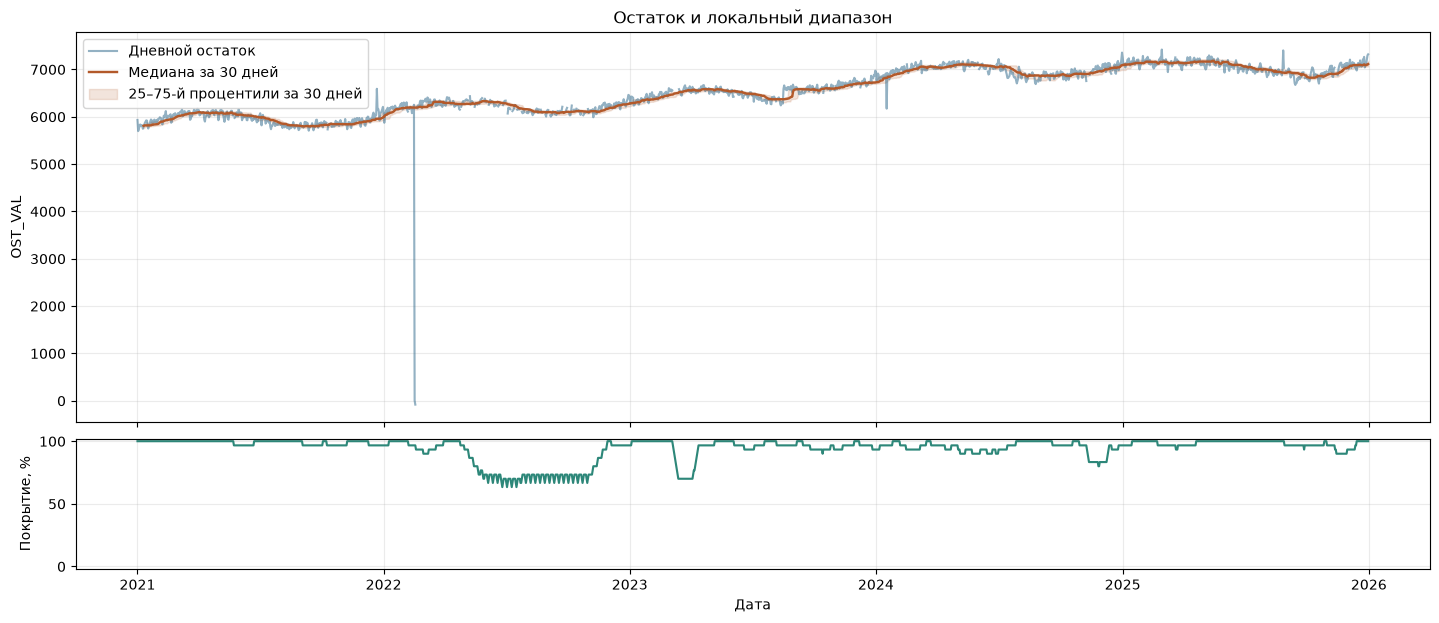

Месяцы. Последние 18 из 60


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2024-07,31,31,31,6935.627419,6933.540,126.272871,6702.90,7217.32,7217.32,7055.26,100.000000,100.000000,2024-07-01,2024-07-31,-102.10
2024-08,31,31,31,6841.033871,6863.070,77.098367,6688.93,6994.77,6994.77,6786.19,100.000000,100.000000,2024-08-01,2024-08-31,-269.07
2024-09,30,30,29,6875.698966,6876.580,50.957965,6760.55,6958.70,6760.55,6902.22,96.666667,96.666667,2024-09-01,2024-09-30,116.03
2024-10,31,31,30,6899.818333,6913.300,71.211836,6763.56,7020.26,6961.06,6962.27,96.774194,96.774194,2024-10-01,2024-10-31,60.05
2024-11,30,30,25,6948.166800,6957.460,79.188185,6753.29,7076.87,6902.02,6952.75,83.333333,83.333333,2024-11-01,2024-11-30,-9.52
2024-12,31,31,30,7063.978000,7084.265,100.233920,6906.77,7353.77,6954.68,7353.77,96.774194,96.774194,2024-12-01,2024-12-31,401.02
2025-01,31,31,31,7145.973871,7133.760,65.397194,6998.19,7283.64,7246.34,7283.64,100.000000,100.000000,2025-01-01,2025-01-31,-70.13
2025-02,28,28,27,7161.231481,7159.350,82.163335,7017.66,7418.42,7128.36,7418.42,96.428571,96.428571,2025-02-01,2025-02-28,134.78
2025-03,31,31,30,7125.669333,7136.155,67.768644,6942.37,7251.84,7140.99,7139.33,96.774194,96.774194,2025-03-01,2025-03-31,-279.09


Кварталы. Последние 12 из 20


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2023Q1,90,90,81,6445.802840,6440.160,102.668355,6234.40,6662.67,6368.02,6642.56,90.000000,90.000000,2023-01-01,2023-03-31,193.82
2023Q2,91,91,88,6531.916818,6532.150,60.515229,6387.89,6666.78,6522.83,6514.27,96.703297,96.703297,2023-04-01,2023-06-30,-128.29
2023Q3,92,92,89,6470.258539,6474.560,120.955349,6238.68,6677.46,6451.93,6605.51,96.739130,96.739130,2023-07-01,2023-09-30,91.24
2023Q4,92,92,88,6674.308750,6675.780,87.894743,6490.24,6972.31,6506.65,6972.31,95.652174,95.652174,2023-10-01,2023-12-31,366.80
2024Q1,91,91,88,6971.202955,6989.150,126.994849,6170.38,7180.20,6951.73,7030.93,96.703297,96.703297,2024-01-01,2024-03-31,58.62
2024Q2,91,91,84,7077.871548,7078.420,61.276006,6890.79,7200.95,7028.23,7157.36,92.307692,92.307692,2024-04-01,2024-06-30,126.43
2024Q3,92,92,91,6884.305165,6876.580,98.388321,6688.93,7217.32,7217.32,6902.22,98.913043,98.913043,2024-07-01,2024-09-30,-255.14
2024Q4,92,92,85,6971.977176,6961.380,109.828018,6753.29,7353.77,6961.06,7353.77,92.391304,92.391304,2024-10-01,2024-12-31,451.55
2025Q1,90,90,88,7143.733182,7138.455,72.335576,6942.37,7418.42,7246.34,7139.33,97.777778,97.777778,2025-01-01,2025-03-31,-214.44


Годы. Последние 5 из 5


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2021,365,365,361,5938.660859,5928.430,121.796801,5694.94,6589.36,5931.00,6207.76,98.904110,98.904110,2021-01-01,2021-12-31,NaN
2022,365,365,306,6168.236536,6207.925,514.506640,-83.00,6460.57,6063.65,6448.74,83.835616,83.835616,2022-01-01,2022-12-31,240.98
2023,365,365,346,6532.112399,6538.960,130.158070,6234.40,6972.31,6368.02,6972.31,94.794521,94.794521,2023-01-01,2023-12-31,523.57
2024,366,366,348,6974.416379,6984.015,122.869018,6170.38,7353.77,6951.73,7353.77,95.081967,95.081967,2024-01-01,2024-12-31,381.46
2025,365,365,358,7052.605084,7074.240,131.495513,6670.93,7418.42,7246.34,7317.26,98.082192,98.082192,2025-01-01,2025-12-31,-36.51


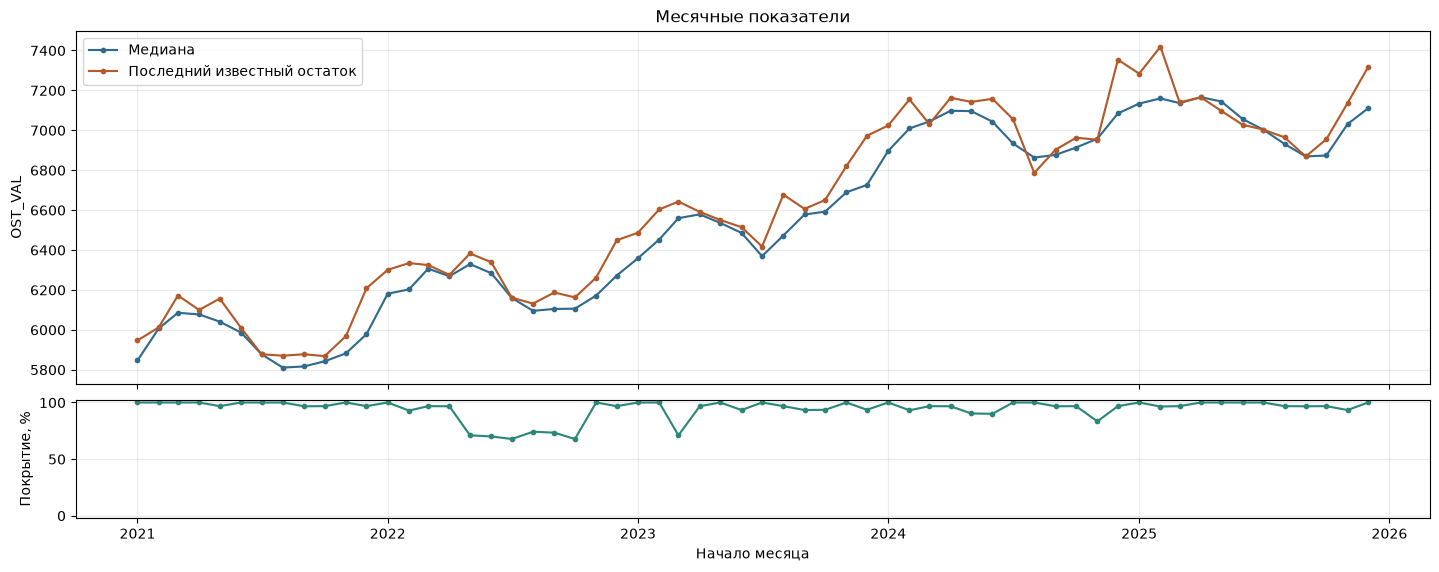


Валюта USD


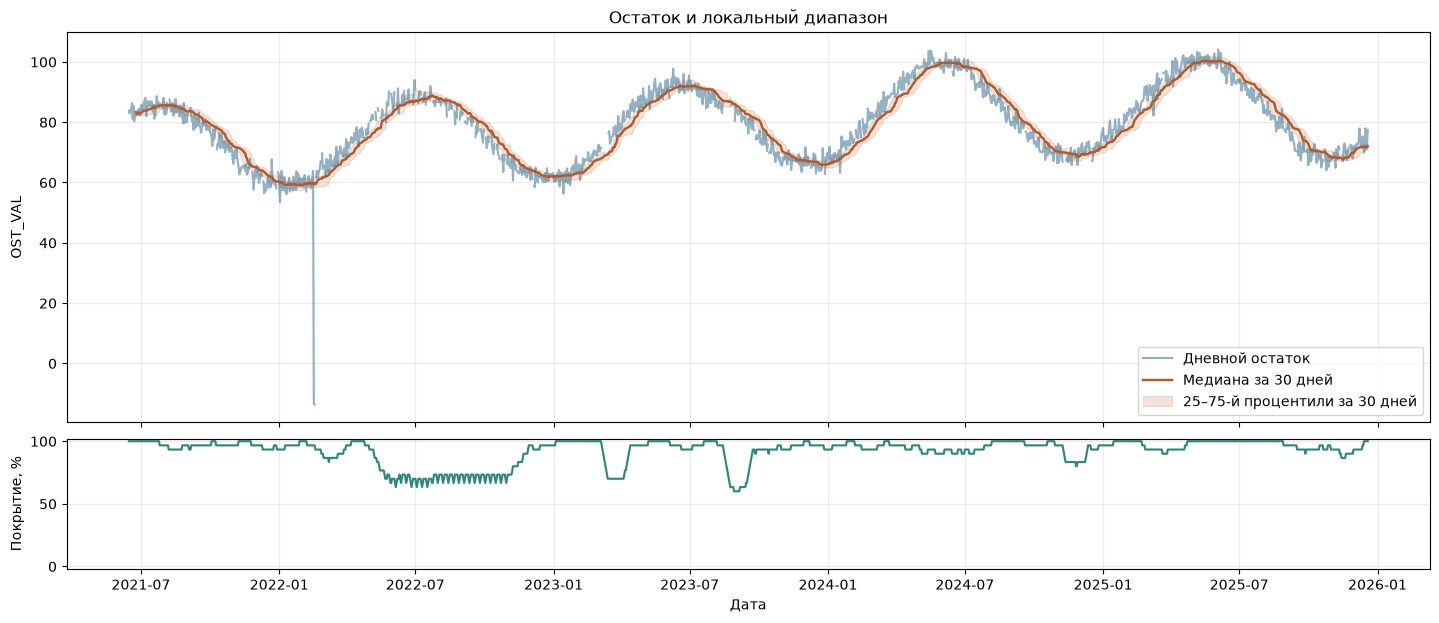

Месяцы. Последние 18 из 55


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2024-07,31,31,30,93.839333,93.055,3.246720,88.24,100.76,98.23,92.33,96.774194,96.774194,2024-07-01,2024-07-31,-8.72
2024-08,31,31,31,85.762581,86.350,3.381632,78.96,92.05,92.05,78.96,100.000000,100.000000,2024-08-01,2024-08-31,-13.37
2024-09,30,30,29,78.008966,77.880,2.488599,73.60,84.43,80.18,77.42,96.666667,96.666667,2024-09-01,2024-09-30,-1.54
2024-10,31,31,30,70.925000,70.445,1.787994,67.09,75.00,72.82,70.34,96.774194,96.774194,2024-10-01,2024-10-31,-7.08
2024-11,30,30,25,68.762800,68.520,2.014896,65.77,72.81,66.41,68.87,83.333333,83.333333,2024-11-01,2024-11-30,-1.47
2024-12,31,31,30,71.551667,71.630,2.245400,67.14,76.66,70.05,76.66,96.774194,96.774194,2024-12-01,2024-12-31,7.79
2025-01,31,31,31,77.431290,77.350,2.391907,73.43,82.63,78.06,82.00,100.000000,100.000000,2025-01-01,2025-01-31,5.34
2025-02,28,28,26,85.053846,84.420,2.832062,80.49,92.16,80.49,92.16,92.857143,92.857143,2025-02-01,2025-02-28,10.16
2025-03,31,31,29,92.190345,92.370,3.256858,82.19,97.12,87.13,94.22,93.548387,93.548387,2025-03-01,2025-03-31,2.06


Кварталы. Последние 12 из 19


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2023Q1,90,90,81,67.671605,67.070,5.909331,56.28,82.00,61.18,79.38,90.000000,90.000000,2023-01-01,2023-03-31,16.23
2023Q2,91,91,88,88.790227,89.410,4.234259,77.82,97.72,77.82,95.54,96.703297,96.703297,2023-04-01,2023-06-30,16.16
2023Q3,92,92,78,85.352436,85.795,4.992611,74.27,93.64,91.43,75.12,84.782609,84.782609,2023-07-01,2023-09-30,-20.42
2023Q4,92,92,88,68.494773,67.890,3.249881,62.87,77.24,74.86,69.67,95.652174,95.652174,2023-10-01,2023-12-31,-5.45
2024Q1,91,91,88,78.205227,77.790,7.279879,63.18,92.79,67.89,89.12,96.703297,96.703297,2024-01-01,2024-03-31,19.45
2024Q2,91,91,84,97.655595,98.145,3.221339,89.10,103.76,89.10,101.05,92.307692,92.307692,2024-04-01,2024-06-30,11.93
2024Q3,92,92,90,85.956444,86.435,7.125866,73.60,100.76,98.23,77.42,97.826087,97.826087,2024-07-01,2024-09-30,-23.63
2024Q4,92,92,85,70.510235,70.340,2.315567,65.77,76.66,72.82,76.66,92.391304,92.391304,2024-10-01,2024-12-31,-0.76
2025Q1,90,90,86,84.712674,84.175,6.805969,73.43,97.12,78.06,94.22,95.555556,95.555556,2025-01-01,2025-03-31,17.56


Годы. Последние 5 из 5


,days_full_period,days_in_range,observed,mean,median,std,minimum,maximum,first_balance,last_balance,coverage_in_range_pct,coverage_full_period_pct,first_date,last_date,change_between_period_ends
REP_DT,,,,,,,,,,,,,,,
2021,365,200,193,75.542228,78.490,9.414240,56.41,88.62,83.85,62.92,96.500000,52.876712,2021-06-15,2021-12-31,NaN
2022,365,365,302,71.937980,70.970,12.558459,-13.68,93.96,58.44,63.15,82.739726,82.739726,2022-01-01,2022-12-31,0.23
2023,365,365,335,77.552149,77.240,10.691399,56.28,97.72,61.18,69.67,91.780822,91.780822,2023-01-01,2023-12-31,6.52
2024,366,366,347,83.039135,81.750,11.347434,63.18,103.76,67.89,76.66,94.808743,94.808743,2024-01-01,2024-12-31,6.99
2025,365,353,342,84.444971,84.095,11.465774,64.06,104.09,78.06,77.35,96.883853,93.698630,2025-01-01,2025-12-19,0.69


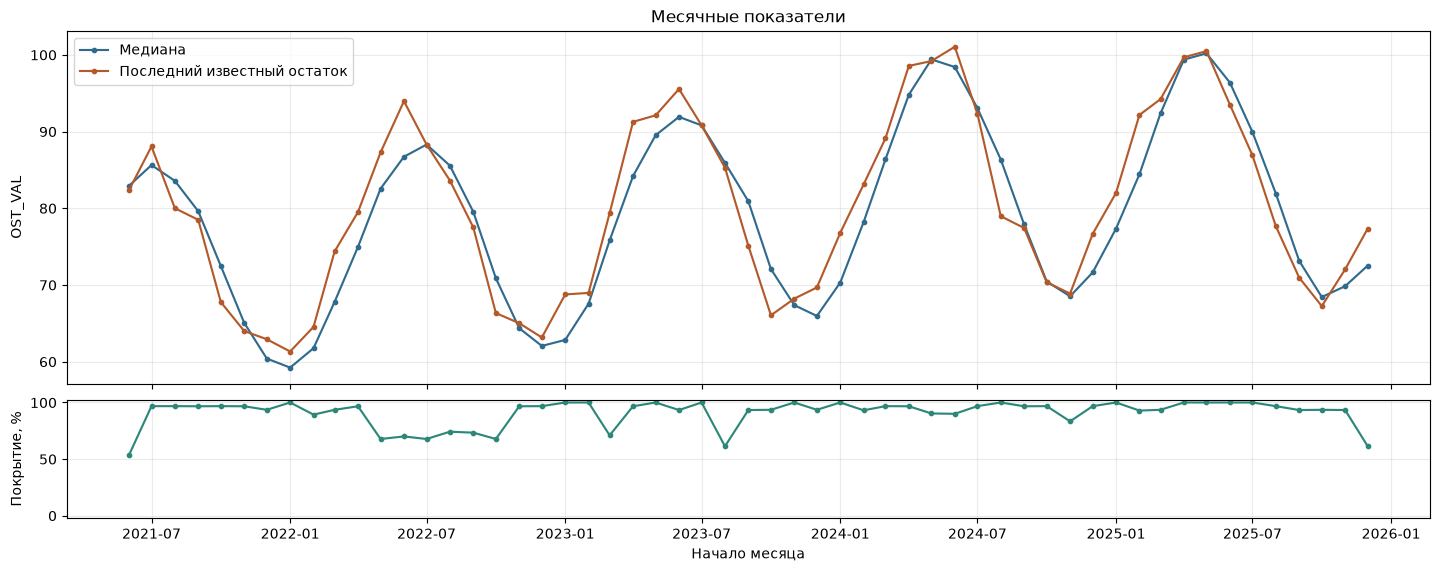

In [5]:
def balance_rolling_band(target):
    rolling = target.rolling(30, min_periods=10)
    return rolling.median(), rolling.quantile(0.25), rolling.quantile(0.75)


def show_dynamics(eda_target):
    eda_observed = eda_target.dropna()
    eda_rolling_level, eda_rolling_q25, eda_rolling_q75 = balance_rolling_band(eda_target)
    eda_rolling_coverage = eda_target.notna().rolling(30, min_periods=1).mean().mul(100)

    if not eda_observed.empty:
        fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, height_ratios=[3, 1], constrained_layout=True)
        axes[0].plot(eda_target, label="Дневной остаток", color="#306a8c", alpha=0.52, marker="." if len(eda_target) < 1600 else None, markersize=3)
        axes[0].plot(eda_rolling_level, label="Медиана за 30 дней", color="#b3592a", linewidth=1.7)
        axes[0].fill_between(
            eda_target.index, eda_rolling_q25.to_numpy(), eda_rolling_q75.to_numpy(),
            color="#b3592a", alpha=0.16, label="25–75-й процентили за 30 дней",
        )
        axes[0].set(title="Остаток и локальный диапазон", ylabel="OST_VAL")
        axes[0].legend()
        axes[1].plot(eda_rolling_coverage, color="#2d8779")
        axes[1].set(xlabel="Дата", ylabel="Покрытие, %", ylim=(-2, 102))
        for axis in axes:
            axis.grid(alpha=0.25)
        plt.show()

    def summarize_balance_periods(balance, frequency):
        '''Сводка остатков по календарным периодам с покрытием и датой последнего значения.'''
        periods = balance.index.to_period(frequency)
        summary = balance.groupby(periods).agg(
            days_in_range="size", observed="count", mean="mean", median="median", std="std",
            minimum="min", maximum="max", first_balance="first", last_balance="last",
        )
        full_days = (summary.index.end_time.normalize() - summary.index.start_time).days + 1
        summary.insert(0, "days_full_period", full_days)
        summary["coverage_in_range_pct"] = summary["observed"].div(summary["days_in_range"]).mul(100)
        summary["coverage_full_period_pct"] = summary["observed"].div(summary["days_full_period"]).mul(100)
        value_dates = pd.Series(balance.index, index=balance.index).where(balance.notna())
        summary["first_date"] = value_dates.groupby(periods).min()
        summary["last_date"] = value_dates.groupby(periods).max()
        summary["change_between_period_ends"] = summary["last_balance"].diff()
        return summary

    eda_monthly = summarize_balance_periods(eda_target, "M")
    eda_quarterly = summarize_balance_periods(eda_target, "Q")
    eda_yearly = summarize_balance_periods(eda_target, "Y")
    for eda_period_label, eda_period_stats, eda_period_limit in [
        ("Месяцы", eda_monthly, 18), ("Кварталы", eda_quarterly, 12), ("Годы", eda_yearly, 15),
    ]:
        print(f"{eda_period_label}. Последние {min(len(eda_period_stats), eda_period_limit)} из {len(eda_period_stats)}")
        display(eda_period_stats.tail(eda_period_limit))

    if not eda_monthly.empty:
        eda_month_dates = eda_monthly.index.to_timestamp()
        fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True, height_ratios=[3, 1], constrained_layout=True)
        axes[0].plot(eda_month_dates, eda_monthly["median"], label="Медиана", color="#306a8c", marker=".")
        axes[0].plot(eda_month_dates, eda_monthly["last_balance"], label="Последний известный остаток", color="#b3592a", marker=".")
        axes[0].set(title="Месячные показатели", ylabel="OST_VAL")
        axes[0].legend()
        axes[1].plot(eda_month_dates, eda_monthly["coverage_full_period_pct"], color="#2d8779", marker=".")
        axes[1].set(xlabel="Начало месяца", ylabel="Покрытие, %", ylim=(-2, 102))
        for axis in axes:
            axis.grid(alpha=0.25)
        plt.show()


for currency in iter_eda_currencies():
    show_dynamics(daily_by_currency[currency]["OST_VAL"])

## Изменения за 1, 7, 30, 90 и 365 дней

Для горизонта `h` берутся значения на датах `t` и `t − h`. Пропуски в любой из этих дат исключают пару. Изменение в единицах `OST_VAL` равно разности. Обычный процент доступен при положительной базе. Нормирование на модуль базы позволяет определить направление изменения при отрицательной базе. Логарифмическое изменение определено для двух положительных значений. При близкой к нулю базе процент может быть очень большим. Величину минимального модуля базы можно настроить в ячейке.


Валюта EUR


Пар с известным остатком  ...      p95
Дней Показатель                                   ...         
1    delta                                  1189  ...   6.4560
     pct_positive_base                      1189  ...  12.2756
     pct_abs_base                           1189  ...  12.2756
     log_change                             1189  ...   0.1158
7    delta                                  1193  ...   7.4040
     pct_positive_base                      1193  ...  14.9318
     pct_abs_base                           1193  ...  14.9318
     log_change                             1193  ...   0.1392
30   delta                                  1119  ...  15.7560
     pct_positive_base                      1119  ...  33.8023
     pct_abs_base                           1119  ...  33.8023
     log_change                             1119  ...   0.2912
90   delta                                  1078  ...  37.3715
     pct_positive_base                      1078  ...  95.2022
     pct_abs_base                           1078  ...  95.2022
     log_change                             1078  ...   0.6689
365  delta                                   853  ...  14.5700
     pct_positive_base                       853  ...  31.3629
     pct_abs_base                            853  ...  31.3629
     log_change                              853  ...   0.2728

[20 rows x 11 columns]

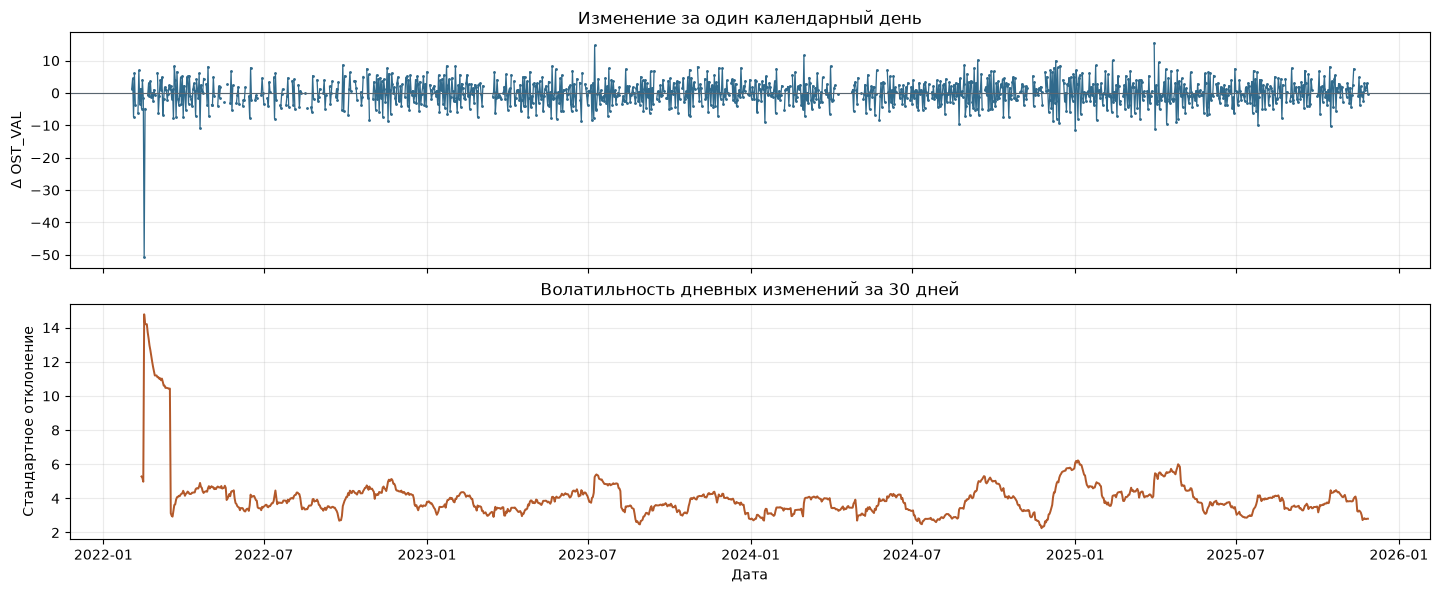


Валюта RUB


Пар с известным остатком  ...       p95
Дней Показатель                                   ...          
1    delta                                  1649  ...   99.9960
     pct_positive_base                      1649  ...    1.6239
     pct_abs_base                           1649  ...    1.6239
     log_change                             1649  ...    0.0161
7    delta                                  1658  ...  132.2390
     pct_positive_base                      1658  ...    2.0476
     pct_abs_base                           1658  ...    2.0600
     log_change                             1658  ...    0.0203
30   delta                                  1585  ...  227.3620
     pct_positive_base                      1585  ...    3.5344
     pct_abs_base                           1585  ...    3.5677
     log_change                             1585  ...    0.0348
90   delta                                  1542  ...  369.5315
     pct_positive_base                      1542  ...    5.8190
     pct_abs_base                           1542  ...    5.8547
     log_change                             1542  ...    0.0566
365  delta                                  1263  ...  591.9570
     pct_positive_base                      1263  ...    9.2577
     pct_abs_base                           1263  ...    9.2582
     log_change                             1263  ...    0.0885

[20 rows x 11 columns]

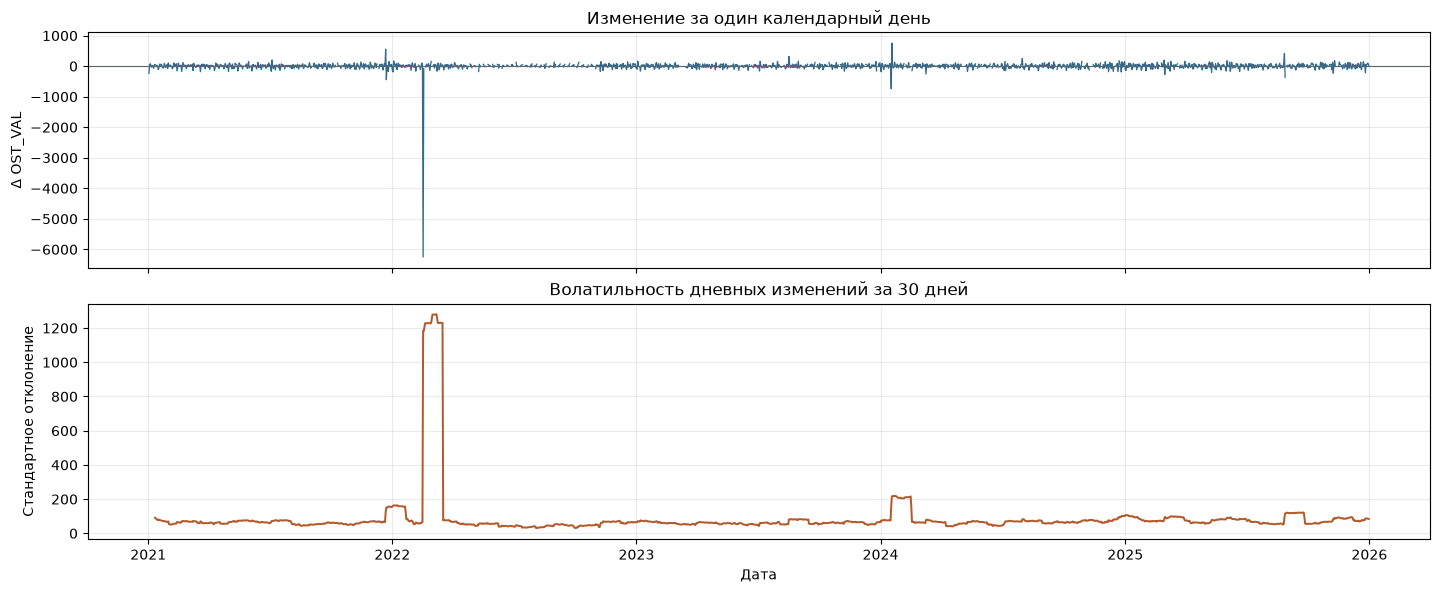


Валюта USD


Пар с известным остатком  ...      p95
Дней Показатель                                   ...         
1    delta                                  1435  ...   4.3830
     pct_positive_base                      1435  ...   5.9110
     pct_abs_base                           1435  ...   5.9098
     log_change                             1435  ...   0.0574
7    delta                                  1440  ...   4.8825
     pct_positive_base                      1440  ...   6.4920
     pct_abs_base                           1440  ...   6.5138
     log_change                             1440  ...   0.0629
30   delta                                  1365  ...   9.7920
     pct_positive_base                      1365  ...  13.2055
     pct_abs_base                           1365  ...  13.2274
     log_change                             1365  ...   0.1241
90   delta                                  1324  ...  23.5020
     pct_positive_base                      1324  ...  34.2545
     pct_abs_base                           1324  ...  34.4488
     log_change                             1324  ...   0.2946
365  delta                                  1071  ...  11.3750
     pct_positive_base                      1071  ...  15.8876
     pct_abs_base                           1071  ...  15.9821
     log_change                             1071  ...   0.1475

[20 rows x 11 columns]

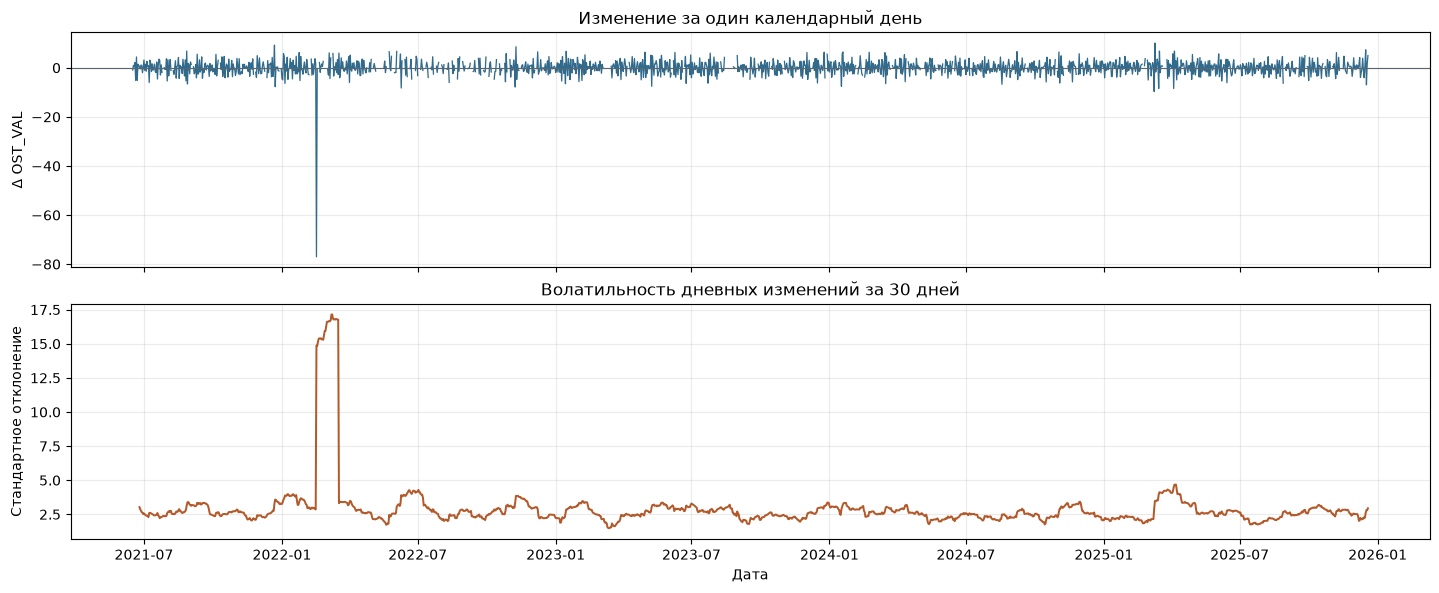

In [6]:
def show_changes(eda_target):
    EDA_CHANGE_HORIZONS = (1, 7, 30, 90, 365)
    EDA_MIN_ABS_BASE = 0.0  # В единицах OST_VAL. Проценты считаются при модуле базы строго выше порога.
    eda_log_level = np.log(eda_target.where(eda_target.gt(0)))
    eda_changes = {}
    eda_change_rows = []
    for eda_horizon in EDA_CHANGE_HORIZONS:
        eda_base = eda_target.shift(eda_horizon)
        eda_base_abs = eda_base.abs()
        eda_level_change = (eda_target - eda_base).replace([np.inf, -np.inf], np.nan)
        eda_relative_change = eda_level_change.div(eda_base.where(eda_base.gt(EDA_MIN_ABS_BASE))).mul(100)
        eda_abs_base_change = eda_level_change.div(eda_base_abs.where(eda_base_abs.gt(EDA_MIN_ABS_BASE))).mul(100)
        eda_changes[eda_horizon] = pd.DataFrame({
            "delta": eda_level_change,
            "pct_positive_base": eda_relative_change,
            "pct_abs_base": eda_abs_base_change,
            "log_change": eda_log_level - eda_log_level.shift(eda_horizon),
        }).replace([np.inf, -np.inf], np.nan)
        eda_has_pair = eda_target.notna() & eda_base.notna()
        for eda_metric, eda_values in eda_changes[eda_horizon].items():
            eda_present_change = eda_values.dropna()
            eda_change_rows.append({
                "Дней": eda_horizon,
                "Показатель": eda_metric,
                "Пар с известным остатком": int(eda_has_pair.sum()),
                "Пар для показателя": len(eda_present_change),
                "Пар с нулевой базой": int((eda_has_pair & eda_base.eq(0)).sum()),
                "Пар с отрицательной базой": int((eda_has_pair & eda_base.lt(0)).sum()),
                "Доля роста, %": eda_present_change.gt(0).mean() * 100,
                "Доля без изменений, %": eda_present_change.eq(0).mean() * 100,
                "Среднее": eda_present_change.mean(),
                "Стандартное отклонение": eda_present_change.std(),
                "p05": eda_present_change.quantile(0.05),
                "Медиана": eda_present_change.median(),
                "p95": eda_present_change.quantile(0.95),
            })

    eda_change_stats = pd.DataFrame(eda_change_rows).set_index(["Дней", "Показатель"])
    display(eda_change_stats.round(4))

    eda_delta_1d = eda_changes[1]["delta"]
    if eda_delta_1d.notna().any():
        fig, axes = plt.subplots(2, 1, figsize=(14, 5.7), sharex=True, constrained_layout=True)
        axes[0].plot(eda_delta_1d, color="#306a8c", linewidth=0.9, marker="." if len(eda_target) < 1600 else None, markersize=2)
        axes[0].axhline(0, color="#596670", linewidth=0.8)
        axes[0].set(title="Изменение за один календарный день", ylabel="Δ OST_VAL")
        axes[1].plot(eda_delta_1d.rolling(30, min_periods=10).std(), color="#b3592a", linewidth=1.4)
        axes[1].set(title="Волатильность дневных изменений за 30 дней", xlabel="Дата", ylabel="Стандартное отклонение")
        for axis in axes:
            axis.grid(alpha=0.25)
        plt.show()
    else:
        print("В ряду нет пары соседних календарных дат с двумя остатками.")


for currency in iter_eda_currencies():
    show_changes(daily_by_currency[currency]["OST_VAL"])

## Автокорреляция и сезонность

Лаг измеряется в календарных днях. Для каждого лага показано своё число пар с известными значениями. Корреляция считается от 10 полных пар при ненулевом разбросе обоих рядов. Высокая автокорреляция уровня может отражать общий тренд. Для сравнения приведена автокорреляция разностей за день. Лаги с разным покрытием могут описывать разные части истории.


Валюта EUR


Пар            Пирсон           Спирмен        
Ряд       Δ за день Уровень Δ за день Уровень Δ за день Уровень
Лаг, дней                                                      
1            1113.0  1189.0    -0.429   0.973    -0.491   0.969
2            1043.0  1160.0     0.020   0.964     0.037   0.966
3            1017.0  1160.0     0.021   0.960     0.014   0.963
5            1030.0  1149.0    -0.011   0.955     0.003   0.959
7            1072.0  1193.0    -0.006   0.952    -0.013   0.956
14           1068.0  1183.0    -0.023   0.928    -0.012   0.931
21           1056.0  1173.0     0.064   0.898     0.039   0.897
28           1049.0  1165.0     0.031   0.844     0.031   0.843
30           1004.0  1119.0     0.028   0.823     0.027   0.820
60            959.0  1094.0    -0.021   0.455    -0.020   0.453
90            958.0  1078.0     0.018  -0.038    -0.012  -0.035
180           894.0  1009.0    -0.048  -0.909    -0.039  -0.894
365           755.0   853.0     0.094   0.903     0.104   0.904
366           759.0   854.0    -0.066   0.896    -0.063   0.896

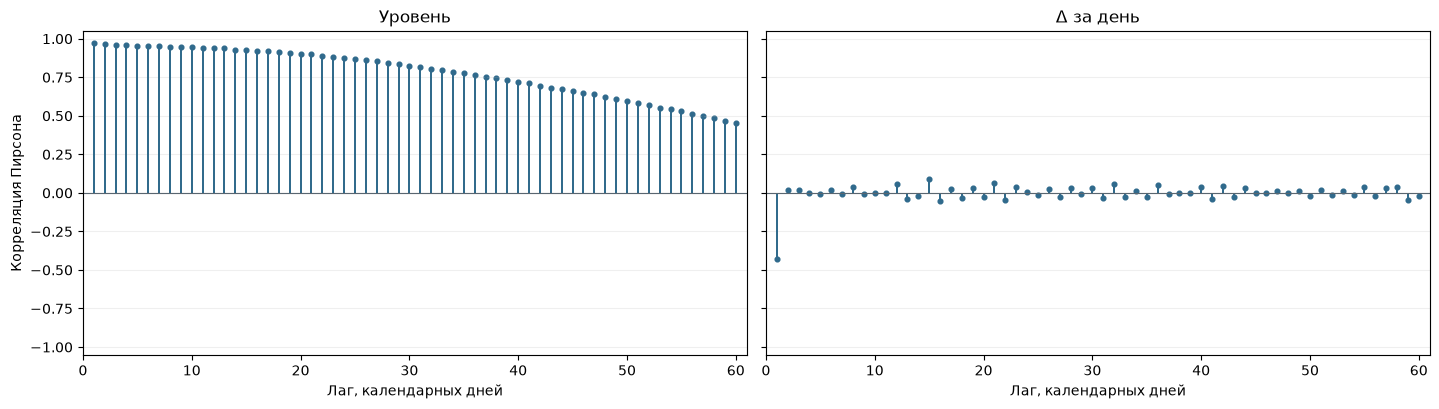


Валюта RUB


Пар            Пирсон           Спирмен        
Ряд       Δ за день Уровень Δ за день Уровень Δ за день Уровень
Лаг, дней                                                      
1            1580.0  1649.0    -0.042   0.942    -0.160   0.982
2            1512.0  1621.0    -0.105   0.836    -0.215   0.971
3            1483.0  1617.0    -0.019   0.799    -0.043   0.967
5            1501.0  1612.0    -0.035   0.795    -0.195   0.964
7            1547.0  1658.0     0.051   0.799     0.388   0.974
14           1543.0  1650.0     0.121   0.791     0.358   0.966
21           1532.0  1640.0     0.069   0.790     0.370   0.964
28           1522.0  1631.0     0.060   0.785     0.375   0.957
30           1472.0  1585.0    -0.024   0.775    -0.145   0.945
60           1425.0  1556.0     0.014   0.756     0.024   0.904
90           1426.0  1542.0    -0.007   0.729    -0.027   0.864
180          1323.0  1446.0    -0.080   0.660    -0.207   0.772
365          1145.0  1263.0     0.017   0.630     0.054   0.891
366          1146.0  1264.0    -0.034   0.629    -0.141   0.885

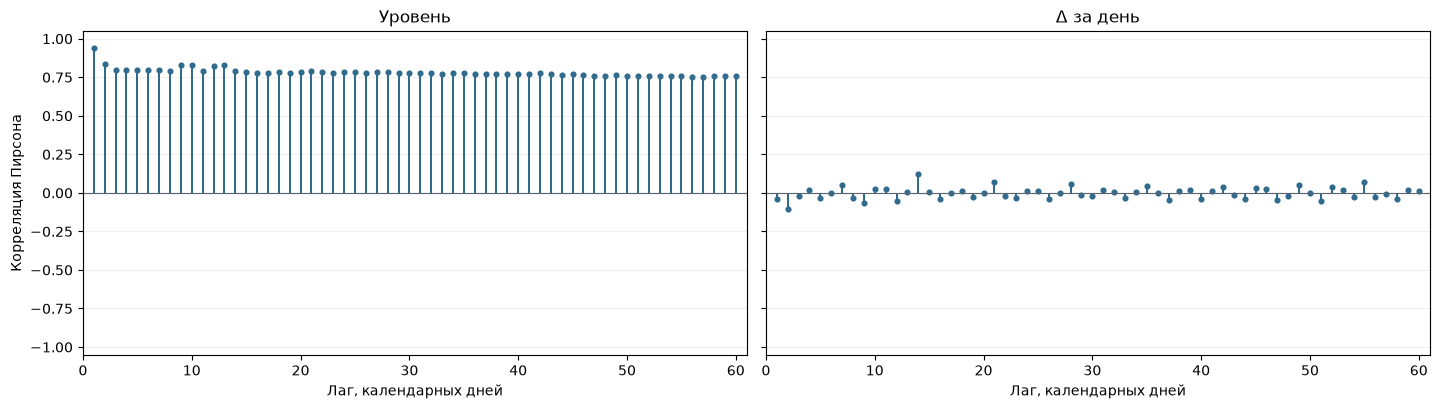


Валюта USD


Пар            Пирсон           Спирмен        
Ряд       Δ за день Уровень Δ за день Уровень Δ за день Уровень
Лаг, дней                                                      
1            1352.0  1435.0    -0.303   0.962    -0.450   0.974
2            1274.0  1406.0    -0.035   0.934    -0.022   0.973
3            1249.0  1405.0     0.033   0.923     0.038   0.973
5            1261.0  1395.0    -0.012   0.919    -0.004   0.968
7            1306.0  1440.0    -0.005   0.917     0.055   0.969
14           1298.0  1429.0     0.046   0.898     0.059   0.946
21           1287.0  1418.0    -0.017   0.868     0.026   0.916
28           1278.0  1410.0     0.012   0.830     0.032   0.873
30           1229.0  1365.0    -0.040   0.815    -0.035   0.859
60           1192.0  1341.0     0.035   0.526     0.030   0.550
90           1187.0  1324.0     0.018   0.120     0.044   0.114
180          1092.0  1232.0    -0.009  -0.645    -0.004  -0.708
365           952.0  1071.0    -0.044   0.872    -0.010   0.907
366           955.0  1074.0     0.046   0.869     0.021   0.903

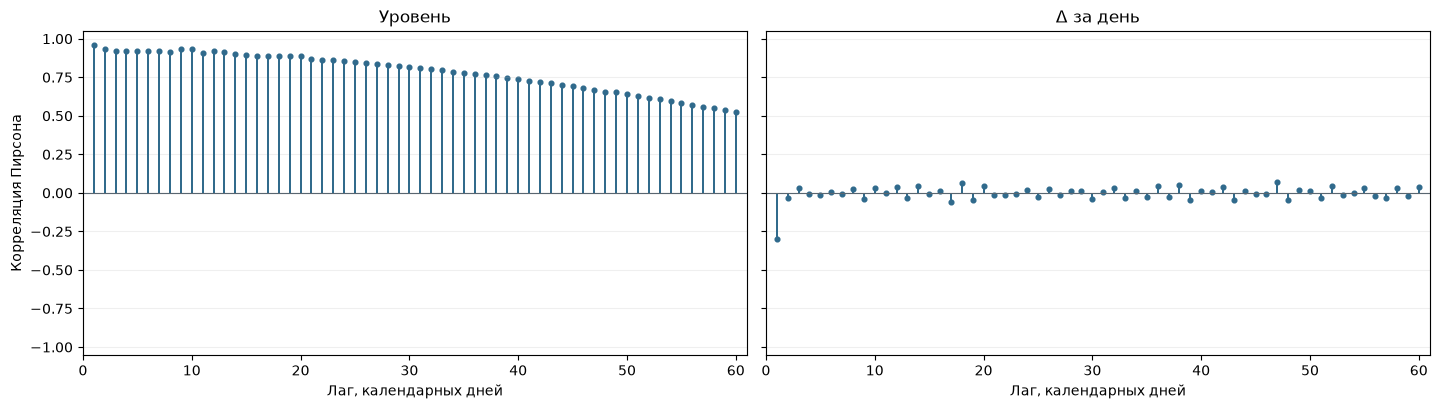

In [7]:
def show_autocorrelation(eda_target):
    eda_delta_1d = eda_target.diff().replace([np.inf, -np.inf], np.nan)
    EDA_LAGS_TO_DISPLAY = (1, 2, 3, 5, 7, 14, 21, 28, 30, 60, 90, 180, 365, 366)
    eda_diagnostic_lags = sorted(set(range(1, 61)).union(EDA_LAGS_TO_DISPLAY))
    eda_acf_rows = []
    for eda_series_label, eda_series in {"Уровень": eda_target, "Δ за день": eda_delta_1d}.items():
        for eda_lag in eda_diagnostic_lags:
            eda_pairs = pd.concat([eda_series, eda_series.shift(eda_lag)], axis=1, keys=["current", "previous"]).dropna()
            eda_corr_ready = len(eda_pairs) >= 10 and eda_pairs.nunique().min() > 1
            eda_acf_rows.append({
                "Ряд": eda_series_label,
                "Лаг, дней": eda_lag,
                "Пар": len(eda_pairs),
                "Пирсон": eda_pairs["current"].corr(eda_pairs["previous"]) if eda_corr_ready else np.nan,
                "Спирмен": (
                    eda_pairs["current"].rank().corr(eda_pairs["previous"].rank())
                    if eda_corr_ready and eda_lag in EDA_LAGS_TO_DISPLAY else np.nan
                ),
            })

    eda_lag_diagnostics = pd.DataFrame(eda_acf_rows)
    eda_lag_table = eda_lag_diagnostics.loc[eda_lag_diagnostics["Лаг, дней"].isin(EDA_LAGS_TO_DISPLAY)]
    display(eda_lag_table.pivot(index="Лаг, дней", columns="Ряд", values=["Пар", "Пирсон", "Спирмен"]).round(3))

    eda_short_lags = eda_lag_diagnostics.loc[eda_lag_diagnostics["Лаг, дней"].le(60)]
    if eda_short_lags["Пирсон"].notna().any():
        fig, axes = plt.subplots(1, 2, figsize=(14, 3.9), sharey=True, constrained_layout=True)
        for axis, (eda_series_label, eda_series_acf) in zip(axes, eda_short_lags.groupby("Ряд", sort=False)):
            eda_short_acf = eda_series_acf.dropna(subset=["Пирсон"])
            axis.vlines(eda_short_acf["Лаг, дней"], 0, eda_short_acf["Пирсон"], colors="#306a8c", linewidth=1.4)
            axis.scatter(eda_short_acf["Лаг, дней"], eda_short_acf["Пирсон"], color="#306a8c", s=11)
            axis.axhline(0, color="#596670", linewidth=0.8)
            axis.set(title=eda_series_label, xlabel="Лаг, календарных дней", xlim=(0, 61), ylim=(-1.05, 1.05))
            axis.grid(axis="y", alpha=0.2)
        axes[0].set_ylabel("Корреляция Пирсона")
        plt.show()


for currency in iter_eda_currencies():
    show_autocorrelation(daily_by_currency[currency]["OST_VAL"])

### Сезонные профили после удаления локального уровня

Для дня недели вычитается центрированная медиана за 35 дней, для месяца — за 183 дня. Центрированные окна используют будущие даты и применяются здесь для визуальной диагностики. Еженедельный профиль дополнительно разбит по годам, чтобы проверить повторяемость знака и масштаба. Пустые клетки означают, что данных для расчёта недостаточно.


Валюта EUR


,observed,median_level,residual_count,median_residual,residual_p25,residual_p75
День недели,,,,,,
Пн,185,60.150,185,-0.055,-1.850,1.460
Вт,188,60.075,188,-0.055,-1.609,1.733
Ср,192,60.390,192,0.030,-1.623,1.892
Чт,192,60.695,192,0.083,-1.529,2.045
Пт,185,59.260,185,0.350,-1.495,2.140
Сб,161,61.320,161,-0.245,-2.005,0.810
Вс,164,62.170,164,0.000,-2.054,1.594


,observed,median_level,residual_count,median_residual,residual_p25,residual_p75
Месяц,,,,,,
1,92,78.145,92,2.225,0.541,5.183
2,108,82.130,108,4.192,-1.547,7.670
3,110,83.455,110,5.805,3.385,8.385
4,103,78.060,103,3.565,0.770,6.915
5,111,69.470,111,1.370,0.040,3.777
6,104,55.595,104,0.348,-1.936,2.268
7,113,43.970,113,-2.060,-4.890,0.400
8,112,38.090,112,-6.183,-8.789,-3.805
9,106,38.140,106,-5.350,-8.111,-3.323


Число остатков после удаления локального уровня по годам и дням недели


,Пн,Вт,Ср,Чт,Пт,Сб,Вс
Год,,,,,,,
2022,44,47,46,48,46,22,20
2023,46,47,49,51,48,50,51
2024,49,47,50,45,49,46,47
2025,46,47,47,48,42,43,46


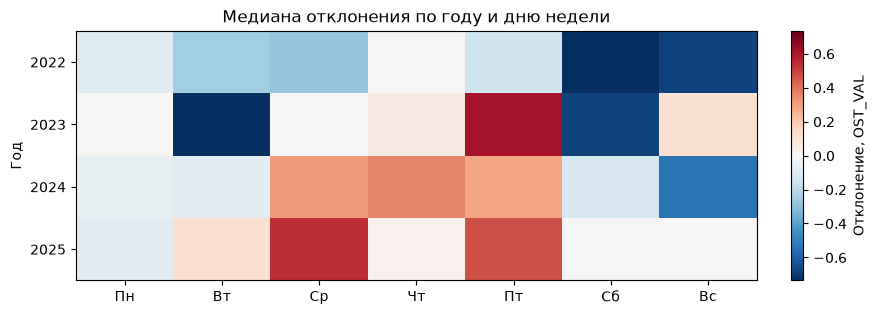


Валюта RUB


,observed,median_level,residual_count,median_residual,residual_p25,residual_p75
День недели,,,,,,
Пн,251,6558.070,251,0.550,-25.115,37.692
Вт,251,6549.620,251,3.970,-37.700,40.557
Ср,258,6532.145,258,10.060,-15.174,49.431
Чт,254,6548.605,254,19.185,-9.727,50.543
Пт,248,6572.945,248,46.815,13.194,73.869
Сб,226,6575.510,226,-38.095,-76.849,-7.874
Вс,231,6583.350,231,-51.960,-94.442,-20.493


,observed,median_level,residual_count,median_residual,residual_p25,residual_p75
Месяц,,,,,,
1,155,6354.490,155,-3.435,-73.162,39.588
2,136,6452.230,136,7.325,-37.490,48.468
3,143,6556.320,143,37.245,-10.597,78.005
4,147,6578.460,147,45.770,0.670,89.052
5,142,6549.925,142,42.635,4.880,93.286
6,136,6497.640,136,6.140,-32.809,45.879
7,145,6394.570,145,-32.170,-101.035,23.060
8,145,6577.340,145,-42.815,-94.195,-1.380
9,137,6601.230,137,-39.500,-83.320,7.405


Число остатков после удаления локального уровня по годам и дням недели


,Пн,Вт,Ср,Чт,Пт,Сб,Вс
Год,,,,,,,
2021,51,52,52,52,51,51,52
2022,49,51,52,52,50,27,25
2023,48,47,50,51,48,50,52
2024,51,49,52,47,51,48,50
2025,52,52,52,52,48,50,52


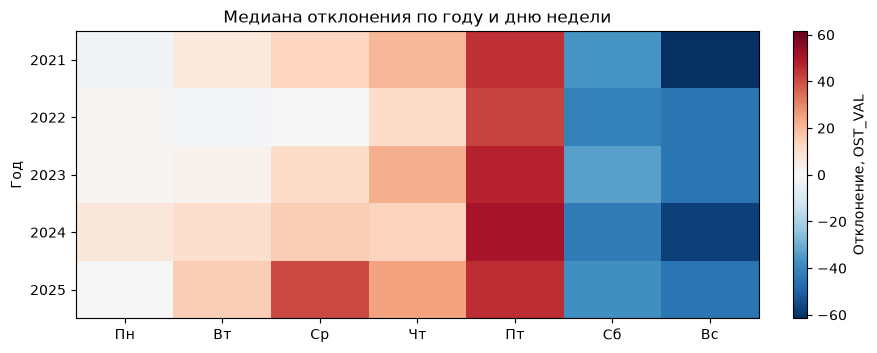


Валюта USD


,observed,median_level,residual_count,median_residual,residual_p25,residual_p75
День недели,,,,,,
Пн,222,79.750,222,0.035,-1.004,1.075
Вт,220,79.870,220,0.080,-1.215,1.345
Ср,228,79.205,228,0.038,-1.183,1.422
Чт,227,78.490,227,0.025,-0.990,1.562
Пт,222,79.720,222,0.400,-0.823,1.877
Сб,197,77.290,197,-0.360,-1.555,0.460
Вс,203,76.180,203,-0.595,-1.890,0.385


,observed,median_level,residual_count,median_residual,residual_p25,residual_p75
Месяц,,,,,,
1,124,66.415,124,-1.875,-3.963,-0.661
2,106,71.860,106,-0.002,-1.420,1.005
3,110,82.110,110,0.155,-1.184,1.520
4,117,89.320,117,2.090,0.220,4.040
5,111,97.740,111,4.920,3.470,6.290
6,122,93.455,122,3.810,2.119,6.155
7,143,89.180,143,2.355,0.102,3.710
8,133,84.340,133,0.470,-1.255,2.450
9,136,78.480,136,0.293,-1.082,1.926


Число остатков после удаления локального уровня по годам и дням недели


,Пн,Вт,Ср,Чт,Пт,Сб,Вс
Год,,,,,,,
2021,27,29,28,28,27,26,28
2022,48,50,51,52,50,26,25
2023,47,44,48,49,47,49,51
2024,51,49,52,47,51,48,49
2025,49,48,49,51,47,48,50


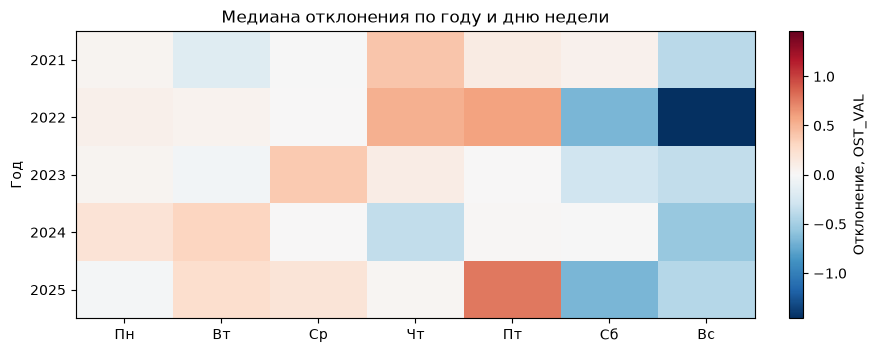

In [8]:
def show_seasonal_profiles(eda_target):
    eda_week_residual = eda_target - eda_target.rolling(35, center=True, min_periods=14).median()
    eda_month_residual = eda_target - eda_target.rolling(183, center=True, min_periods=60).median()
    eda_weekdays = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
    eda_season_tables = []
    for eda_label, eda_residual, eda_key, eda_season_index in [
        ("День недели", eda_week_residual, eda_target.index.day_of_week, pd.Index(range(7))),
        ("Месяц", eda_month_residual, eda_target.index.month, pd.Index(range(1, 13))),
    ]:
        eda_season_stats = pd.DataFrame({"OST_VAL": eda_target, "Отклонение": eda_residual}).groupby(eda_key).agg(
            observed=("OST_VAL", "count"),
            median_level=("OST_VAL", "median"),
            residual_count=("Отклонение", "count"),
            median_residual=("Отклонение", "median"),
            residual_p25=("Отклонение", lambda values: values.quantile(0.25)),
            residual_p75=("Отклонение", lambda values: values.quantile(0.75)),
        ).reindex(eda_season_index)
        eda_season_stats[["observed", "residual_count"]] = eda_season_stats[["observed", "residual_count"]].fillna(0).astype(int)
        if eda_label == "День недели":
            eda_season_stats.index = eda_weekdays
        eda_season_stats.index.name = eda_label
        eda_season_tables.append(eda_season_stats)
        display(eda_season_stats.round(3))

    eda_weekday_by_year = eda_week_residual.groupby([eda_target.index.year, eda_target.index.day_of_week]).agg(["count", "median"])
    if not eda_weekday_by_year.empty:
        eda_year_week_profile = eda_weekday_by_year["median"].where(eda_weekday_by_year["count"].ge(4)).unstack().reindex(columns=range(7)).tail(15)
        eda_year_week_count = eda_weekday_by_year["count"].unstack().reindex(columns=range(7)).reindex(index=eda_year_week_profile.index)
        eda_year_week_count.columns = eda_weekdays
        eda_year_week_count.index.name = "Год"
        print("Число остатков после удаления локального уровня по годам и дням недели")
        display(eda_year_week_count.fillna(0).astype(int))
        if eda_year_week_profile.notna().any().any():
            eda_color_limit = np.nanmax(np.abs(eda_year_week_profile.to_numpy())) or 1.0
            fig, ax = plt.subplots(figsize=(8.5, min(9, max(2.5, 1.5 + 0.37 * len(eda_year_week_profile)))), constrained_layout=True)
            eda_heatmap = ax.imshow(np.ma.masked_invalid(eda_year_week_profile.to_numpy()), aspect="auto", cmap="RdBu_r", vmin=-eda_color_limit, vmax=eda_color_limit)
            ax.set_xticks(range(7), eda_weekdays)
            ax.set_yticks(range(len(eda_year_week_profile)), eda_year_week_profile.index)
            ax.set(title="Медиана отклонения по году и дню недели", ylabel="Год")
            fig.colorbar(eda_heatmap, ax=ax, label="Отклонение, OST_VAL")
            plt.show()


for currency in iter_eda_currencies():
    show_seasonal_profiles(daily_by_currency[currency]["OST_VAL"])

### Декомпозиция и стационарность непрерывного отрезка

При наличии `statsmodels` недельная STL-декомпозиция использует самый длинный непрерывный отрезок с известными значениями. Для ADF нулевая гипотеза — наличие единичного корня, для KPSS — стационарность относительно постоянного уровня. Результат относится к указанному отрезку. p-значение KPSS ограничено диапазоном табличных значений. Для рядов с разрывами выше доступны профили и лаговые корреляции без интерполяции.


Валюта EUR
Непрерывный отрезок 2025-06-08 — 2025-08-23. Дней в отрезке 77.
Отрезок для расчёта 2025-06-08 — 2025-08-23.


,Тренд,Сезонность,Остаток
std,3.788,1.662,2.037
median,41.154,-0.026,0.074
min,38.441,-4.269,-7.003
max,49.362,3.989,6.604


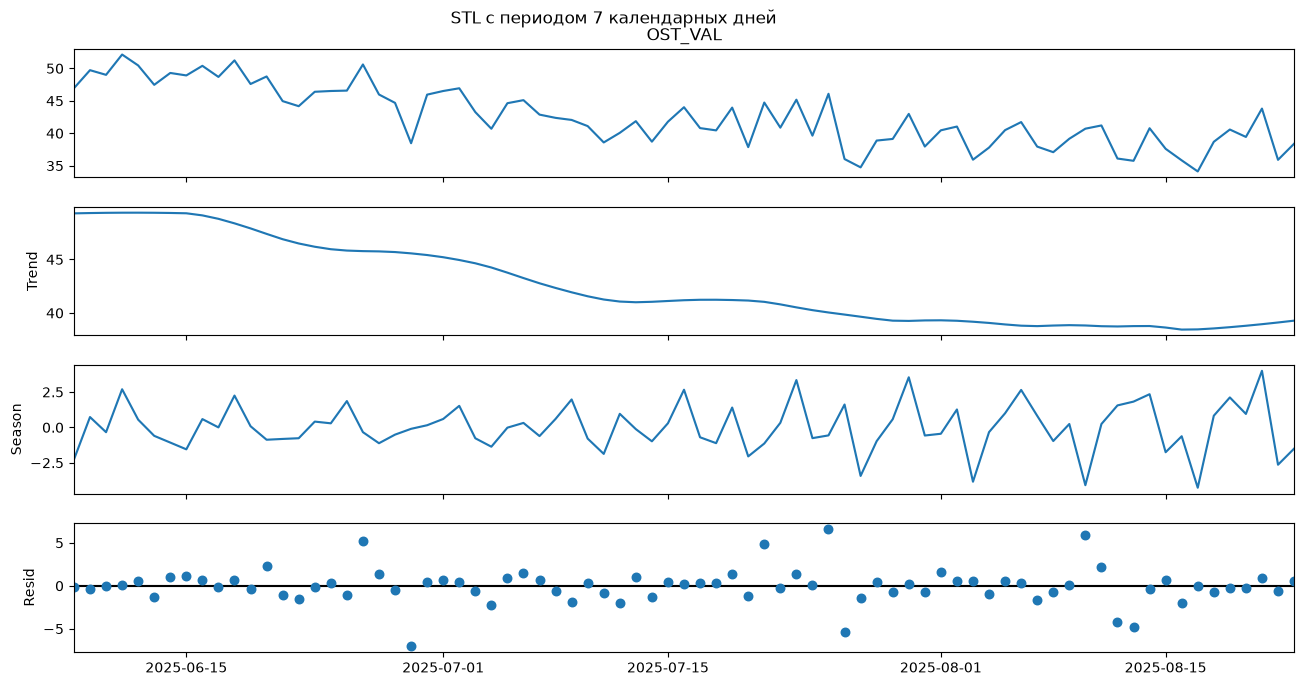

Для отчёта ADF и KPSS используется от 100 подряд идущих наблюдений.

Валюта RUB
Непрерывный отрезок 2025-03-22 — 2025-08-28. Дней в отрезке 160.
Отрезок для расчёта 2025-03-22 — 2025-08-28.


,Тренд,Сезонность,Остаток
std,82.553,39.815,52.817
median,7067.741,6.894,-0.537
min,6928.448,-80.290,-170.436
max,7199.806,83.452,333.137


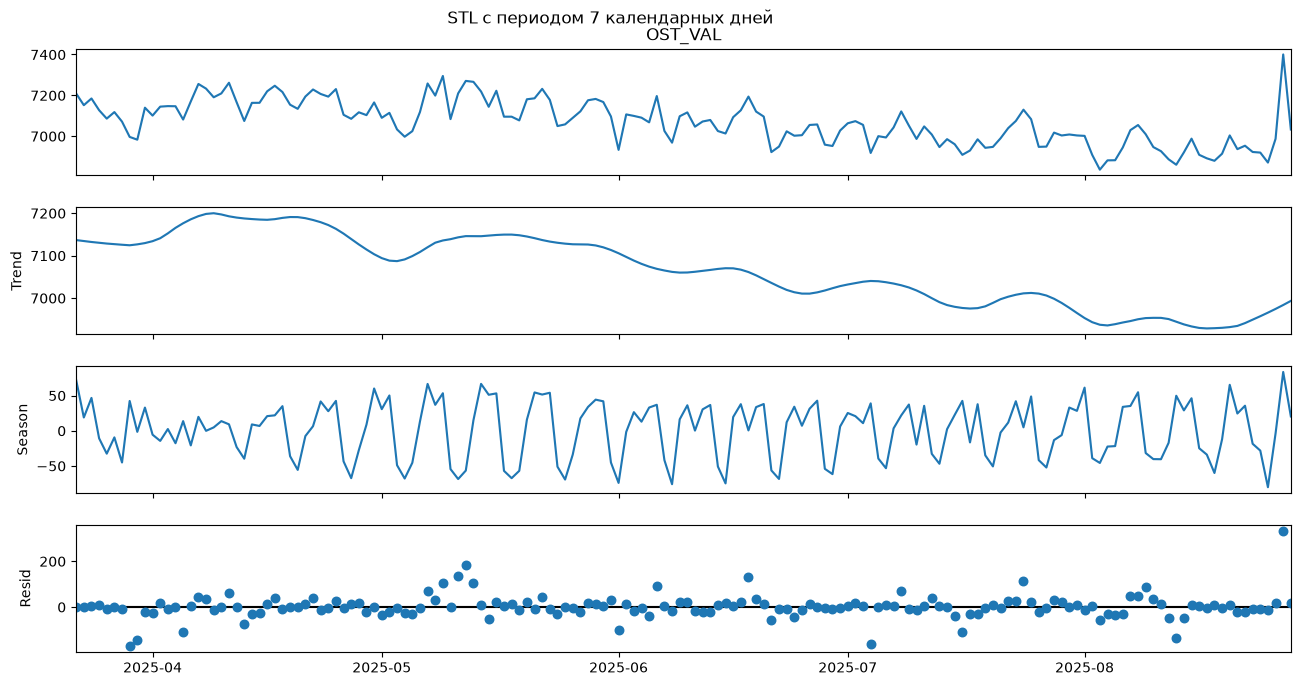

Наблюдений  Статистика  ...  Лагов                  Примечание
Ряд       Тест                          ...                                   
Уровень   ADF          160     -1.6863  ...      7                            
          KPSS         160      1.4743  ...      8  Границы таблицы p-значений
Δ за день ADF          159     -6.1949  ...      6                            
          KPSS         159      0.1701  ...     41  Границы таблицы p-значений

[4 rows x 5 columns]


Валюта USD
Непрерывный отрезок 2025-03-25 — 2025-08-28. Дней в отрезке 157.
Отрезок для расчёта 2025-03-25 — 2025-08-28.


,Тренд,Сезонность,Остаток
std,6.848,1.029,1.411
median,96.236,0.026,-0.064
min,79.536,-2.070,-7.334
max,100.991,3.838,4.417


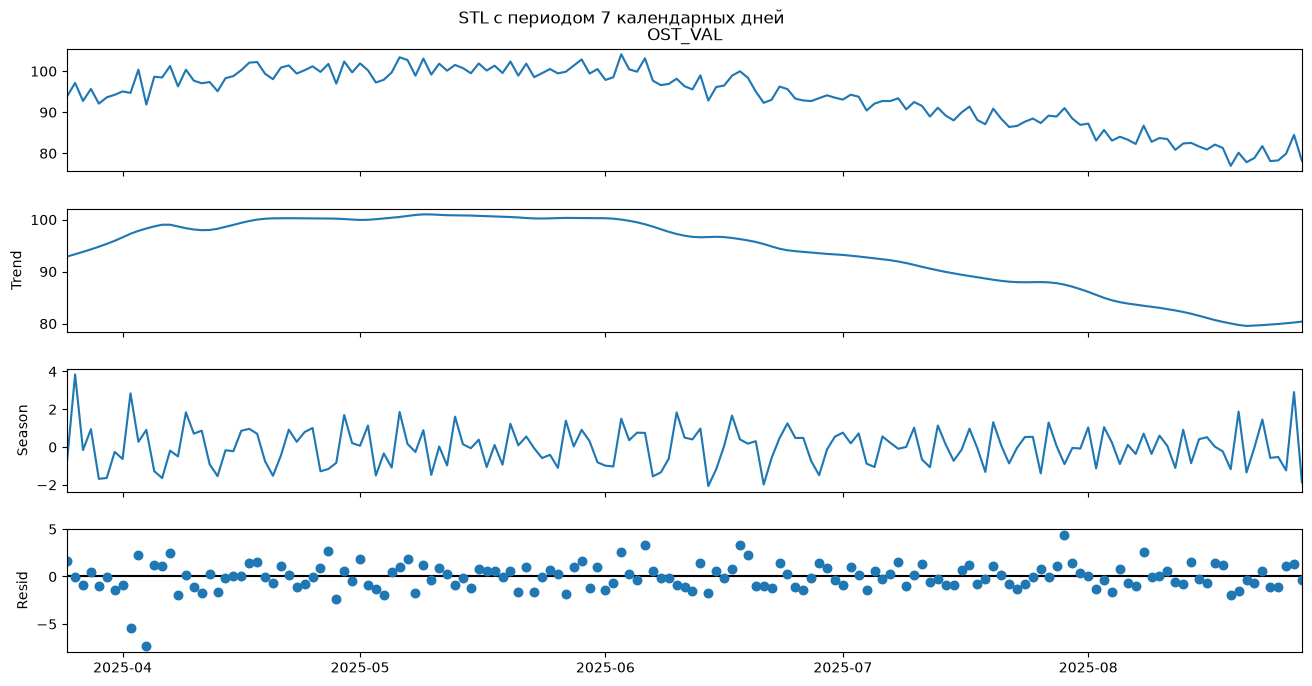

Наблюдений  Статистика  ...  Лагов                  Примечание
Ряд       Тест                          ...                                   
Уровень   ADF          157      1.0728  ...      6                            
          KPSS         157      1.4541  ...      8  Границы таблицы p-значений
Δ за день ADF          156     -3.0839  ...     14                            
          KPSS         156      0.3691  ...     62  Границы таблицы p-значений

[4 rows x 5 columns]

In [9]:
def show_stationarity(eda_target):
    eda_observed = eda_target.dropna()
    import warnings

    eda_run_ids = eda_target.isna().cumsum().loc[eda_target.notna()]
    eda_run_lengths = eda_run_ids.value_counts()
    eda_contiguous = eda_observed.iloc[:0]
    if not eda_run_lengths.empty:
        eda_longest_run = eda_run_lengths.index[eda_run_lengths.eq(eda_run_lengths.max())].max()
        eda_contiguous = eda_observed.loc[eda_run_ids.eq(eda_longest_run)]
        print(f"Непрерывный отрезок {eda_contiguous.index[0]:%Y-%m-%d} — {eda_contiguous.index[-1]:%Y-%m-%d}. Дней в отрезке {len(eda_contiguous)}.")

    if len(eda_contiguous) < 56 or eda_contiguous.nunique() < 2:
        print("Для STL нужен непрерывный отрезок с изменениями длиной от 56 календарных дней.")
    else:
        try:
            from statsmodels.tsa.seasonal import STL
            from statsmodels.tsa.stattools import adfuller, kpss
        except ImportError:
            print("Для STL, ADF и KPSS требуется необязательный пакет statsmodels.")
        else:
            eda_decomposition_sample = eda_contiguous.tail(1461).asfreq("D")
            print(f"Отрезок для расчёта {eda_decomposition_sample.index[0]:%Y-%m-%d} — {eda_decomposition_sample.index[-1]:%Y-%m-%d}.")
            if eda_decomposition_sample.nunique() < 2:
                print("На отрезке для расчёта все остатки совпадают.")
            else:
                eda_stl_result = STL(eda_decomposition_sample, period=7, robust=True).fit()
                eda_stl_summary = pd.DataFrame({
                    "Тренд": eda_stl_result.trend, "Сезонность": eda_stl_result.seasonal, "Остаток": eda_stl_result.resid,
                })
                display(eda_stl_summary.agg(["std", "median", "min", "max"]).round(3))
                fig = eda_stl_result.plot()
                fig.set_size_inches(14, 7)
                fig.suptitle("STL с периодом 7 календарных дней")
                plt.show()

            if len(eda_decomposition_sample) < 100:
                print("Для отчёта ADF и KPSS используется от 100 подряд идущих наблюдений.")
            else:
                eda_stationarity = []
                for eda_test_label, eda_test_values in {
                    "Уровень": eda_decomposition_sample, "Δ за день": eda_decomposition_sample.diff().dropna(),
                }.items():
                    if eda_test_values.nunique() < 2:
                        continue
                    for eda_test_name, eda_test in [
                        ("ADF", lambda values: adfuller(values, regression="c", autolag="AIC")),
                        ("KPSS", lambda values: kpss(values, regression="c", nlags="auto")),
                    ]:
                        try:
                            with warnings.catch_warnings(record=True) as eda_test_warnings:
                                warnings.simplefilter("always")
                                eda_test_stat, eda_p_value, eda_n_lags, *_ = eda_test(eda_test_values)
                            eda_note = "Границы таблицы p-значений" if eda_test_name == "KPSS" and eda_test_warnings else ""
                        except (ValueError, FloatingPointError, np.linalg.LinAlgError, OverflowError, ZeroDivisionError) as eda_error:
                            eda_test_stat, eda_p_value, eda_n_lags, eda_note = np.nan, np.nan, np.nan, str(eda_error)
                        eda_stationarity.append({
                            "Ряд": eda_test_label, "Тест": eda_test_name, "Наблюдений": len(eda_test_values),
                            "Статистика": eda_test_stat, "p-значение": eda_p_value, "Лагов": eda_n_lags, "Примечание": eda_note,
                        })
                if eda_stationarity:
                    display(pd.DataFrame(eda_stationarity).set_index(["Ряд", "Тест"]).round(4))


for currency in iter_eda_currencies():
    show_stationarity(daily_by_currency[currency]["OST_VAL"])

## Резкие движения и сдвиги распределения

Для дневного изменения флаг ставится при отклонении от медианы предыдущих 28 календарных дней более чем на `4 × 1,4826 × MAD`. Нужны хотя бы 12 предыдущих изменений и положительный MAD. Сдвиг уровня сравнивает медианы двух последовательных 30-дневных окон в единицах IQR предыдущего окна. Отметки с модулем выше 1,5 IQR объединяются по соседним дням. Флаги выделяют даты для проверки, включая закономерные календарные движения. Последняя таблица сравнивает последовательные четверти календарного диапазона.


Валюта EUR


,Дней
Дней с известным дневным изменением,1189
"Дней, где вычислима оценка",1165
Дней с изменением и нулевым базовым MAD,0
Дней с флагом движения,4


Крупнейшие по модулю дневные изменения


,OST_VAL,Предыдущий остаток,Изменение,Базовая медиана,Робастная оценка,Флаг
REP_DT,,,,,,
2022-02-16,17.15,67.84,-50.69,-0.150,-7.712,True
2025-03-31,87.59,72.21,15.38,0.465,3.129,False
2023-07-09,55.97,41.30,14.67,0.495,3.608,False
2024-03-01,94.28,82.68,11.60,0.785,5.286,True
2025-01-01,77.02,88.58,-11.56,2.515,-1.884,False
2025-04-01,76.46,87.59,-11.13,0.500,-2.467,False
2022-04-20,74.77,85.58,-10.81,0.215,-1.929,False
2025-10-16,50.31,60.68,-10.37,0.340,-2.706,False
2024-09-13,45.08,34.94,10.14,-0.585,1.952,False


Сдвиг в единицах IQR вычислим для 1356 дней. Число эпизодов с флагом — 37.


,Начало,Конец,Дней,Дата пика,Сдвиг на дату пика в единицах OST_VAL,Сдвиг на дату пика в единицах IQR
22,2024-07-26,2024-07-31,6,2024-07-29,-11.490,-1.652049
23,2024-08-02,2024-08-15,14,2024-08-07,-10.280,-2.646075
24,2024-10-14,2024-12-03,51,2024-11-21,11.675,2.683908
25,2024-12-05,2025-01-18,45,2025-01-08,12.645,3.329822
26,2025-01-27,2025-01-29,3,2025-01-27,9.820,1.775769
27,2025-02-05,2025-02-05,1,2025-02-05,7.870,1.609407
28,2025-04-10,2025-05-09,30,2025-04-29,-10.780,-3.483037
29,2025-05-13,2025-05-13,1,2025-05-13,-12.115,-1.682639
30,2025-05-18,2025-06-25,39,2025-06-01,-14.015,-2.693897
31,2025-06-28,2025-07-13,16,2025-07-08,-10.480,-2.903047


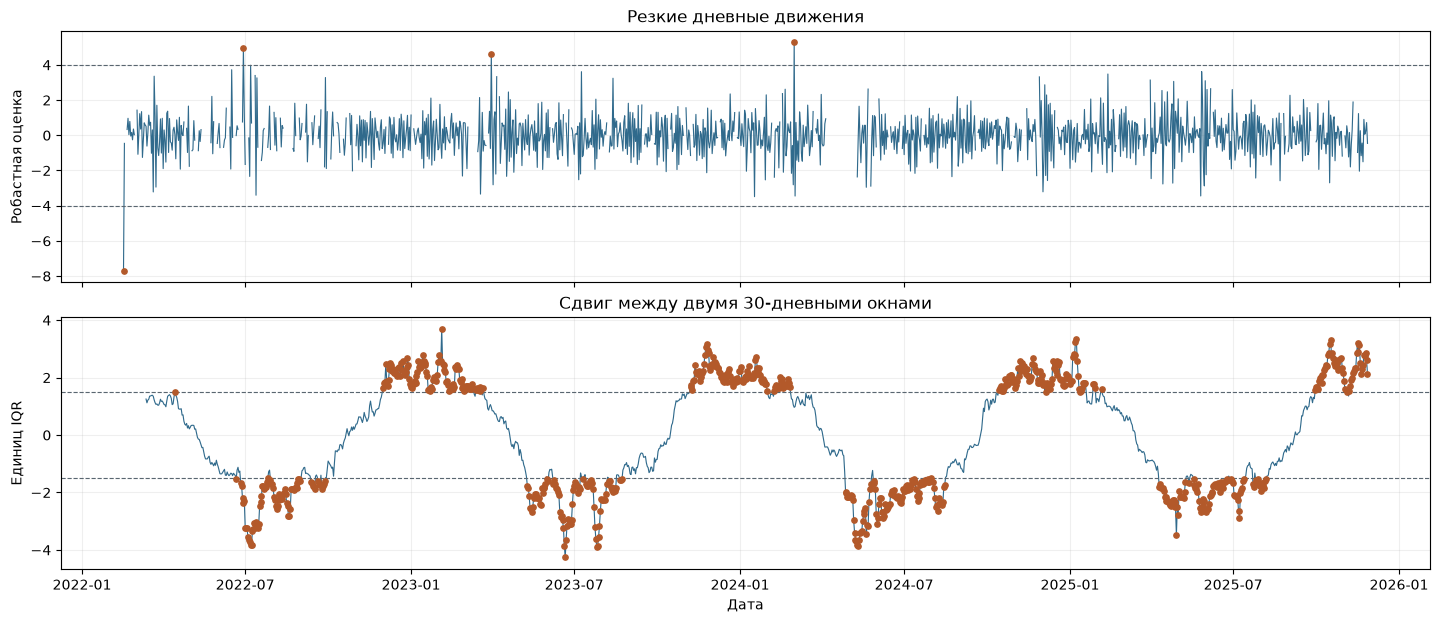

,Начало,Конец,Календарных дней,Известных остатков,"Покрытие остатков, %",p05 уровня,Медиана уровня,p95 уровня,Пар для Δ,Медиана Δ,Стандартное отклонение Δ
Часть диапазона,,,,,,,,,,,
1,2022-02-01,2023-01-15,349,287,82.234957,30.910,56.980,81.9740,251,-0.060,5.111064
2,2023-01-16,2023-12-30,349,327,93.696275,34.421,59.670,82.5970,312,-0.060,3.777261
3,2023-12-31,2024-12-13,349,317,90.830946,37.008,61.390,87.4760,300,0.195,3.732441
4,2024-12-14,2025-11-27,349,336,96.275072,38.430,63.465,88.6975,323,0.060,4.012926



Валюта RUB


,Дней
Дней с известным дневным изменением,1649
"Дней, где вычислима оценка",1637
Дней с изменением и нулевым базовым MAD,0
Дней с флагом движения,22


Крупнейшие по модулю дневные изменения


,OST_VAL,Предыдущий остаток,Изменение,Базовая медиана,Робастная оценка,Флаг
REP_DT,,,,,,
2022-02-16,0.00,6251.61,-6251.61,8.285,-113.242,True
2024-01-18,6922.35,6170.38,751.97,9.770,13.105,True
2024-01-17,6170.38,6914.76,-744.38,9.770,-15.175,True
2021-12-22,6589.36,6036.53,552.83,6.170,7.199,True
2021-12-23,6141.21,6589.36,-448.15,12.225,-5.782,True
2025-08-27,7400.20,6986.75,413.45,-3.860,7.048,True
2025-08-28,7032.45,7400.20,-367.75,-3.860,-5.689,True
2023-08-17,6589.45,6275.40,314.05,-7.650,7.836,True
2025-03-01,7140.99,7418.42,-277.43,-1.845,-4.127,True


Сдвиг в единицах IQR вычислим для 1787 дней. Число эпизодов с флагом — 34.


,Начало,Конец,Дней,Дата пика,Сдвиг на дату пика в единицах OST_VAL,Сдвиг на дату пика в единицах IQR
19,2023-07-27,2023-08-09,14,2023-08-07,-103.720,-2.846323
20,2023-08-31,2023-09-22,23,2023-09-07,214.970,4.839487
21,2023-11-29,2023-12-06,8,2023-12-04,99.385,1.856969
22,2024-01-19,2024-01-20,2,2024-01-20,130.960,1.632918
23,2024-01-22,2024-02-02,12,2024-01-29,170.055,2.747254
24,2024-02-21,2024-02-21,1,2024-02-21,134.280,1.529385
25,2024-03-10,2024-03-12,3,2024-03-10,134.290,1.591491
26,2024-05-07,2024-05-07,1,2024-05-07,72.670,1.849580
27,2024-07-29,2024-08-15,18,2024-08-05,-167.685,-2.241329
28,2025-07-20,2025-07-20,1,2025-07-20,-99.475,-1.525339


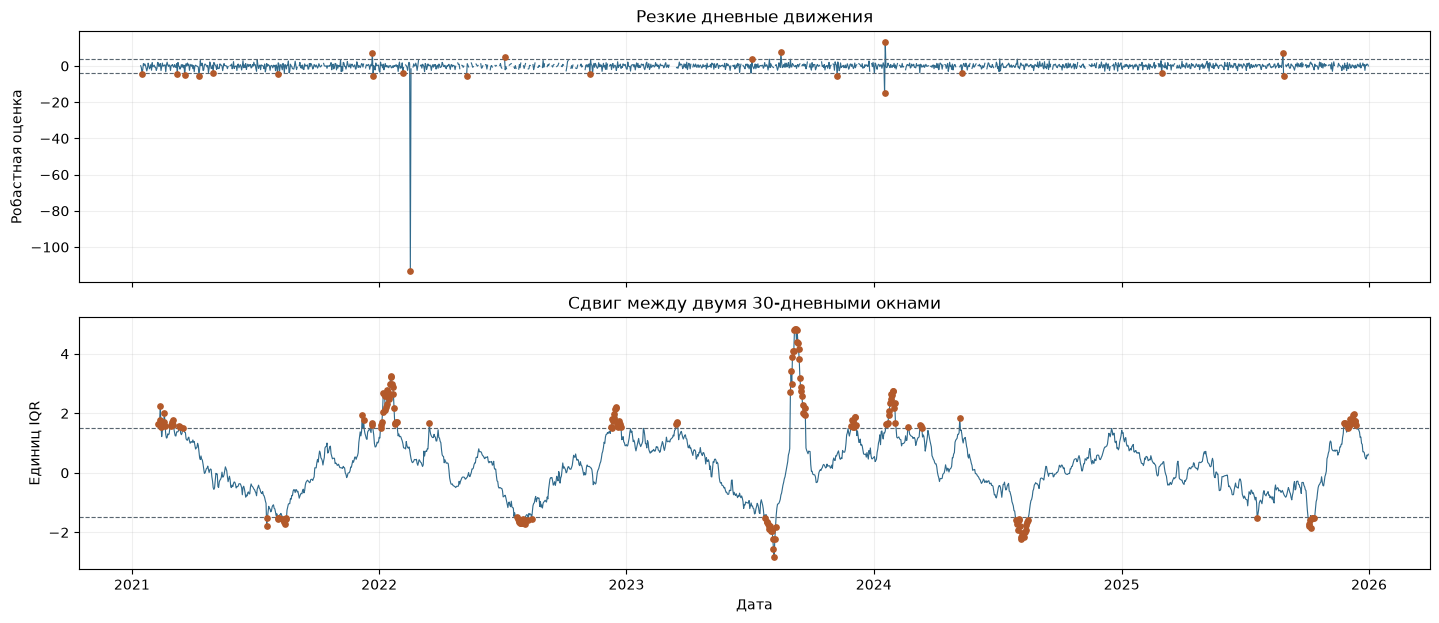

,Начало,Конец,Календарных дней,Известных остатков,"Покрытие остатков, %",p05 уровня,Медиана уровня,p95 уровня,Пар для Δ,Медиана Δ,Стандартное отклонение Δ
Часть диапазона,,,,,,,,,,,
1,2021-01-01,2022-04-02,457,450,98.468271,5773.8105,5971.645,6292.9495,442,10.175,306.252826
2,2022-04-03,2023-07-03,457,389,85.120350,6066.2820,6326.260,6592.0340,355,10.190,54.982598
3,2023-07-04,2024-10-01,456,438,96.052632,6367.7725,6860.785,7125.4465,419,4.100,81.655899
4,2024-10-02,2025-12-31,456,442,96.929825,6819.0695,7048.385,7230.4230,430,2.515,78.763654



Валюта USD


,Дней
Дней с известным дневным изменением,1435
"Дней, где вычислима оценка",1423
Дней с изменением и нулевым базовым MAD,0
Дней с флагом движения,9


Крупнейшие по модулю дневные изменения


,OST_VAL,Предыдущий остаток,Изменение,Базовая медиана,Робастная оценка,Флаг
REP_DT,,,,,,
2022-02-16,-13.24,63.81,-77.05,-0.440,-23.867,True
2025-03-10,92.21,82.19,10.02,0.920,5.456,True
2025-03-09,82.19,91.91,-9.72,0.950,-6.987,True
2021-12-22,67.71,58.53,9.18,-0.575,3.249,False
2022-11-09,69.13,60.61,8.52,-0.830,2.880,False
2025-04-04,91.84,100.34,-8.50,0.720,-3.504,False
2025-03-15,87.68,96.17,-8.49,1.060,-6.346,True
2022-06-09,82.91,91.19,-8.28,0.150,-2.645,False
2022-11-08,60.61,68.50,-7.89,-0.830,-2.174,False


Сдвиг в единицах IQR вычислим для 1610 дней. Число эпизодов с флагом — 54.


,Начало,Конец,Дней,Дата пика,Сдвиг на дату пика в единицах OST_VAL,Сдвиг на дату пика в единицах IQR
39,2024-08-31,2024-10-03,34,2024-09-22,-8.390,-2.540500
40,2024-10-17,2024-11-02,17,2024-10-20,-7.535,-2.954902
41,2024-11-04,2024-11-09,6,2024-11-04,-6.480,-1.862069
42,2025-01-06,2025-01-10,5,2025-01-08,3.835,1.693157
43,2025-01-14,2025-02-08,26,2025-01-27,5.795,2.211832
44,2025-02-11,2025-03-15,33,2025-02-25,7.145,3.140659
45,2025-03-20,2025-04-06,18,2025-03-27,8.080,3.623318
46,2025-04-20,2025-04-21,2,2025-04-21,6.280,1.722908
47,2025-04-27,2025-05-06,10,2025-05-02,6.490,2.305506
48,2025-05-08,2025-05-11,4,2025-05-10,5.170,1.600619


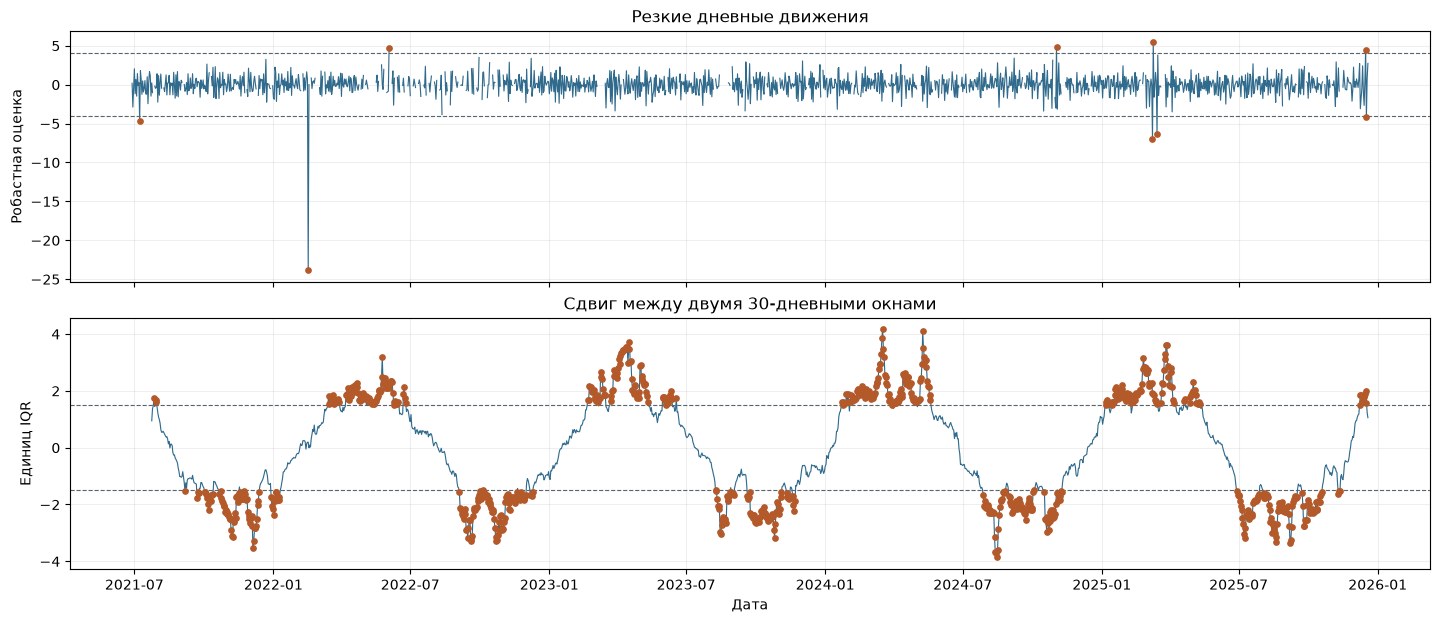

,Начало,Конец,Календарных дней,Известных остатков,"Покрытие остатков, %",p05 уровня,Медиана уровня,p95 уровня,Пар для Δ,Медиана Δ,Стандартное отклонение Δ
Часть диапазона,,,,,,,,,,,
1,2021-06-15,2022-08-01,413,371,89.830508,58.4050,75.950,88.400,342,-0.105,5.044389
2,2022-08-02,2023-09-17,412,359,87.135922,60.8180,80.060,92.757,335,0.100,2.687488
3,2023-09-18,2024-11-02,412,394,95.631068,65.9365,79.445,100.074,375,0.040,2.507983
4,2024-11-03,2025-12-19,412,395,95.873786,67.2700,81.020,101.181,380,0.280,2.675693


In [10]:
def show_shifts(eda_target):
    eda_delta_1d = eda_target.diff().replace([np.inf, -np.inf], np.nan)
    eda_rolling_level, eda_rolling_q25, eda_rolling_q75 = balance_rolling_band(eda_target)
    eda_previous_changes = eda_delta_1d.shift(1).rolling(28, min_periods=12)
    eda_previous_center = eda_previous_changes.median()
    eda_previous_mad = eda_previous_changes.apply(lambda values: np.nanmedian(np.abs(values - np.nanmedian(values))), raw=True)
    eda_robust_scale = 1.4826 * eda_previous_mad.where(eda_previous_mad.gt(0))
    eda_move_score = ((eda_delta_1d - eda_previous_center) / eda_robust_scale).replace([np.inf, -np.inf], np.nan)
    eda_move_flags = eda_move_score.abs().gt(4)
    eda_moves = pd.DataFrame({
        "OST_VAL": eda_target, "Предыдущий остаток": eda_target.shift(), "Изменение": eda_delta_1d,
        "Базовая медиана": eda_previous_center, "Робастная оценка": eda_move_score, "Флаг": eda_move_flags,
    })
    eda_movement_checks = pd.Series({
        "Дней с известным дневным изменением": eda_delta_1d.count(),
        "Дней, где вычислима оценка": eda_move_score.count(),
        "Дней с изменением и нулевым базовым MAD": (eda_delta_1d.notna() & eda_previous_mad.eq(0)).sum(),
        "Дней с флагом движения": eda_move_flags.sum(),
    }, name="Дней")
    display(eda_movement_checks.to_frame())
    if eda_delta_1d.notna().any():
        print("Крупнейшие по модулю дневные изменения")
        display(eda_moves.loc[eda_delta_1d.abs().nlargest(12).index].round(3))

    eda_previous_level = eda_rolling_level.shift(30)
    eda_previous_iqr = (eda_rolling_q75 - eda_rolling_q25).shift(30)
    eda_level_shift = eda_rolling_level - eda_previous_level
    eda_shift_score = eda_level_shift.div(eda_previous_iqr.where(eda_previous_iqr.gt(0))).replace([np.inf, -np.inf], np.nan)
    eda_shift_flags = eda_shift_score.abs().gt(1.5)
    eda_shift_runs = eda_shift_flags.ne(eda_shift_flags.shift(fill_value=False)).cumsum()
    eda_episodes = []
    for _, eda_episode in eda_shift_score.loc[eda_shift_flags].groupby(eda_shift_runs.loc[eda_shift_flags]):
        eda_peak_date = eda_episode.abs().idxmax()
        eda_episodes.append({
            "Начало": eda_episode.index[0], "Конец": eda_episode.index[-1], "Дней": len(eda_episode),
            "Дата пика": eda_peak_date, "Сдвиг на дату пика в единицах OST_VAL": eda_level_shift.loc[eda_peak_date],
            "Сдвиг на дату пика в единицах IQR": eda_episode.loc[eda_peak_date],
        })
    print(f"Сдвиг в единицах IQR вычислим для {eda_shift_score.count()} дней. Число эпизодов с флагом — {len(eda_episodes)}.")
    if eda_episodes:
        display(pd.DataFrame(eda_episodes).tail(15))

    if eda_move_score.notna().any() or eda_shift_score.notna().any():
        fig, axes = plt.subplots(2, 1, figsize=(14, 6.0), sharex=True, constrained_layout=True)
        for axis, eda_score, eda_flags, eda_limit, eda_title, eda_label in [
            (axes[0], eda_move_score, eda_move_flags, 4, "Резкие дневные движения", "Робастная оценка"),
            (axes[1], eda_shift_score, eda_shift_flags, 1.5, "Сдвиг между двумя 30-дневными окнами", "Единиц IQR"),
        ]:
            axis.plot(eda_score, color="#306a8c", linewidth=0.8)
            axis.scatter(eda_score.index[eda_flags], eda_score.loc[eda_flags], color="#b3592a", s=14, zorder=3)
            axis.axhline(eda_limit, color="#596670", linestyle="--", linewidth=0.8)
            axis.axhline(-eda_limit, color="#596670", linestyle="--", linewidth=0.8)
            axis.set(title=eda_title, ylabel=eda_label)
            axis.grid(alpha=0.2)
        axes[1].set_xlabel("Дата")
        plt.show()

    eda_chronological_rows = []
    for eda_chunk, eda_positions in enumerate(np.array_split(np.arange(len(eda_target)), 4), start=1):
        if len(eda_positions) == 0:
            continue
        eda_level_chunk = eda_target.iloc[eda_positions]
        eda_delta_chunk = eda_delta_1d.iloc[eda_positions].iloc[1:]
        eda_chronological_rows.append({
            "Часть диапазона": eda_chunk,
            "Начало": eda_level_chunk.index[0], "Конец": eda_level_chunk.index[-1],
            "Календарных дней": len(eda_level_chunk), "Известных остатков": eda_level_chunk.count(),
            "Покрытие остатков, %": eda_level_chunk.notna().mean() * 100,
            "p05 уровня": eda_level_chunk.quantile(0.05), "Медиана уровня": eda_level_chunk.median(),
            "p95 уровня": eda_level_chunk.quantile(0.95), "Пар для Δ": eda_delta_chunk.count(),
            "Медиана Δ": eda_delta_chunk.median(), "Стандартное отклонение Δ": eda_delta_chunk.std(),
        })
    if eda_chronological_rows:
        display(pd.DataFrame(eda_chronological_rows).set_index("Часть диапазона"))


for currency in iter_eda_currencies():
    show_shifts(daily_by_currency[currency]["OST_VAL"])

## Календарные признаки

Проверяем заполненность, разброс и совпадающие столбцы. Дни недели, недели ISO и границы периодов сверяем с `REP_DT`. По праздникам сверяем связи внутри доступных дат, поскольку официальный календарь и регион на входе не указаны. Для циклических пар проверяем масштаб и соответствие периоду с учётом возможного сдвига фазы.

In [11]:
def audit_calendar(df_work):
    cal_dates = df_work["REP_DT"].reset_index(drop=True)
    cal_target = df_work["OST_VAL"].reset_index(drop=True)
    cal_iso = cal_dates.dt.isocalendar()
    cal_flags_expected = {
        "is_weekend": cal_dates.dt.day_of_week.ge(5),
        "is_month_start": cal_dates.dt.is_month_start,
        "is_month_end": cal_dates.dt.is_month_end,
        "is_quarter_start": cal_dates.dt.is_quarter_start,
        "is_quarter_end": cal_dates.dt.is_quarter_end,
        "is_year_start": cal_dates.dt.is_year_start,
        "is_year_end": cal_dates.dt.is_year_end,
    }
    cal_expected = pd.DataFrame({
        "day_of_week": cal_dates.dt.day_of_week,
        "day_of_month": cal_dates.dt.day,
        "days_to_month_end": cal_dates.dt.days_in_month - cal_dates.dt.day,
        "month": cal_dates.dt.month,
        "quarter": cal_dates.dt.quarter,
        "year": cal_dates.dt.year,
        "day_of_year": cal_dates.dt.day_of_year,
        "iso_year": cal_iso.year,
        "iso_week": cal_iso.week,
        **cal_flags_expected,
    })
    cal_holiday_flags = {"is_holiday", "is_day_before_holiday", "is_day_after_holiday"}
    cal_holiday_distances = {"days_since_holiday", "days_until_holiday"}
    cal_cycles = {
        "weekday": (cal_dates.dt.day_of_week, 7),
        "month": (cal_dates.dt.month - 1, 12),
    }
    cal_cycle_components = {f"{name}_{component}" for name in cal_cycles for component in ("sin", "cos")}
    cal_flag_names = set(cal_flags_expected) | cal_holiday_flags
    cal_known = set(cal_expected) | cal_holiday_flags | cal_holiday_distances | cal_cycle_components | {"holiday_name"}
    cal_source = df_work.drop(columns=["REP_DT", "OST_VAL", CURRENCY_COL]).reset_index(drop=True)
    cal_columns = {}
    for position, label in enumerate(cal_source.columns):
        cal_columns.setdefault(str(label).strip().casefold(), []).append((position, label))

    cal_text, cal_parsed, cal_clean, cal_numeric, cal_labels = {}, {}, {}, {}, {}
    cal_inventory = []
    for name, labels in cal_columns.items():
        for position, label in labels:
            source = cal_source.iloc[:, position]
            as_text = source.astype("string").str.strip()
            nonblank = as_text.notna() & as_text.ne("").fillna(False)
            as_text = as_text.where(nonblank)
            as_numeric = pd.to_numeric(as_text, errors="coerce").astype(float)
            if name in cal_flag_names or pd.api.types.is_bool_dtype(source.dtype):
                flags = as_text.str.casefold().map({"true": 1., "false": 0., "yes": 1., "no": 0., "да": 1., "нет": 0.})
                as_numeric = flags.fillna(as_numeric).where(lambda x: x.isin([0., 1.]))
            nonfinite = as_text.str.casefold().isin(["inf", "+inf", "-inf", "infinity", "+infinity", "-infinity"])
            as_numeric = as_numeric.where(np.isfinite(as_numeric))
            observed_count = int(nonblank.sum())
            known_numeric = name in cal_known and name != "holiday_name"
            inferred_numeric = observed_count > 0 and int(as_numeric.notna().sum() + nonfinite.sum()) == observed_count
            treats_as_numeric = known_numeric or (name != "holiday_name" and inferred_numeric)
            cleaned = as_numeric if treats_as_numeric else as_text.mask(nonfinite)
            distinct = int(cleaned.nunique())
            cal_inventory.append({
                "Признак": str(label),
                "Тип входа": str(source.dtype),
                "Тип анализа": "число" if treats_as_numeric else "категория",
                "Строк с пропуском": int(source.isna().sum()),
                "Пустых строк": int((source.notna() & ~nonblank).sum()),
                "Бесконечностей": int(nonfinite.sum()),
                "Нечисловых значений": int((nonblank & as_numeric.isna() & ~nonfinite).sum()) if treats_as_numeric else np.nan,
                "Доступно, %": 100 * cleaned.notna().mean(),
                "Уникальных": distinct,
                "Самое частое": cleaned.mode().iloc[0] if distinct else pd.NA,
                "Доля частого, %": 100 * cleaned.value_counts(normalize=True).iloc[0] if distinct else np.nan,
                "Пометка": ", ".join(filter(None, [
                    "известный календарный" if name in cal_known else "смысл проверить по источнику",
                    "совпадение имён после нормализации" if len(labels) > 1 else "",
                    "нет разброса" if distinct == 1 else "",
                    "все значения пустые или непригодны" if distinct == 0 else "",
                    "много групп" if distinct > 50 else "",
                ])),
            })
            if len(labels) == 1:
                cal_text[name], cal_parsed[name], cal_clean[name] = as_text, as_numeric, cleaned
                cal_numeric[name], cal_labels[name] = treats_as_numeric, str(label)

    if cal_inventory:
        display(pd.DataFrame(cal_inventory).set_index("Признак").round(2))
        cal_repeated = {}
        for name, cal_series in cal_text.items():
            if cal_series.notna().sum() > 0:
                signature = int(pd.util.hash_pandas_object(cal_series, index=False).sum())
                cal_repeated.setdefault(signature, []).append(name)
        cal_duplicates = [
            (cal_labels[left], cal_labels[right])
            for names in cal_repeated.values()
            for index, left in enumerate(names)
            for right in names[index + 1:]
            if cal_text[left].equals(cal_text[right])
        ]
        if cal_duplicates:
            print("Совпадения значений и пропусков в доступной истории.")
            display(pd.DataFrame(cal_duplicates, columns=["Совпадающий столбец", "Совпадающий столбец (пара)"]))
        else:
            print("Столбцов с одинаковыми значениями и пропусками не найдено.")
    else:
        print("Входных календарных признаков для проверки нет.")

    if cal_inventory and (cal_known - cal_clean.keys()):
        print("Недоступные или неоднозначно названные поля из eda_calendar.ipynb.")
        print(", ".join(sorted(cal_known - cal_clean.keys())))

    cal_rules, cal_examples = [], []


    def add_calendar_check(name, rule, eligible, failure, actual, expected=None):
        eligible = eligible.fillna(False).astype(bool)
        violated = eligible & failure.fillna(False).astype(bool)
        tested, errors = int(eligible.sum()), int(violated.sum())
        cal_rules.append({
            "Признак": name,
            "Проверка": rule,
            "Проверено дат": tested,
            "Расхождений": errors,
            "Расхождений, %": 100 * errors / tested if tested else np.nan,
        })
        for index in violated[violated].index[:3]:
            cal_examples.append({
                "Признак": name,
                "Проверка": rule,
                "Дата": cal_dates.loc[index],
                "Факт": actual.loc[index],
                "Ожидалось": expected.loc[index] if isinstance(expected, pd.Series) else expected,
            })


    for name in cal_expected.columns.intersection(cal_parsed):
        expected = cal_expected[name].astype(float)
        actual = cal_parsed[name]
        add_calendar_check(name, "Значение по REP_DT", cal_text[name].notna(), actual.ne(expected), cal_text[name], expected)

    for name in sorted(cal_holiday_flags.intersection(cal_parsed)):
        add_calendar_check(name, "Логическое значение 0/1", cal_text[name].notna(), cal_parsed[name].isna(), cal_text[name], "0 или 1")

    for name in sorted(cal_holiday_distances.intersection(cal_parsed)):
        distance = cal_parsed[name]
        days_valid = distance.ge(0) & distance.mod(1).eq(0)
        add_calendar_check(name, "Целое расстояние ≥ 0", cal_text[name].notna(), ~days_valid, cal_text[name], "Целое ≥ 0")

    if "is_holiday" in cal_parsed:
        holiday_flag = cal_parsed["is_holiday"]
        holiday_by_date = pd.Series(holiday_flag.to_numpy(), index=pd.DatetimeIndex(cal_dates))
        for name, offset in {"is_day_before_holiday": 1, "is_day_after_holiday": -1}.items():
            if name in cal_parsed:
                flag_at_neighbor = (cal_dates + pd.Timedelta(days=offset)).map(holiday_by_date)
                known = flag_at_neighbor.notna() & cal_parsed[name].notna()
                add_calendar_check(name, "Флаг праздника на соседней дате", known, cal_parsed[name].ne(flag_at_neighbor), cal_parsed[name], flag_at_neighbor)
        for name, direction in {"days_since_holiday": -1, "days_until_holiday": 1}.items():
            if name in cal_parsed and len(cal_dates):
                distance = cal_parsed[name]
                # Порядковые номера дней позволяют сравнивать даты без пересечения границ Timestamp.
                date_day = (cal_dates - cal_dates.min()).dt.days
                in_range = distance.mod(1).eq(0) & distance.between(0, date_day.max())
                flag_on_reference = (date_day + direction * distance.where(in_range)).map(
                    pd.Series(holiday_flag.to_numpy(), index=date_day)
                )
                add_calendar_check(name, "Указанная дата помечена как праздник", flag_on_reference.notna(), flag_on_reference.ne(1), distance, "На указанной дате is_holiday = 1")
        if "holiday_name" in cal_clean:
            name_present = cal_clean["holiday_name"].notna()
            add_calendar_check("holiday_name", "Заполнение названия в дни с is_holiday = 1", holiday_flag.eq(1), ~name_present, cal_text["holiday_name"], "Название заполнено")

    cal_cycle_inspection = []
    for name in sorted(cal_cycle_components.intersection(cal_parsed)):
        component = cal_parsed[name]
        add_calendar_check(name, "Компонента в диапазоне [−1; 1]", cal_text[name].notna(), ~component.between(-1.00001, 1.00001), cal_text[name], "Число от −1 до 1")

    for name, (date_phase, cycle_length) in cal_cycles.items():
        if {f"{name}_sin", f"{name}_cos"} <= cal_parsed.keys():
            sin_component, cos_component = cal_parsed[f"{name}_sin"], cal_parsed[f"{name}_cos"]
            radius = np.hypot(sin_component, cos_component)
            available = radius.notna()
            radius_error = radius.sub(1).abs().gt(1e-4)
            add_calendar_check(f"{name}_sin/cos", "Радиус пары близок к 1", available, radius_error, radius, 1.)
            valid = available & radius.gt(0)
            if valid.any():
                angle = np.arctan2(sin_component, cos_component)
                expected_angle = 2 * np.pi * date_phase / cycle_length
                offset = (angle - expected_angle).loc[valid]
                phase_mean = np.exp(1j * offset).mean()
                residual = np.angle(np.exp(1j * (offset - np.angle(phase_mean))))
                cal_cycle_inspection.append({
                    "Пара": f"{name}_sin/cos",
                    "Дат": int(valid.sum()),
                    "Фаз из REP_DT": int(date_phase.loc[valid].nunique()),
                    "Сдвиг фазы, °": float(np.degrees(np.angle(phase_mean))),
                    "Концентрация фаз (0–1)": float(abs(phase_mean)),
                    "Медианное отклонение от сдвига, °": float(np.median(np.abs(np.degrees(residual)))),
                })

    if cal_rules:
        display(pd.DataFrame(cal_rules).set_index(["Признак", "Проверка"]).round(3))
        if cal_examples:
            print("До трёх примеров на каждую проверку с расхождениями, всего до 36 строк.")
            display(pd.DataFrame(cal_examples).head(36))
    if cal_cycle_inspection:
        display(pd.DataFrame(cal_cycle_inspection).set_index("Пара").round(3))
        print("Концентрация около 1 означает стабильный сдвиг фазы. Проверьте, сколько разных календарных фаз представлено.")

    return cal_clean, cal_parsed, cal_numeric, cal_labels, cal_flag_names, cal_holiday_distances


calendar_audit_by_currency = {
    currency: audit_calendar(rows_by_currency[currency])
    for currency in iter_eda_currencies()
}


Валюта EUR


,Тип входа,Тип анализа,Строк с пропуском,Пустых строк,Бесконечностей,Нечисловых значений,"Доступно, %",Уникальных,Самое частое,"Доля частого, %",Пометка
Признак,,,,,,,,,,,
day_of_week,int64,число,0,0,0,0.0,100.00,7,3.0,15.25,известный календарный
day_of_month,int64,число,0,0,0,0.0,100.00,31,3.0,3.42,известный календарный
day_of_year,float64,число,0,0,0,0.0,100.00,366,32.0,0.31,"известный календарный, много групп"
month,int64,число,0,0,0,0.0,100.00,12,5.0,8.87,известный календарный
quarter,int64,число,0,0,0,0.0,100.00,4,3.0,26.07,известный календарный
year,int64,число,0,0,0,0.0,100.00,4,2023.0,26.93,известный календарный
iso_week,int64,число,0,0,0,0.0,100.00,52,47.0,2.18,"известный календарный, много групп"
iso_year,int64,число,0,0,0,0.0,100.00,4,2023.0,26.85,известный календарный
days_to_month_end,int64,число,0,0,0,0.0,100.00,31,27.0,3.50,известный календарный


Столбцов с одинаковыми значениями и пропусками не найдено.


,,Проверено дат,Расхождений,"Расхождений, %"
Признак,Проверка,,,
day_of_week,Значение по REP_DT,1285,0,0.0
day_of_month,Значение по REP_DT,1285,0,0.0
days_to_month_end,Значение по REP_DT,1285,0,0.0
month,Значение по REP_DT,1285,0,0.0
quarter,Значение по REP_DT,1285,0,0.0
year,Значение по REP_DT,1285,0,0.0
day_of_year,Значение по REP_DT,1285,0,0.0
iso_year,Значение по REP_DT,1285,0,0.0
iso_week,Значение по REP_DT,1285,0,0.0


,Дат,Фаз из REP_DT,"Сдвиг фазы, °",Концентрация фаз (0–1),"Медианное отклонение от сдвига, °"
Пара,,,,,
weekday_sin/cos,1285,7,0.0,1.0,0.0
month_sin/cos,1285,12,0.0,1.0,0.0


Концентрация около 1 означает стабильный сдвиг фазы. Проверьте, сколько разных календарных фаз представлено.

Валюта RUB


... (8 outputs left out)

Столбцов с одинаковыми значениями и пропусками не найдено.


,,Проверено дат,Расхождений,"Расхождений, %"
Признак,Проверка,,,
day_of_week,Значение по REP_DT,1540,0,0.0
day_of_month,Значение по REP_DT,1540,0,0.0
days_to_month_end,Значение по REP_DT,1540,0,0.0
month,Значение по REP_DT,1540,0,0.0
quarter,Значение по REP_DT,1540,0,0.0
year,Значение по REP_DT,1540,0,0.0
day_of_year,Значение по REP_DT,1540,0,0.0
iso_year,Значение по REP_DT,1540,0,0.0
iso_week,Значение по REP_DT,1540,0,0.0


,Дат,Фаз из REP_DT,"Сдвиг фазы, °",Концентрация фаз (0–1),"Медианное отклонение от сдвига, °"
Пара,,,,,
weekday_sin/cos,1540,7,0.0,1.0,0.0
month_sin/cos,1540,12,0.0,1.0,0.0


Концентрация около 1 означает стабильный сдвиг фазы. Проверьте, сколько разных календарных фаз представлено.


### Связь календаря с остатком

Сравниваем связь с уровнем `OST_VAL` и с его изменением за один календарный день. Для изменения берём только пары соседних дат с известными остатками. Корреляции и доля межгрупповой вариации описывают наблюдаемую историю. Сезонный эффект может зависеть от тренда и периода наблюдения, а небольшая группа даёт менее устойчивую оценку.


Валюта EUR
Попарные связи числовых признаков с остатком и его изменением.


,Уровень · пар,Уровень · Пирсон,Уровень · Спирмен,Δ за день · пар,Δ за день · Пирсон,Δ за день · Спирмен
Признак,,,,,,
day_of_week,1267,0.031,0.029,1189,-0.014,-0.018
day_of_month,1267,0.006,0.007,1189,0.025,0.026
day_of_year,1267,-0.628,-0.633,1189,0.050,0.041
month,1267,-0.631,-0.635,1189,0.048,0.039
quarter,1267,-0.643,-0.645,1189,0.042,0.036
year,1267,0.145,0.156,1189,0.020,0.006
iso_week,1267,-0.636,-0.639,1189,0.047,0.037
iso_year,1267,0.147,0.158,1189,0.020,0.007
days_to_month_end,1267,-0.025,-0.026,1189,-0.022,-0.025


η² считается среди групп с минимум 5 датами, если таких групп от 2 до 60.


,Уровень · пар в группах,Уровень · групп ≥ 5,Уровень · η²,Δ за день · пар в группах,Δ за день · групп ≥ 5,Δ за день · η²
Признак,,,,,,
day_of_week,1267,7,0.001,1189,7,0.012
day_of_month,1267,31,0.002,1189,31,0.020
day_of_year,0,0,NaN,0,0,NaN
month,1267,12,0.791,1189,12,0.009
quarter,1267,4,0.673,1189,4,0.005
year,1267,4,0.024,1189,4,0.001
iso_week,1267,52,0.824,1189,52,0.018
iso_year,1267,4,0.024,1189,4,0.001
days_to_month_end,1267,31,0.002,1189,31,0.025


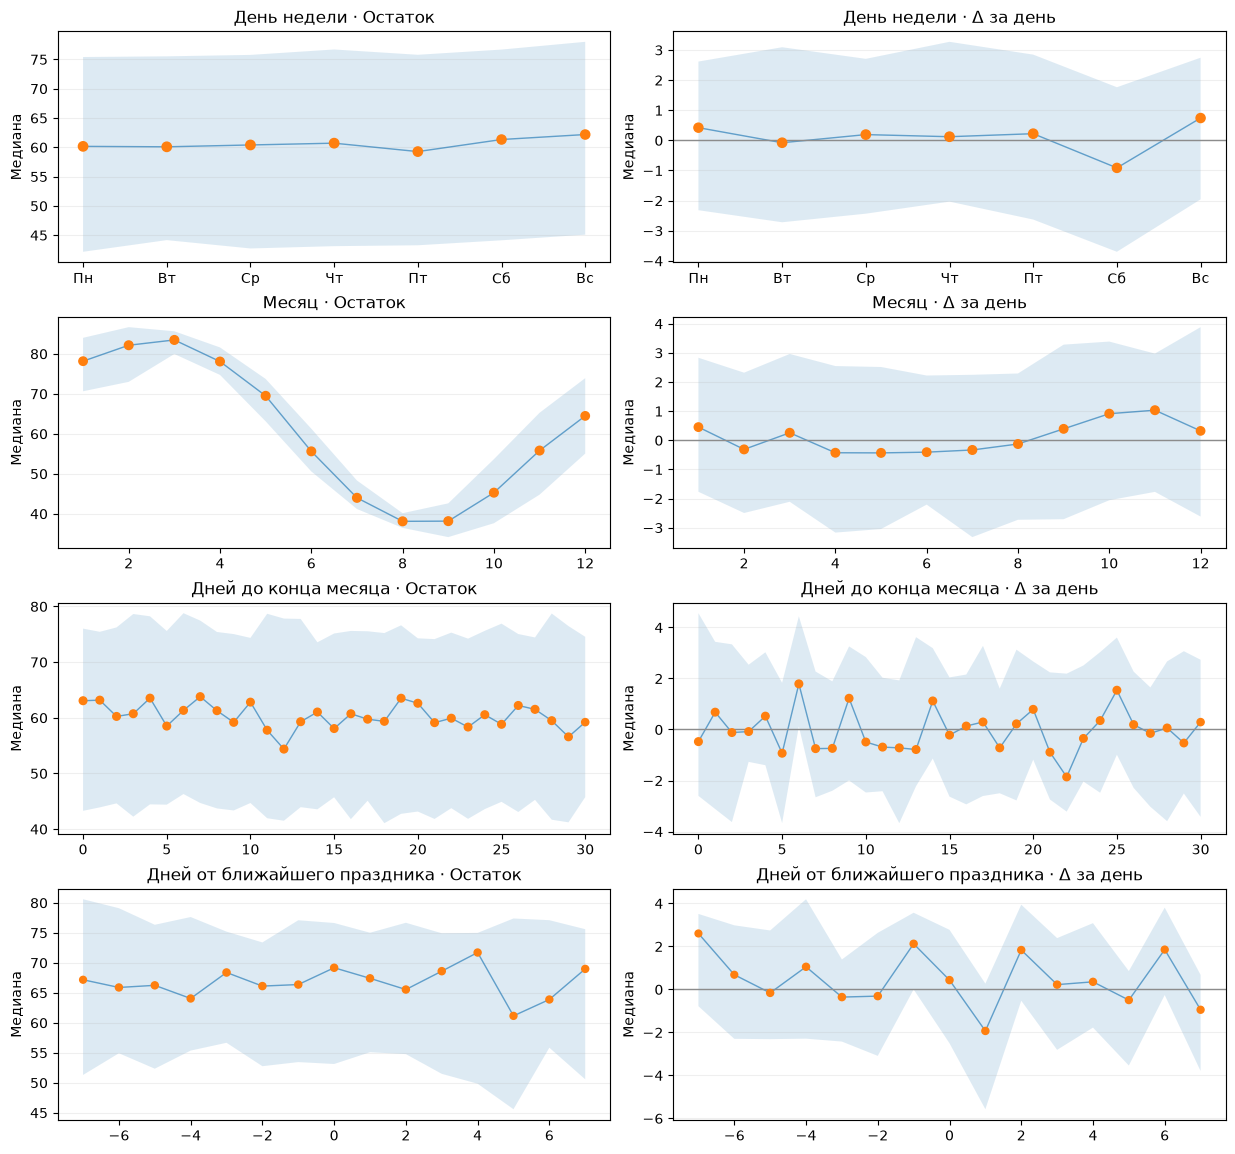

Полоса показывает P25–P75. Размер точки зависит от числа наблюдений. Для праздников минус означает дни до события, плюс — после.


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
День недели,,,,,,,,
0,185,154,60.15,0.42,42.16,-2.32,75.40,2.62
1,188,177,60.08,-0.08,44.15,-2.72,75.52,3.09
2,192,183,60.39,0.19,42.73,-2.44,75.76,2.71
3,192,187,60.70,0.12,43.12,-2.03,76.68,3.27
4,185,180,59.26,0.22,43.27,-2.63,75.78,2.85
5,161,152,61.32,-0.92,44.12,-3.70,76.67,1.76
6,164,156,62.17,0.74,45.08,-1.96,77.99,2.74


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
Дней от ближайшего праздника,,,,,,,,
-7,13,11,67.16,2.60,51.29,-0.79,80.58,3.51
-6,18,12,65.88,0.68,54.91,-2.30,79.08,2.98
-5,19,18,66.23,-0.16,52.34,-2.32,76.32,2.74
-4,18,18,64.04,1.05,55.35,-2.30,77.62,4.19
-3,22,21,68.37,-0.36,56.65,-2.43,75.18,1.39
-2,20,20,66.10,-0.31,52.75,-3.10,73.38,2.63
-1,19,19,66.36,2.12,53.44,-0.00,77.08,3.57
0,20,19,69.16,0.43,53.12,-2.51,76.62,2.77
1,19,18,67.40,-1.94,55.08,-5.58,75.00,0.27


,Остаток · дат 0,Остаток · дат 1,Остаток · медиана 0,Остаток · медиана 1,Остаток · разница 1−0,Δ за день · дат 0,Δ за день · дат 1,Δ за день · медиана 0,Δ за день · медиана 1,Δ за день · разница 1−0
Флаг,,,,,,,,,,
is_day_after_holiday,1248,19,60.315,67.400,7.085,1171,18,0.060,-1.935,-1.995
is_day_before_holiday,1248,19,60.315,66.360,6.045,1170,19,0.010,2.120,2.110
is_holiday,1247,20,60.240,69.160,8.920,1170,19,0.020,0.430,0.410
is_month_end,1225,42,60.240,63.050,2.810,1149,40,0.060,-0.475,-0.535
is_month_start,1225,42,60.540,60.555,0.015,1151,38,0.060,-1.180,-1.240
is_quarter_end,1252,15,60.610,55.230,-5.380,1175,14,0.010,4.460,4.450
is_quarter_start,1253,14,60.540,60.470,-0.070,1175,14,0.060,-2.630,-2.690
is_weekend,942,325,60.035,61.800,1.765,881,308,0.120,-0.260,-0.380
is_year_end,1264,3,60.465,74.680,14.215,1186,3,0.020,4.120,4.100


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
Название праздника,,,,,,,,
Условный праздник В,4,3,74.585,-0.800,70.268,-1.995,75.770,0.890
Условный праздник Д,4,4,51.385,-0.125,44.438,-2.377,59.780,2.282
Условный праздник Б,3,3,90.310,2.960,86.540,2.380,91.185,3.915
Условный праздник Е,3,3,70.380,0.430,62.005,-1.460,76.445,2.555
Условный праздник А,3,3,74.700,0.020,68.220,-5.770,75.860,3.265
Условный праздник Г,3,3,50.190,-1.450,46.720,-2.560,50.885,-0.490



Валюта RUB
Попарные связи числовых признаков с остатком и его изменением.


,Уровень · пар,Уровень · Пирсон,Уровень · Спирмен,Δ за день · пар,Δ за день · Пирсон,Δ за день · Спирмен
Признак,,,,,,
day_of_week,1719,-0.005,-0.015,1649,-0.150,-0.426
day_of_month,1719,0.016,0.019,1649,0.042,0.100
day_of_year,1718,-0.001,-0.046,1648,0.044,0.029
month,1719,-0.003,-0.049,1649,0.041,0.021
quarter,1719,-0.014,-0.062,1649,0.041,0.018
year,1719,0.860,0.936,1649,0.012,-0.015
iso_week,1719,-0.016,-0.063,1649,0.034,0.011
iso_year,1719,0.860,0.938,1649,0.015,-0.011
days_to_month_end,1719,-0.011,-0.019,1649,-0.036,-0.100


η² считается среди групп с минимум 5 датами, если таких групп от 2 до 60.


,Уровень · пар в группах,Уровень · групп ≥ 5,Уровень · η²,Δ за день · пар в группах,Δ за день · групп ≥ 5,Δ за день · η²
Признак,,,,,,
day_of_week,1719,7,0.001,1649,7,0.058
day_of_month,1719,31,0.005,1649,31,0.022
day_of_year,1325,265,NaN,1060,212,NaN
month,1719,12,0.023,1649,12,0.006
quarter,1719,4,0.012,1649,4,0.002
year,1719,5,0.763,1649,5,0.002
iso_week,1716,52,0.034,1647,52,0.030
iso_year,1713,5,0.762,1644,5,0.002
days_to_month_end,1719,31,0.005,1649,31,0.024


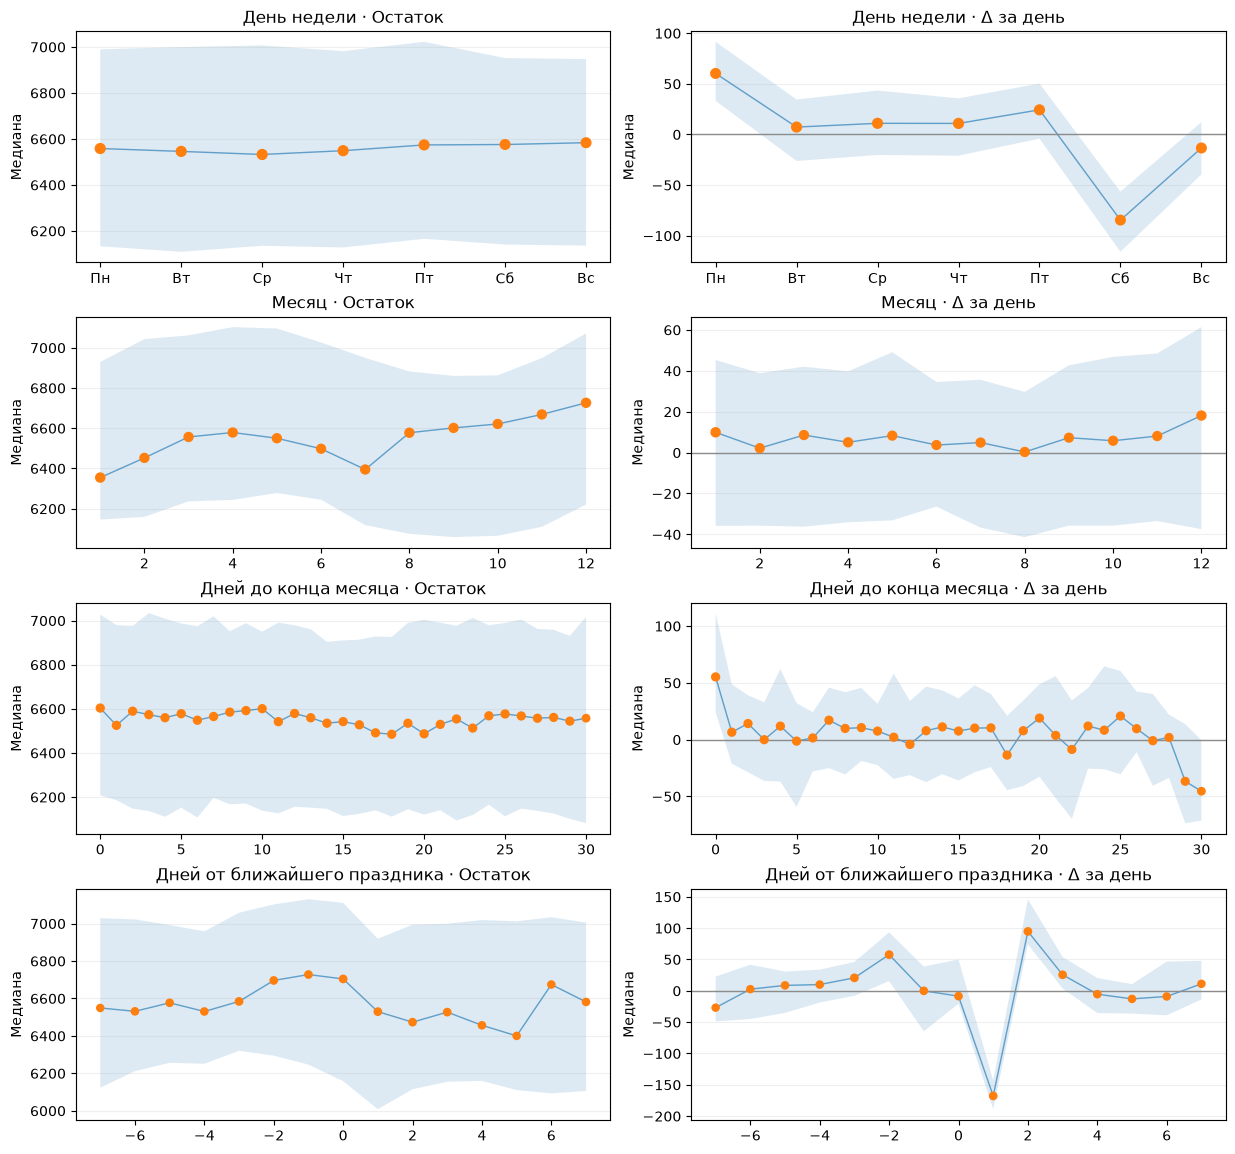

Полоса показывает P25–P75. Размер точки зависит от числа наблюдений. Для праздников минус означает дни до события, плюс — после.


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
День недели,,,,,,,,
0,251,223,6558.07,60.21,6132.83,33.15,6989.40,91.44
1,250,243,6545.56,7.23,6108.98,-26.26,6999.19,34.45
2,258,249,6532.14,10.95,6135.09,-20.37,7006.35,43.33
3,254,252,6548.60,10.84,6127.67,-20.99,6981.43,35.59
4,249,243,6573.65,24.26,6165.48,-4.21,7022.08,50.24
5,226,215,6575.51,-84.63,6140.51,-115.94,6951.42,-56.53
6,231,224,6583.35,-13.41,6135.82,-39.50,6946.80,12.14


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
Дней от ближайшего праздника,,,,,,,,
-7,20,18,6548.89,-27.05,6122.90,-48.88,7028.44,22.51
-6,24,19,6530.90,2.49,6211.35,-45.20,7022.15,41.41
-5,25,24,6576.44,8.49,6256.14,-35.41,6992.15,30.68
-4,24,24,6530.09,9.82,6250.59,-18.87,6958.08,33.61
-3,30,29,6583.88,20.57,6320.28,-8.15,7057.78,45.84
-2,28,28,6695.86,57.60,6294.10,15.41,7101.89,93.13
-1,27,27,6727.45,-0.16,6246.28,-64.72,7129.74,38.52
0,28,26,6703.92,-8.65,6158.01,-20.79,7110.54,49.94
1,29,28,6529.26,-167.86,6007.93,-189.05,6918.75,-142.89


,Остаток · дат 0,Остаток · дат 1,Остаток · медиана 0,Остаток · медиана 1,Остаток · разница 1−0,Δ за день · дат 0,Δ за день · дат 1,Δ за день · медиана 0,Δ за день · медиана 1,Δ за день · разница 1−0
Флаг,,,,,,,,,,
is_day_after_holiday,1690,29,6556.440,6529.260,-27.180,1621,28,8.170,-167.855,-176.025
is_day_before_holiday,1692,27,6552.550,6727.450,174.900,1622,27,7.155,-0.160,-7.315
is_holiday,1691,28,6554.520,6703.925,149.405,1623,26,7.230,-8.650,-15.880
is_month_end,1662,57,6553.650,6603.280,49.630,1593,56,5.410,55.165,49.755
is_month_start,1663,56,6556.320,6556.270,-0.050,1597,52,8.660,-45.080,-53.740
is_quarter_end,1699,20,6554.520,6624.035,69.515,1629,20,6.320,47.205,40.885
is_quarter_start,1700,19,6557.315,6506.650,-50.665,1631,18,7.470,-38.415,-45.885
is_weekend,1262,457,6550.515,6577.340,26.825,1210,439,21.160,-48.400,-69.560
is_year_end,1714,5,6555.420,6972.310,416.890,1644,5,6.915,47.430,40.515


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
Название праздника,,,,,,,,
Условный праздник А,5,4,6368.020,-94.075,6063.650,-116.600,6951.730,-65.685
Условный праздник В,5,4,6646.760,52.150,6432.570,19.020,7170.740,65.478
Условный праздник Д,5,5,6761.090,33.640,6158.560,-5.580,6881.860,35.980
Условный праздник Е,5,5,6864.560,27.500,6263.930,-20.860,7177.450,61.300
Условный праздник Б,4,4,6749.630,16.860,6331.102,-17.295,7127.482,53.632
Условный праздник Г,4,4,6767.545,-19.140,6357.030,-36.052,7069.452,-6.678



Валюта USD
Попарные связи числовых признаков с остатком и его изменением.


,Уровень · пар,Уровень · Пирсон,Уровень · Спирмен,Δ за день · пар,Δ за день · Пирсон,Δ за день · Спирмен
Признак,,,,,,
day_of_week,1519,-0.035,-0.038,1435,-0.089,-0.125
day_of_month,1519,0.008,0.007,1435,0.042,0.053
day_of_year,1519,-0.236,-0.297,1435,0.000,-0.035
month,1519,-0.234,-0.297,1435,-0.003,-0.040
quarter,1519,-0.241,-0.294,1435,-0.005,-0.043
year,1519,0.347,0.348,1435,0.020,0.013
iso_week,1519,-0.242,-0.303,1435,-0.008,-0.046
iso_year,1519,0.349,0.349,1435,0.022,0.016
days_to_month_end,1519,0.000,-0.001,1435,-0.038,-0.054


η² считается среди групп с минимум 5 датами, если таких групп от 2 до 60.


,Уровень · пар в группах,Уровень · групп ≥ 5,Уровень · η²,Δ за день · пар в группах,Δ за день · групп ≥ 5,Δ за день · η²
Признак,,,,,,
day_of_week,1519,7,0.002,1435,7,0.018
day_of_month,1519,31,0.003,1435,31,0.026
day_of_year,570,114,NaN,420,84,NaN
month,1519,12,0.673,1435,12,0.005
quarter,1519,4,0.567,1435,4,0.001
year,1519,5,0.150,1435,5,0.001
iso_week,1519,52,0.703,1435,52,0.021
iso_year,1519,5,0.149,1435,5,0.001
days_to_month_end,1519,31,0.004,1435,31,0.029


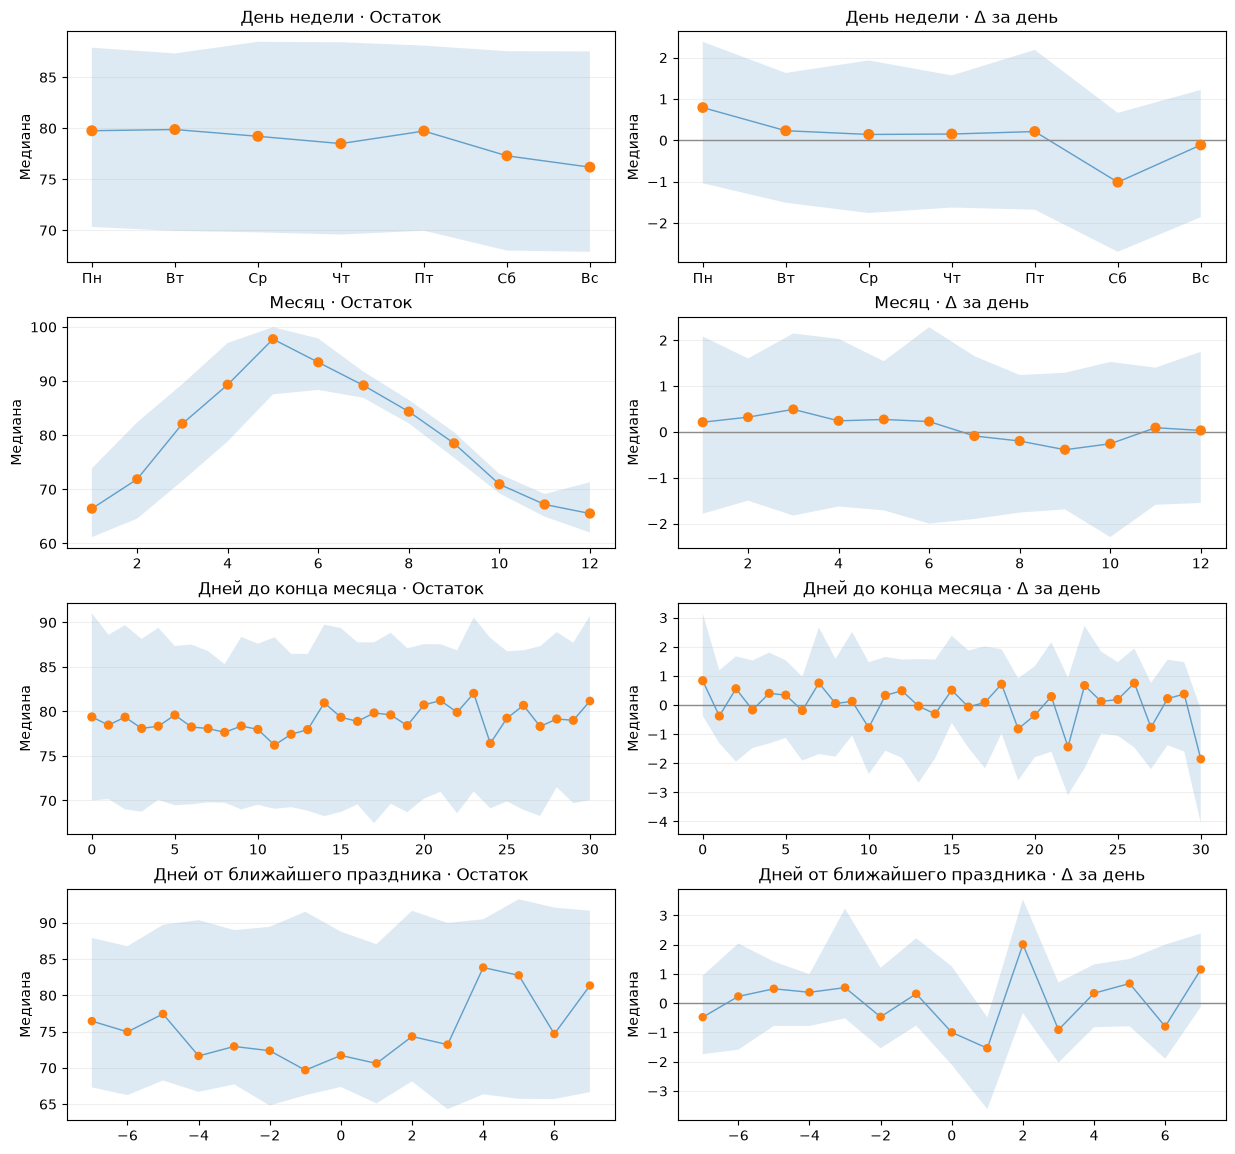

Полоса показывает P25–P75. Размер точки зависит от числа наблюдений. Для праздников минус означает дни до события, плюс — после.


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
День недели,,,,,,,,
0,222,193,79.75,0.79,70.31,-1.04,87.90,2.38
1,220,210,79.87,0.23,69.93,-1.51,87.34,1.63
2,228,215,79.20,0.14,69.78,-1.76,88.47,1.93
3,227,222,78.49,0.15,69.57,-1.63,88.43,1.57
4,222,215,79.72,0.21,69.95,-1.68,88.10,2.19
5,197,186,77.29,-1.01,68.00,-2.70,87.55,0.66
6,203,194,76.18,-0.11,67.88,-1.86,87.52,1.22


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
Дней от ближайшего праздника,,,,,,,,
-7,18,16,76.44,-0.48,67.30,-1.74,87.91,0.94
-6,22,17,74.95,0.23,66.23,-1.59,86.76,2.04
-5,22,21,77.42,0.49,68.25,-0.78,89.71,1.42
-4,21,21,71.63,0.37,66.68,-0.78,90.36,0.99
-3,25,24,72.94,0.53,67.71,-0.52,88.98,3.23
-2,24,23,72.35,-0.47,64.80,-1.54,89.44,1.21
-1,23,23,69.67,0.32,66.22,-0.77,91.51,2.22
0,23,22,71.70,-1.00,67.35,-2.11,88.76,1.26
1,25,23,70.60,-1.54,65.09,-3.62,87.04,-0.48


,Остаток · дат 0,Остаток · дат 1,Остаток · медиана 0,Остаток · медиана 1,Остаток · разница 1−0,Δ за день · дат 0,Δ за день · дат 1,Δ за день · медиана 0,Δ за день · медиана 1,Δ за день · разница 1−0
Флаг,,,,,,,,,,
is_day_after_holiday,1494,25,78.86,70.600,-8.260,1412,23,0.14,-1.540,-1.680
is_day_before_holiday,1496,23,78.87,69.670,-9.200,1412,23,0.09,0.320,0.230
is_holiday,1496,23,78.86,71.700,-7.160,1413,22,0.11,-1.000,-1.110
is_month_end,1468,51,78.81,79.380,0.570,1385,50,0.07,0.835,0.765
is_month_start,1469,50,78.83,79.120,0.290,1388,47,0.16,-1.590,-1.750
is_quarter_end,1501,18,78.85,78.000,-0.850,1417,18,0.08,0.710,0.630
is_quarter_start,1502,17,78.86,77.820,-1.040,1418,17,0.14,-1.780,-1.920
is_weekend,1119,400,79.43,77.045,-2.385,1055,380,0.26,-0.560,-0.820
is_year_end,1515,4,78.87,66.410,-12.460,1431,4,0.10,0.245,0.145


,Остаток · дат,Δ за день · дат,Остаток · медиана,Δ за день · медиана,Остаток · P25,Δ за день · P25,Остаток · P75,Δ за день · P75
Название праздника,,,,,,,,
Условный праздник Д,5,5,68.500,0.360,66.820,-2.150,69.960,0.530
Условный праздник Г,4,4,92.405,-1.000,89.750,-1.770,94.575,-0.028
Условный праздник Е,4,4,65.935,-0.800,60.422,-1.795,71.468,1.695
Условный праздник А,4,4,64.535,-1.875,60.495,-2.598,70.432,-0.985
Условный праздник В,4,3,91.010,-3.240,84.150,-5.405,98.978,0.465
Условный праздник Б,2,2,89.185,1.165,87.822,1.012,90.548,1.317


In [12]:
def show_calendar_relationships(currency_rows, calendar_inputs):
    cal_clean, cal_parsed, cal_numeric, cal_labels, cal_flag_names, cal_holiday_distances = calendar_inputs
    cal_dates = currency_rows["REP_DT"].reset_index(drop=True)
    cal_target = currency_rows["OST_VAL"].reset_index(drop=True)
    cal_daily_change = cal_target.diff().where(cal_dates.diff().eq(pd.Timedelta(days=1)))
    cal_outcomes = {"Уровень": cal_target, "Δ за день": cal_daily_change}
    cal_numeric_links, cal_group_links = [], []
    cal_min_group = 5
    cal_max_groups = 60
    for name, feature in cal_clean.items():
        numeric_row = {"Признак": cal_labels[name]}
        group_row = {"Признак": cal_labels[name]}
        for outcome_name, outcome in cal_outcomes.items():
            pair = pd.DataFrame({"feature": feature, "outcome": outcome}).dropna()
            n_pair = len(pair)
            if cal_numeric[name]:
                numeric_row[f"{outcome_name} · пар"] = n_pair
                enough = n_pair >= 3 and pair["feature"].nunique() > 1 and pair["outcome"].nunique() > 1
                numeric_row[f"{outcome_name} · Пирсон"] = pair["feature"].corr(pair["outcome"]) if enough else np.nan
                numeric_row[f"{outcome_name} · Спирмен"] = pair["feature"].rank().corr(pair["outcome"].rank()) if enough else np.nan

            sizes = pair["feature"].value_counts()
            in_common_groups = pair["feature"].isin(sizes.index[sizes.ge(cal_min_group)])
            selected = pair.loc[in_common_groups]
            groups = selected["feature"].nunique()
            shares_variation = np.nan
            if 2 <= groups <= cal_max_groups and selected["outcome"].nunique() > 1:
                centered = selected["outcome"] - selected["outcome"].mean()
                total = centered.pow(2).sum()
                if total > 0 and np.isfinite(total):
                    summaries = centered.groupby(selected["feature"], observed=True, sort=False).agg(["size", "mean"])
                    between = (summaries["size"] * summaries["mean"].pow(2)).sum()
                    shares_variation = between / total
            group_row[f"{outcome_name} · пар в группах"] = len(selected)
            group_row[f"{outcome_name} · групп ≥ {cal_min_group}"] = groups
            group_row[f"{outcome_name} · η²"] = shares_variation

        if cal_numeric[name]:
            cal_numeric_links.append(numeric_row)
        cal_group_links.append(group_row)

    if cal_numeric_links:
        print("Попарные связи числовых признаков с остатком и его изменением.")
        display(pd.DataFrame(cal_numeric_links).set_index("Признак").round(3))
    if cal_group_links:
        print(f"η² считается среди групп с минимум {cal_min_group} датами, если таких групп от 2 до {cal_max_groups}.")
        display(pd.DataFrame(cal_group_links).set_index("Признак").round(3))

    cal_plot_roles = {
        "day_of_week": ("День недели", range(7)),
        "month": ("Месяц", range(1, 13)),
        "days_to_month_end": ("Дней до конца месяца", range(31)),
    }
    for name in sorted(cal_flag_names):
        cal_plot_roles[name] = (name, range(2))

    if cal_holiday_distances <= cal_parsed.keys():
        cal_since = cal_parsed["days_since_holiday"].where(lambda x: x.ge(0) & x.mod(1).eq(0))
        cal_until = cal_parsed["days_until_holiday"].where(lambda x: x.ge(0) & x.mod(1).eq(0))
        cal_use_previous = cal_until.isna() | (cal_since.notna() & cal_since.le(cal_until))
        cal_holiday_offset = cal_since.where(cal_use_previous, -cal_until)
    else:
        cal_holiday_offset = None


    def calendar_profile(values, levels):
        profile_input = pd.DataFrame({"level": values, "Остаток": cal_target, "Δ за день": cal_daily_change})
        observations = profile_input.groupby("level", observed=True)[["Остаток", "Δ за день"]]
        result = pd.concat([
            observations.count().add_suffix(" · дат"),
            observations.median().add_suffix(" · медиана"),
            observations.quantile(.25).add_suffix(" · P25"),
            observations.quantile(.75).add_suffix(" · P75"),
        ], axis=1).reindex(levels)
        for column in ["Остаток · дат", "Δ за день · дат"]:
            result[column] = result[column].fillna(0).astype(int)
        return result


    cal_profiles = {
        name: (title, calendar_profile(cal_parsed[name], levels))
        for name, (title, levels) in cal_plot_roles.items()
        if name in cal_parsed and cal_parsed[name].notna().any()
    }
    if cal_holiday_offset is not None and cal_holiday_offset.between(-7, 7).any():
        cal_profiles["holiday_offset"] = (
            "Дней от ближайшего праздника",
            calendar_profile(cal_holiday_offset, range(-7, 8)),
        )

    cal_continuous_plots = [name for name in ("day_of_week", "month", "days_to_month_end", "holiday_offset") if name in cal_profiles]
    if cal_continuous_plots:
        fig, cal_axes = plt.subplots(len(cal_continuous_plots), 2, figsize=(12, 2.8 * len(cal_continuous_plots)), squeeze=False, layout="constrained")
        for axes, name in zip(cal_axes, cal_continuous_plots):
            title, profile = cal_profiles[name]
            for axis, field in zip(axes, ["Остаток", "Δ за день"]):
                x = profile.index.to_numpy(dtype=float)
                median = profile[f"{field} · медиана"].to_numpy(dtype=float)
                low = profile[f"{field} · P25"].to_numpy(dtype=float)
                high = profile[f"{field} · P75"].to_numpy(dtype=float)
                counts = profile[f"{field} · дат"].to_numpy(dtype=float)
                axis.fill_between(x, low, high, alpha=.15)
                axis.plot(x, median, lw=1, alpha=.65)
                axis.scatter(x, median, s=np.minimum(16 + 2 * np.sqrt(counts), 52), zorder=3)
                if not np.any(counts):
                    axis.text(.5, .5, "Нет доступных наблюдений", transform=axis.transAxes, ha="center", va="center")
                if name == "day_of_week":
                    axis.set_xticks(range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"])
                if field == "Δ за день":
                    axis.axhline(0, color="0.55", lw=1)
                axis.set(title=f"{title} · {field}", ylabel="Медиана")
                axis.grid(axis="y", alpha=.2)
        plt.show()
        print("Полоса показывает P25–P75. Размер точки зависит от числа наблюдений. Для праздников минус означает дни до события, плюс — после.")
        for name in ("day_of_week", "holiday_offset"):
            if name in cal_profiles:
                title, profile = cal_profiles[name]
                display(profile.rename_axis(title).round(2))

    cal_flags_table = []
    for name in sorted(cal_flag_names.intersection(cal_profiles)):
        _, profile = cal_profiles[name]
        row = {"Флаг": cal_labels[name]}
        for field in ("Остаток", "Δ за день"):
            row[f"{field} · дат 0"] = profile.loc[0, f"{field} · дат"]
            row[f"{field} · дат 1"] = profile.loc[1, f"{field} · дат"]
            row[f"{field} · медиана 0"] = profile.loc[0, f"{field} · медиана"]
            row[f"{field} · медиана 1"] = profile.loc[1, f"{field} · медиана"]
            row[f"{field} · разница 1−0"] = row[f"{field} · медиана 1"] - row[f"{field} · медиана 0"]
        cal_flags_table.append(row)
    if cal_flags_table:
        display(pd.DataFrame(cal_flags_table).set_index("Флаг").round(3))

    if "holiday_name" in cal_clean and cal_clean["holiday_name"].notna().any():
        cal_top_holidays = cal_clean["holiday_name"].value_counts().head(20).index
        display(calendar_profile(cal_clean["holiday_name"], cal_top_holidays).rename_axis("Название праздника").round(3))


for currency in iter_eda_currencies():
    show_calendar_relationships(rows_by_currency[currency], calendar_audit_by_currency[currency])

## Статистические признаки из истории остатков

`make_stat_features()` строит признаки для даты `t` из истории той же валюты до `t − 1` включительно. Лаги измеряются в календарных днях. Для каждой валюты функция строит свою дневную сетку. Если за день нет пригодного остатка, соответствующий лаг остаётся пустым. Скользящим статистикам нужно заданное покрытие окна наблюдениями.

Допустима одна строка на пару «валюта и дата». По умолчанию в результате остаются отчётные даты, а исходные календарные признаки сохраняются. При `include_missing_dates=True` в результат входят все даты между первым и последним отчётом каждой валюты. Для отдельного ряда без валютного столбца передайте `currency_col=None`.

In [13]:
def make_stat_features(
    df,
    *,
    date_col="REP_DT",
    currency_col="CURENCY",
    value_col="OST_VAL",
    lags=(1, 2, 3, 7, 14, 21, 28, 30, 56, 90, 365),
    windows=(7, 14, 28, 56, 90),
    min_coverage=0.5,
    ewm_spans=(7, 28, 90),
    include_missing_dates=False,
):
    """Добавляет признаки из истории каждой валюты до даты строки."""
    if not isinstance(df, pd.DataFrame):
        raise TypeError("Ожидается pandas DataFrame.")
    if not df.columns.is_unique:
        raise ValueError("Имена столбцов должны быть уникальны.")
    if value_col not in df.columns or value_col == date_col:
        raise ValueError(f"Укажите отдельный столбец остатков, например {value_col!r}.")
    def unique_days(values, minimum, name):
        values = tuple(values)
        if any(
            isinstance(x, (bool, np.bool_))
            or not isinstance(x, (int, np.integer))
            or x < minimum
            for x in values
        ):
            raise ValueError(f"{name} должен содержать целые числа от {minimum}.")
        return tuple(dict.fromkeys(int(x) for x in values))

    lags = unique_days(lags, 1, "lags")
    windows = unique_days(windows, 2, "windows")
    ewm_spans = unique_days(ewm_spans, 2, "ewm_spans")
    if not np.isfinite(min_coverage) or not 0 <= min_coverage <= 1:
        raise ValueError("min_coverage должен лежать в диапазоне от 0 до 1.")

    def for_series(frame, currency=None):
        if date_col in frame.columns:
            raw_dates = frame[date_col]
        elif isinstance(frame.index, pd.DatetimeIndex):
            raw_dates = frame.index
        else:
            raise ValueError(f"Нужен столбец {date_col!r} или DatetimeIndex.")

        reported = frame.copy()
        dates = pd.DatetimeIndex(pd.to_datetime(raw_dates, format="mixed", errors="raise"))
        index_name = None if date_col in reported else date_col
        reported.index = dates.tz_localize(None).normalize().rename(index_name)
        if reported.index.hasnans:
            raise ValueError(f"Столбец {date_col!r} содержит пустые даты.")
        if reported.index.has_duplicates:
            raise ValueError(
                f"Нужна одна строка на дату для валюты {currency!r}."
                if currency is not None else "Нужна одна строка на календарную дату."
            )
        reported = reported.sort_index()
        if date_col in reported:
            reported[date_col] = reported.index

        calendar = reported.index
        if len(calendar):
            calendar = pd.date_range(calendar[0], calendar[-1], freq="D", name=index_name)

        raw_balance = reported[value_col]
        if pd.api.types.is_datetime64_any_dtype(raw_balance.dtype) or pd.api.types.is_timedelta64_dtype(raw_balance.dtype):
            observed = pd.Series(np.nan, index=reported.index)
        else:
            numeric = pd.to_numeric(raw_balance, errors="coerce")
            if pd.api.types.is_complex_dtype(numeric.dtype):
                values = numeric.to_numpy()
                numeric = pd.Series(np.where(values.imag == 0, values.real, np.nan), index=numeric.index)
            observed = numeric.astype(float).replace([np.inf, -np.inf], np.nan)
        daily = observed.reindex(calendar)
        past = daily.shift(1)
        past_change = past.diff()
        stat = {}

        def divided_by_abs(numerator, denominator):
            return numerator.div(denominator.abs().where(denominator.ne(0)))

        def slope_per_day(values):
            valid = np.isfinite(values)
            if valid.sum() < 2:
                return np.nan
            x = np.flatnonzero(valid)
            y = values[valid]
            x_centered = x - x.mean()
            return (x_centered @ (y - y.mean())) / (x_centered @ x_centered)

        for lag in lags:
            delayed = daily.shift(lag)
            stat[f"stat_lag_{lag}d"] = delayed
            if lag > 1:
                delta = past - delayed
                stat[f"stat_delta_lag1_vs_lag{lag}d"] = delta
                stat[f"stat_rel_delta_lag1_vs_lag{lag}d"] = divided_by_abs(delta, delayed)

        current_date = pd.Series(calendar, index=calendar)
        last_observed = current_date.where(daily.notna()).shift(1).ffill()
        stat["stat_days_since_observation"] = (current_date - last_observed).dt.days

        for days in windows:
            minimum = max(1, int(np.ceil(days * min_coverage)))
            rolling = past.rolling(days, min_periods=minimum)
            change_window = past_change.rolling(days, min_periods=minimum)
            count = past.rolling(days, min_periods=1).count().fillna(0)
            mean = rolling.mean()
            std = rolling.std()
            low = rolling.min()
            high = rolling.max()
            q25 = rolling.quantile(0.25)
            q75 = rolling.quantile(0.75)
            prefix = f"stat_roll_{days}d"
            stat.update({
                f"{prefix}_count": count,
                f"{prefix}_coverage": count / days,
                f"{prefix}_mean": mean,
                f"{prefix}_median": rolling.median(),
                f"{prefix}_std": std,
                f"{prefix}_min": low,
                f"{prefix}_max": high,
                f"{prefix}_range": high - low,
                f"{prefix}_q10": rolling.quantile(0.10),
                f"{prefix}_q25": q25,
                f"{prefix}_q75": q75,
                f"{prefix}_q90": rolling.quantile(0.90),
                f"{prefix}_iqr": q75 - q25,
                f"{prefix}_skew": rolling.skew(),
                f"{prefix}_slope": rolling.apply(slope_per_day, raw=True),
                f"{prefix}_lag1_minus_mean": past - mean,
                f"{prefix}_lag1_zscore": divided_by_abs(past - mean, std),
                f"{prefix}_change_mean": change_window.mean(),
                f"{prefix}_change_std": change_window.std(),
                f"{prefix}_change_abs_mean": past_change.abs().rolling(
                    days, min_periods=minimum
                ).mean(),
                f"{prefix}_change_up_share": past_change.gt(0).where(
                    past_change.notna()
                ).rolling(days, min_periods=minimum).mean(),
            })

        for span in ewm_spans:
            ew = past.ewm(span=span, adjust=False, min_periods=2, ignore_na=False)
            stat[f"stat_ewm_{span}d_mean"] = ew.mean()
            stat[f"stat_ewm_{span}d_std"] = ew.std()

        for weeks in (4, 8):
            same_weekday = pd.concat(
                [daily.shift(7 * week) for week in range(1, weeks + 1)], axis=1
            )
            count = same_weekday.count(axis=1)
            enough = count.ge(max(1, int(np.ceil(weeks * min_coverage))))
            prefix = f"stat_same_weekday_{weeks}w"
            stat[f"{prefix}_count"] = count
            stat[f"{prefix}_mean"] = same_weekday.mean(axis=1).where(enough)
            stat[f"{prefix}_median"] = same_weekday.median(axis=1).where(enough)
            stat[f"{prefix}_std"] = same_weekday.std(axis=1).where(enough)

        feature_frame = pd.DataFrame(stat, index=calendar).replace([np.inf, -np.inf], np.nan)
        collisions = reported.columns.intersection(feature_frame.columns)
        if len(collisions):
            raise ValueError(f"Переименуйте существующие столбцы: {collisions.tolist()}")
        output_index = calendar if include_missing_dates else reported.index
        output = reported.reindex(output_index)
        if date_col in reported:
            output[date_col] = output.index
        if currency is not None:
            output[currency_col] = currency
        return pd.concat([output, feature_frame.reindex(output_index)], axis=1)


    if currency_col is None:
        return for_series(df)
    if currency_col not in df.columns or currency_col in (date_col, value_col):
        raise ValueError(f"Укажите отдельный столбец валюты, например {currency_col!r}.")
    labels = df[currency_col].astype("string").str.strip().str.upper().replace("", pd.NA)
    if labels.isna().any():
        raise ValueError(f"Столбец {currency_col!r} содержит пустые коды валюты.")

    grouped = df.groupby(labels.to_numpy(), sort=True)
    results = []
    for currency, frame in grouped:
        results.append(for_series(frame, currency))
    if not results:
        results.append(for_series(df))
    return pd.concat(results, axis=0).reset_index(drop=(date_col in df.columns))

`stat_lag_*` содержит прошлые уровни. `stat_delta_*` и `stat_rel_delta_*` сравнивают вчерашний уровень с более ранним. Относительное изменение равно разности, делённой на модуль раннего значения. `stat_roll_*` описывает уровень, разброс, форму распределения, тренд в единицах остатка за день и наблюдавшиеся дневные изменения. Изменение считается при наличии остатков на обе смежные даты и относится к более поздней из них. `stat_ewm_*` даёт экспоненциально взвешенные статистики по доступной истории. `stat_same_weekday_*` использует тот же день недели за предыдущие 4 или 8 недель.

In [14]:
df_stat = make_stat_features(df_work, currency_col=CURRENCY_COL)
stat_columns = df_stat.columns.difference(df_work.columns, sort=False)
df_stat_by_currency = {
    currency: frame.set_index("REP_DT")
    for currency, frame in df_stat.groupby(CURRENCY_COL, sort=True)
}

print(f"Строк: {len(df_stat):,}. Валют: {len(df_stat_by_currency)}. Статистических признаков: {len(stat_columns)}.")
example_columns = [
    CURRENCY_COL, "OST_VAL", "stat_lag_1d", "stat_lag_7d", "stat_delta_lag1_vs_lag7d",
    "stat_roll_7d_mean", "stat_roll_7d_std", "stat_roll_28d_slope",
    "stat_roll_28d_coverage", "stat_ewm_28d_mean", "stat_same_weekday_4w_mean",
]
for currency in iter_eda_currencies():
    display(df_stat_by_currency[currency][example_columns].tail(7))

Строк: 4,565. Валют: 3. Статистических признаков: 151.

Валюта EUR


,CURENCY,OST_VAL,stat_lag_1d,stat_lag_7d,stat_delta_lag1_vs_lag7d,stat_roll_7d_mean,stat_roll_7d_std,stat_roll_28d_slope,stat_roll_28d_coverage,stat_ewm_28d_mean,stat_same_weekday_4w_mean
REP_DT,,,,,,,,,,,
2025-11-21,EUR,72.29,72.07,NaN,NaN,71.908333,1.724197,0.406515,0.892857,66.331243,63.445000
2025-11-22,EUR,69.76,72.29,70.95,1.34,71.962857,1.580567,0.377093,0.892857,66.742192,65.322500
2025-11-23,EUR,72.68,69.76,69.92,-0.16,71.792857,1.761323,0.343884,0.892857,66.950316,65.780000
2025-11-24,EUR,73.53,72.68,74.72,-2.04,72.187143,1.570814,0.348219,0.892857,67.345467,66.937500
2025-11-25,EUR,75.20,73.53,70.88,2.65,72.017143,1.290371,0.344423,0.892857,67.771987,68.955000
2025-11-26,EUR,78.22,75.20,72.91,2.29,72.634286,1.641228,0.361158,0.892857,68.284263,69.506667
2025-11-27,EUR,77.94,78.22,72.07,6.15,73.392857,2.685080,0.411436,0.892857,68.969487,68.405000



Валюта RUB


,CURENCY,OST_VAL,stat_lag_1d,stat_lag_7d,stat_delta_lag1_vs_lag7d,stat_roll_7d_mean,stat_roll_7d_std,stat_roll_28d_slope,stat_roll_28d_coverage,stat_ewm_28d_mean,stat_same_weekday_4w_mean
REP_DT,,,,,,,,,,,
2025-12-25,RUB,7263.65,7202.35,7059.80,142.55,7121.945714,72.666926,1.020460,1.0,7091.256718,7101.2700
2025-12-26,RUB,7040.98,7263.65,7189.00,74.65,7151.067143,83.630640,2.253771,1.0,7103.145910,7131.0250
2025-12-27,RUB,7087.11,7040.98,7071.51,-30.53,7129.921429,90.843082,2.019294,1.0,7098.858605,7033.5650
2025-12-28,RUB,7113.15,7087.11,7056.65,30.46,7132.150000,89.350388,1.255591,1.0,7098.048357,7064.7125
2025-12-29,RUB,7204.59,7113.15,7067.91,45.24,7140.221429,83.771181,1.599100,1.0,7099.089849,7091.7900
2025-12-30,RUB,7296.49,7204.59,7206.40,-1.81,7159.747143,79.949214,2.183481,1.0,7106.365722,7117.1850
2025-12-31,RUB,7317.26,7296.49,7202.35,94.14,7172.617143,94.616702,2.848374,1.0,7119.477741,7142.5325



Валюта USD


,CURENCY,OST_VAL,stat_lag_1d,stat_lag_7d,stat_delta_lag1_vs_lag7d,stat_roll_7d_mean,stat_roll_7d_std,stat_roll_28d_slope,stat_roll_28d_coverage,stat_ewm_28d_mean,stat_same_weekday_4w_mean
REP_DT,,,,,,,,,,,
2025-12-13,USD,74.03,75.27,72.57,2.70,73.824286,2.226259,0.178585,1.0,71.875472,69.4500
2025-12-14,USD,69.89,74.03,73.76,0.27,74.032857,2.156461,0.164387,1.0,72.024060,70.9900
2025-12-15,USD,70.73,69.89,77.90,-8.01,73.480000,2.672427,0.112923,1.0,71.876884,73.1725
2025-12-16,USD,78.00,70.73,73.94,-3.21,72.455714,1.980453,0.103202,1.0,71.797788,72.7275
2025-12-17,USD,70.99,78.00,71.91,6.09,73.035714,2.878494,0.157293,1.0,72.225527,71.8700
2025-12-18,USD,72.43,70.99,71.42,-0.43,72.904286,2.958355,0.147151,1.0,72.140318,71.5975
2025-12-19,USD,77.35,72.43,75.27,-2.84,73.048571,2.897910,0.133621,1.0,72.160296,71.1800


### Проверки расчёта признаков

На коротком примере вручную сверяем лаги, окно с пропущенной датой, наклон, деление при нулевом остатке и сохранение календарного столбца. Заменяем значения начиная с контрольной даты и сравниваем весь набор признаков вплоть до этой даты. Отдельно проверяем, что обрезка конца истории оставляет признаки в её начале прежними.

На трёх рядах с пересечением дат сверяем расчёт с отдельными вызовами по каждой валюте. Изменение истории одной валюты должно сохранять все признаки двух остальных.

In [15]:
test_days = pd.to_datetime([
    "2024-01-01", "2024-01-03", "2024-01-04",
    "2024-01-05", "2024-01-06", "2024-01-07",
])
test_fl = pd.DataFrame({
    "REP_DT": test_days,
    "OST_VAL": [10.0, -2.0, 0.0, 4.0, np.nan, 8.0],
    "weekday_demo": test_days.day_of_week,
})
test_snapshot = test_fl.copy()
test_opts = {"currency_col": None, "lags": (1, 2, 7), "windows": (3,), "min_coverage": 1 / 3}
tested = make_stat_features(test_fl.iloc[::-1], **test_opts)
test_generated = tested.columns.difference(test_fl.columns, sort=False)
pd.testing.assert_frame_equal(test_fl, test_snapshot)
pd.testing.assert_index_equal(tested.index, test_days)
np.testing.assert_array_equal(tested["weekday_demo"], test_fl["weekday_demo"])
assert pd.isna(tested.loc["2024-01-03", "stat_lag_1d"])
assert tested.loc["2024-01-03", "stat_lag_2d"] == 10.0
assert tested.loc["2024-01-03", "stat_roll_3d_count"] == 1
assert tested.loc["2024-01-03", "stat_roll_3d_mean"] == 10.0
assert tested.loc["2024-01-04", "stat_roll_3d_mean"] == 4.0
assert tested.loc["2024-01-04", "stat_roll_3d_slope"] == -6.0
assert pd.isna(tested.loc["2024-01-06", "stat_rel_delta_lag1_vs_lag2d"])
assert tested.loc["2024-01-07", "stat_days_since_observation"] == 2

full_calendar = make_stat_features(test_fl, include_missing_dates=True, **test_opts)
assert full_calendar.loc["2024-01-02", "REP_DT"] == pd.Timestamp("2024-01-02")
assert pd.isna(full_calendar.loc["2024-01-02", "OST_VAL"])
assert full_calendar.loc["2024-01-02", "stat_lag_1d"] == 10.0
strict_coverage = make_stat_features(test_fl, currency_col=None, windows=(3,), min_coverage=1)
assert pd.isna(strict_coverage.loc["2024-01-04", "stat_roll_3d_mean"])

cutoff = pd.Timestamp("2024-01-05")
changed = test_fl.copy()
changed.loc[changed["REP_DT"].ge(cutoff), "OST_VAL"] = 10_000.0
changed_features = make_stat_features(changed, **test_opts)
prefix_features = make_stat_features(test_fl.loc[test_fl["REP_DT"].le(cutoff)], **test_opts)
for candidate in (changed_features, prefix_features):
    pd.testing.assert_frame_equal(
        tested.loc[:cutoff, test_generated], candidate.loc[:cutoff, test_generated]
    )

bad_cases = [
    (pd.concat([test_fl, test_fl.iloc[[0]]]), {"currency_col": None, "windows": (3,)}, "повтор даты"),
    (test_fl, {"currency_col": None, "lags": (0,)}, "нулевой лаг"),
]
for bad_input, bad_kwargs, label in bad_cases:
    try:
        make_stat_features(bad_input, **bad_kwargs)
    except ValueError:
        pass
    else:
        raise AssertionError(f"Нет ошибки для случая «{label}».")

multi = pd.concat([
    test_fl.assign(CURENCY=" rub "),
    test_fl.iloc[1:].assign(CURENCY="USD", OST_VAL=lambda x: 100 * x["OST_VAL"]),
    test_fl.iloc[2:5].assign(CURENCY="EUR", OST_VAL=lambda x: x["OST_VAL"] + 500),
], ignore_index=True).sample(frac=1, random_state=5)
multi_snapshot = multi.copy(deep=True)
multi_stat = make_stat_features(multi, lags=(1, 2, 7), windows=(3,), min_coverage=1 / 3)
pd.testing.assert_frame_equal(multi, multi_snapshot)
for code, source in multi.groupby(multi["CURENCY"].str.strip().str.upper()):
    actual = multi_stat.loc[multi_stat["CURENCY"].eq(code), test_generated].reset_index(drop=True)
    expected = make_stat_features(source, **test_opts)[test_generated].reset_index(drop=True)
    pd.testing.assert_frame_equal(actual, expected)

perturbed = multi.assign(OST_VAL=multi["OST_VAL"].where(multi["CURENCY"].ne("USD"), -100_000))
perturbed_stat = make_stat_features(perturbed, lags=(1, 2, 7), windows=(3,), min_coverage=1 / 3)
pd.testing.assert_frame_equal(
    multi_stat.loc[multi_stat["CURENCY"].ne("USD")],
    perturbed_stat.loc[perturbed_stat["CURENCY"].ne("USD")],
)

multi_daily = make_stat_features(multi, include_missing_dates=True)
rub_gap = multi_daily.loc[multi_daily["CURENCY"].eq("RUB") & multi_daily["REP_DT"].eq("2024-01-02")]
assert len(rub_gap) == 1 and rub_gap["OST_VAL"].isna().all() and rub_gap["stat_lag_1d"].iat[0] == 10
assert multi_daily.loc[multi_daily["CURENCY"].eq("USD"), "REP_DT"].min() == pd.Timestamp("2024-01-03")

assert len(df_stat) == len(df_work)
assert not df_stat.duplicated([CURRENCY_COL, "REP_DT"]).any()
assert all(frame.index.is_unique and frame.index.is_monotonic_increasing for frame in df_stat_by_currency.values())
assert not np.isinf(df_stat[stat_columns].to_numpy(dtype=float)).any()
print("Проверки лагов, полноты окон, дат и независимости рядов по валютам прошли.")

Проверки лагов, полноты окон, дат и независимости рядов по валютам прошли.


### Покрытие, распределения и связь с целевой переменной

В каждой валюте первые 80% её отчётных дат образуют ранний отрезок, последние 20% — поздний. Статистика по каждому признаку включает доступность, квантили, стандартное отклонение и число разных значений. Сдвиг медианы нормирован на межквартильный размах раннего отрезка. При нулевом размахе метрика остаётся пустой.

На экране показаны признаки с наибольшей долей пропусков и сдвигами медианы. Полная сводка по проверенным валютам доступна в `stat_audit`.

Пирсон измеряет линейную связь, Спирмен — связь рангов. Считаем их отдельно для уровня остатка и дневного изменения на целевой дате. Для каждого коэффициента нужно минимум 15 пар и разброс обеих величин. В таблице верхние позиции определяет модуль корреляции Спирмена на раннем отрезке. Общий тренд может усиливать корреляцию уровней. Корреляция с дневным изменением также может зависеть от того, что вчерашний остаток входит в расчёт изменения. Эти таблицы диагностируют признаки, прогнозная точность здесь не измеряется.

In [16]:
def audit_stat_distribution(stat_features):
    n_stat_rows = len(stat_features)
    n_early = min(n_stat_rows, max(1, int(n_stat_rows * 0.80)))
    early_stat = stat_features.iloc[:n_early]
    late_stat = stat_features.iloc[n_early:]
    early_iqr = early_stat.quantile(0.75) - early_stat.quantile(0.25)
    groups = stat_features.columns.to_series().str.extract(r"^stat_([a-z]+)", expand=False)

    stat_audit = pd.DataFrame({
        "Группа": groups,
        "Наблюдений": stat_features.count(),
        "Пропусков, %": stat_features.isna().mean() * 100,
        "Бесконечностей": np.isinf(stat_features).sum(),
        "Уникальных": stat_features.nunique(),
        "Среднее": stat_features.mean(),
        "Ст. отклонение": stat_features.std(),
        "Мин": stat_features.min(),
        "P01": stat_features.quantile(0.01),
        "P25": stat_features.quantile(0.25),
        "Медиана": stat_features.median(),
        "P75": stat_features.quantile(0.75),
        "P99": stat_features.quantile(0.99),
        "Макс": stat_features.max(),
        "Покрытие раннего, %": early_stat.notna().mean() * 100,
        "Покрытие позднего, %": late_stat.notna().mean() * 100,
        "Сдвиг медианы / IQR": (
            (late_stat.median() - early_stat.median()).div(early_iqr.where(early_iqr.gt(0)))
        ),
    })
    stat_audit["Постоянный"] = stat_audit["Уникальных"].eq(1)
    stat_audit["Пустой"] = stat_audit["Наблюдений"].eq(0)
    group_stat_audit = stat_audit.groupby("Группа").agg(
        **{
            "Признаков": ("Наблюдений", "size"),
            "Пустых": ("Пустой", "sum"),
            "Постоянных": ("Постоянный", "sum"),
            "Медиана покрытия раннего, %": ("Покрытие раннего, %", "median"),
            "Медиана покрытия позднего, %": ("Покрытие позднего, %", "median"),
        }
    )
    print(f"Ранний отрезок: {len(early_stat):,} дат. Поздний отрезок: {len(late_stat):,} дат.")
    if len(late_stat):
        print(f"Первая дата позднего отрезка — {late_stat.index[0]:%Y-%m-%d}.")
    display(group_stat_audit.round(2))
    display(stat_audit.sort_values("Пропусков, %", ascending=False).head(18).round(3))

    changes = stat_audit.loc[
        stat_audit["Сдвиг медианы / IQR"].abs().nlargest(12).dropna().index,
        ["Сдвиг медианы / IQR", "Покрытие раннего, %", "Покрытие позднего, %"],
    ]
    if len(changes):
        print("Наибольшие сдвиги медианы по модулю")
        display(changes.round(3))
    return stat_audit, group_stat_audit, early_stat, late_stat


stat_audit_by_currency, stat_distribution_inputs = {}, {}
for currency in iter_eda_currencies():
    audit, group_stat_audit, early_stat, late_stat = audit_stat_distribution(
        df_stat_by_currency[currency][stat_columns]
    )
    stat_audit_by_currency[currency] = audit
    stat_distribution_inputs[currency] = group_stat_audit, early_stat, late_stat

stat_audit = (
    pd.concat(stat_audit_by_currency, names=[CURRENCY_COL, "Признак"])
    if stat_audit_by_currency else pd.DataFrame()
)


Валюта EUR
Ранний отрезок: 1,028 дат. Поздний отрезок: 257 дат.
Первая дата позднего отрезка — 2025-03-06.


,Признаков,Пустых,Постоянных,"Медиана покрытия раннего, %","Медиана покрытия позднего, %"
Группа,,,,,
days,1,0,0,99.90,100.00
delta,10,0,0,84.24,92.41
ewm,6,0,0,99.81,100.00
lag,11,0,0,90.37,96.11
rel,10,0,0,84.24,92.41
roll,105,0,0,97.08,100.00
same,8,0,0,97.86,100.00


,Группа,Наблюдений,"Пропусков, %",Бесконечностей,Уникальных,Среднее,Ст. отклонение,Мин,P01,P25,Медиана,P75,P99,Макс,"Покрытие раннего, %","Покрытие позднего, %",Сдвиг медианы / IQR,Постоянный,Пустой
stat_delta_lag1_vs_lag365d,delta,825,35.798,0,758,3.039,7.573,-16.010,-12.528,-2.330,3.040,8.030,17.351,67.440,59.144,84.436,-0.536,False,False
stat_rel_delta_lag1_vs_lag365d,rel,825,35.798,0,825,0.073,0.264,-0.246,-0.190,-0.037,0.048,0.152,0.419,5.478,59.144,84.436,-0.502,False,False
stat_lag_365d,lag,869,32.374,0,807,58.294,17.616,12.310,29.566,41.560,58.170,74.510,88.910,94.280,62.354,88.716,-0.260,False,False
stat_delta_lag1_vs_lag90d,delta,1023,20.389,0,992,-0.169,25.605,-44.220,-39.469,-25.360,-1.220,24.545,41.740,57.420,76.265,92.996,-0.384,False,False
stat_rel_delta_lag1_vs_lag90d,rel,1023,20.389,0,1023,0.108,0.502,-0.593,-0.507,-0.345,-0.027,0.530,1.175,3.348,76.265,92.996,-0.316,False,False
stat_delta_lag1_vs_lag56d,delta,1072,16.576,0,1032,0.391,17.432,-35.130,-28.908,-15.673,0.885,16.713,29.030,69.990,81.226,92.218,-0.450,False,False
stat_rel_delta_lag1_vs_lag56d,rel,1072,16.576,0,1072,0.062,0.382,-0.491,-0.414,-0.248,0.015,0.332,0.741,5.686,81.226,92.218,-0.403,False,False
stat_rel_delta_lag1_vs_lag30d,rel,1085,15.564,0,1085,0.035,0.272,-0.375,-0.286,-0.125,0.015,0.174,0.457,5.583,82.393,92.607,-0.442,False,False
stat_delta_lag1_vs_lag30d,delta,1085,15.564,0,999,0.735,10.280,-24.640,-19.478,-7.660,0.890,9.200,19.329,68.730,82.393,92.607,-0.458,False,False
stat_lag_90d,lag,1096,14.708,0,1000,60.126,18.172,17.150,30.778,42.378,60.150,76.562,90.196,94.280,82.296,97.276,0.414,False,False


Наибольшие сдвиги медианы по модулю


,Сдвиг медианы / IQR,"Покрытие раннего, %","Покрытие позднего, %"
stat_roll_14d_count,1.000,100.000,100.000
stat_roll_14d_coverage,1.000,100.000,100.000
stat_roll_90d_lag1_zscore,-0.597,89.105,95.720
stat_roll_56d_lag1_zscore,-0.580,90.759,95.720
stat_delta_lag1_vs_lag365d,-0.536,59.144,84.436
stat_rel_delta_lag1_vs_lag365d,-0.502,59.144,84.436
stat_roll_56d_change_up_share,-0.502,96.887,100.000
stat_roll_56d_lag1_minus_mean,-0.466,90.759,95.720
stat_roll_90d_lag1_minus_mean,-0.464,89.105,95.720
stat_delta_lag1_vs_lag30d,-0.458,82.393,92.607



Валюта RUB
Ранний отрезок: 1,392 дат. Поздний отрезок: 348 дат.
Первая дата позднего отрезка — 2025-01-12.


... (5 outputs left out)

,Признаков,Пустых,Постоянных,"Медиана покрытия раннего, %","Медиана покрытия позднего, %"
Группа,,,,,
days,1,0,0,99.92,100.00
delta,10,0,0,85.92,93.18
ewm,6,0,0,99.84,100.00
lag,11,0,0,91.48,96.43
rel,10,0,0,85.92,93.18
roll,105,0,0,98.30,100.00
same,8,0,0,98.38,100.00


,Группа,Наблюдений,"Пропусков, %",Бесконечностей,Уникальных,Среднее,Ст. отклонение,Мин,P01,P25,Медиана,P75,P99,Макс,"Покрытие раннего, %","Покрытие позднего, %",Сдвиг медианы / IQR,Постоянный,Пустой
stat_delta_lag1_vs_lag365d,delta,1026,33.377,0,898,3.196,6.032,-10.350,-7.668,-0.588,3.185,6.563,13.867,83.740,60.633,90.584,-0.679,False,False
stat_rel_delta_lag1_vs_lag365d,rel,1026,33.377,0,1026,0.054,0.275,-0.124,-0.095,-0.008,0.040,0.088,0.204,6.121,60.633,90.584,-0.672,False,False
stat_lag_365d,lag,1089,29.286,0,948,77.327,12.219,-13.680,57.289,67.600,77.030,86.680,100.816,103.760,64.854,94.156,0.644,False,False
stat_delta_lag1_vs_lag90d,delta,1265,17.857,0,1182,-0.794,16.276,-75.790,-25.550,-15.370,-3.020,14.350,26.614,95.170,79.545,92.532,0.003,False,False
stat_rel_delta_lag1_vs_lag90d,rel,1265,17.857,0,1265,0.019,0.348,-1.212,-0.276,-0.178,-0.038,0.197,0.412,7.144,79.545,92.532,0.006,False,False
stat_delta_lag1_vs_lag56d,delta,1318,14.416,0,1192,-0.564,11.142,-73.190,-18.453,-9.512,-1.465,8.647,18.478,90.150,83.604,93.506,-0.005,False,False
stat_rel_delta_lag1_vs_lag56d,rel,1318,14.416,0,1318,0.010,0.291,-1.221,-0.213,-0.115,-0.018,0.119,0.276,6.590,83.604,93.506,-0.000,False,False
stat_rel_delta_lag1_vs_lag30d,rel,1326,13.896,0,1325,0.008,0.252,-1.221,-0.143,-0.065,-0.007,0.067,0.172,6.253,84.253,93.506,-0.086,False,False
stat_delta_lag1_vs_lag30d,delta,1326,13.896,0,1132,-0.205,7.173,-73.090,-11.568,-5.240,-0.575,5.007,11.720,85.540,84.253,93.506,-0.118,False,False
stat_lag_90d,lag,1344,12.727,0,1152,79.757,12.335,-13.680,57.758,69.872,80.395,88.870,101.973,104.090,85.065,96.104,0.475,False,False


Наибольшие сдвиги медианы по модулю


,Сдвиг медианы / IQR,"Покрытие раннего, %","Покрытие позднего, %"
stat_roll_14d_count,1.000,100.000,100.000
stat_roll_14d_coverage,1.000,100.000,100.000
stat_roll_90d_max,0.811,96.347,100.000
stat_delta_lag1_vs_lag365d,-0.679,60.633,90.584
stat_rel_delta_lag1_vs_lag365d,-0.672,60.633,90.584
stat_roll_56d_max,0.654,97.727,100.000
stat_ewm_90d_mean,0.647,99.838,100.000
stat_lag_365d,0.644,64.854,94.156
stat_roll_90d_q90,0.641,96.347,100.000
stat_roll_90d_q75,0.614,96.347,100.000



Валюта EUR
Уровень остатка


,Пар · ранний,Пирсон · ранний,Спирмен · ранний,Пар · поздний,Пирсон · поздний,Спирмен · поздний
Признак,,,,,,
stat_roll_7d_q90,995,0.976,0.976,256,0.975,0.966
stat_ewm_7d_mean,1009,0.976,0.976,256,0.976,0.968
stat_roll_7d_q75,995,0.976,0.976,256,0.976,0.967
stat_roll_7d_median,995,0.975,0.975,256,0.975,0.968
stat_roll_7d_mean,995,0.974,0.975,256,0.977,0.969
stat_roll_7d_max,995,0.975,0.974,256,0.972,0.966
stat_roll_14d_median,990,0.971,0.971,256,0.969,0.961
stat_roll_14d_q90,990,0.970,0.971,256,0.968,0.958
stat_roll_14d_q75,990,0.971,0.971,256,0.969,0.957


Изменение за день


,Пар · ранний,Пирсон · ранний,Спирмен · ранний,Пар · поздний,Пирсон · поздний,Спирмен · поздний
Признак,,,,,,
stat_roll_7d_lag1_minus_mean,931,-0.411,-0.558,246,-0.592,-0.537
stat_roll_7d_lag1_zscore,931,-0.508,-0.548,246,-0.545,-0.521
stat_delta_lag1_vs_lag2d,875,-0.417,-0.504,238,-0.486,-0.440
stat_rel_delta_lag1_vs_lag2d,875,-0.420,-0.504,238,-0.467,-0.436
stat_delta_lag1_vs_lag3d,851,-0.368,-0.470,238,-0.486,-0.472
stat_rel_delta_lag1_vs_lag3d,851,-0.170,-0.463,238,-0.458,-0.468
stat_roll_14d_lag1_zscore,926,-0.439,-0.454,246,-0.478,-0.438
stat_roll_14d_lag1_minus_mean,926,-0.375,-0.438,246,-0.495,-0.436
stat_delta_lag1_vs_lag7d,885,-0.288,-0.393,235,-0.393,-0.378


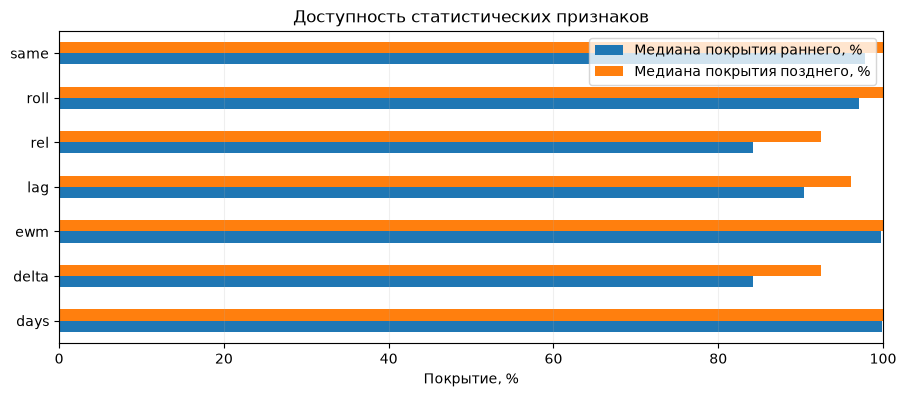

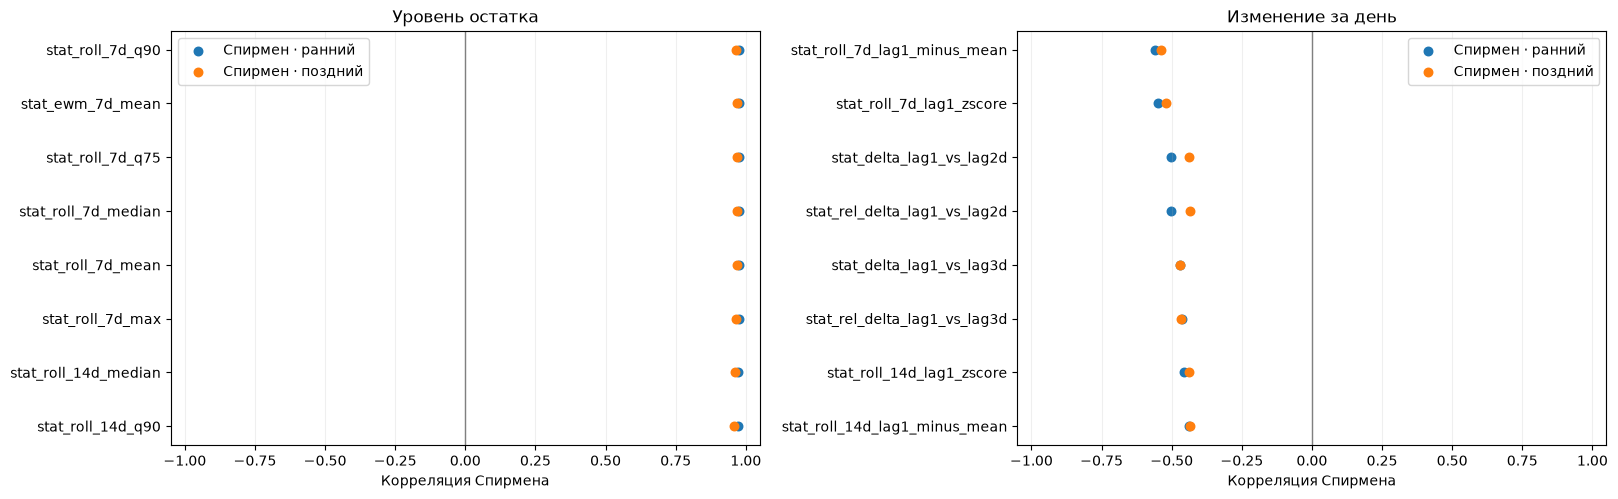


Валюта RUB
Уровень остатка


,Пар · ранний,Пирсон · ранний,Спирмен · ранний,Пар · поздний,Пирсон · поздний,Спирмен · поздний
Признак,,,,,,
stat_lag_1d,1309,0.922,0.983,340,0.825,0.821
stat_roll_7d_q75,1360,0.857,0.982,347,0.797,0.791
stat_roll_7d_q90,1360,0.856,0.982,347,0.787,0.775
stat_roll_7d_median,1360,0.856,0.981,347,0.786,0.779
stat_roll_14d_median,1358,0.854,0.980,347,0.764,0.746
stat_roll_14d_q90,1358,0.854,0.979,347,0.770,0.766
stat_roll_7d_mean,1360,0.835,0.979,347,0.803,0.797
stat_roll_14d_q75,1358,0.855,0.979,347,0.769,0.754
stat_roll_14d_q25,1358,0.855,0.979,347,0.766,0.743


Изменение за день


,Пар · ранний,Пирсон · ранний,Спирмен · ранний,Пар · поздний,Пирсон · поздний,Спирмен · поздний
Признак,,,,,,
stat_rel_delta_lag1_vs_lag7d,1257,0.011,-0.499,333,-0.416,-0.360
stat_delta_lag1_vs_lag7d,1258,-0.045,-0.497,333,-0.415,-0.361
stat_delta_lag1_vs_lag14d,1250,-0.055,-0.449,334,-0.435,-0.392
stat_rel_delta_lag1_vs_lag14d,1250,0.000,-0.448,334,-0.436,-0.392
stat_roll_7d_slope,1300,-0.037,-0.426,340,-0.384,-0.332
stat_roll_7d_lag1_minus_mean,1300,-0.053,-0.419,340,-0.418,-0.334
stat_roll_7d_lag1_zscore,1300,-0.188,-0.417,340,-0.319,-0.300
stat_roll_14d_lag1_zscore,1297,-0.179,-0.404,340,-0.355,-0.315
stat_roll_14d_lag1_minus_mean,1297,-0.058,-0.401,340,-0.413,-0.328


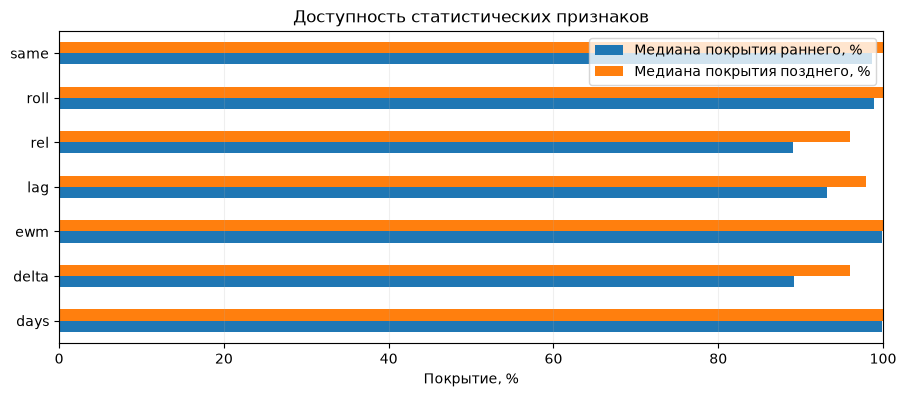

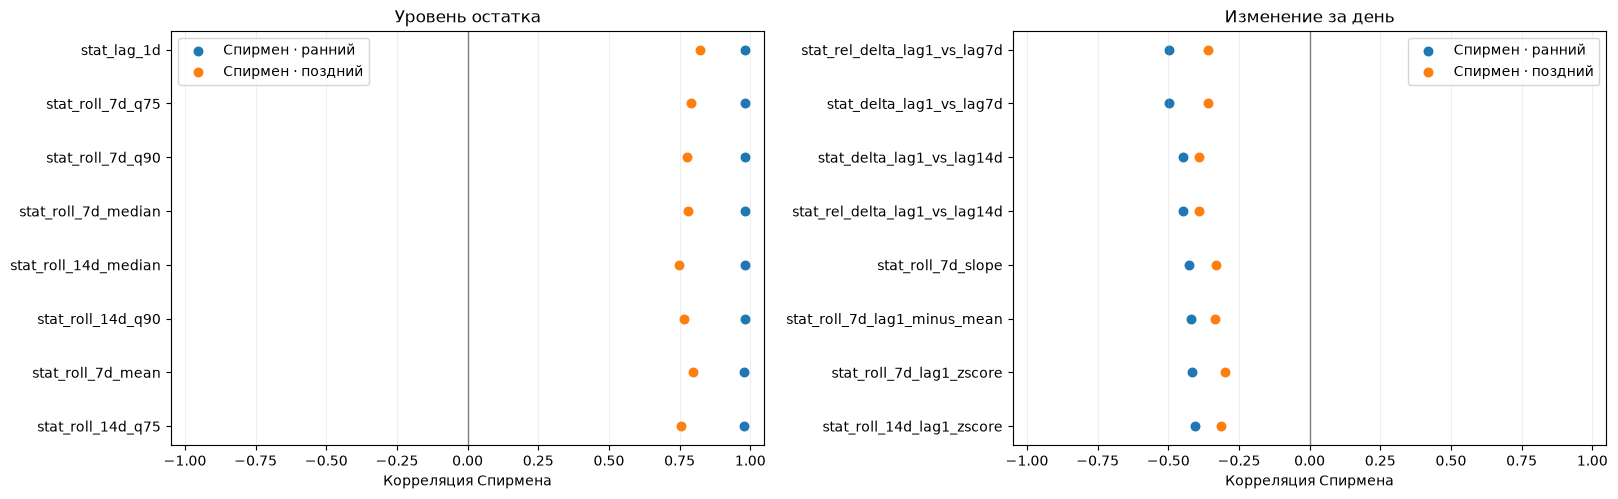


Валюта USD
Уровень остатка


,Пар · ранний,Пирсон · ранний,Спирмен · ранний,Пар · поздний,Пирсон · поздний,Спирмен · поздний
Признак,,,,,,
stat_roll_7d_mean,1196,0.942,0.980,307,0.981,0.965
stat_roll_7d_median,1196,0.949,0.980,307,0.980,0.964
stat_ewm_7d_mean,1210,0.948,0.979,307,0.981,0.965
stat_roll_7d_q25,1196,0.904,0.979,307,0.981,0.965
stat_roll_7d_q75,1196,0.947,0.979,307,0.980,0.964
stat_roll_7d_q90,1196,0.946,0.978,307,0.979,0.963
stat_roll_7d_q10,1196,0.883,0.978,307,0.979,0.963
stat_roll_7d_max,1196,0.944,0.976,307,0.976,0.961
stat_roll_7d_min,1196,0.882,0.976,307,0.973,0.957


Изменение за день


,Пар · ранний,Пирсон · ранний,Спирмен · ранний,Пар · поздний,Пирсон · поздний,Спирмен · поздний
Признак,,,,,,
stat_roll_7d_lag1_minus_mean,1127,-0.281,-0.553,296,-0.561,-0.509
stat_roll_7d_lag1_zscore,1127,-0.452,-0.547,296,-0.512,-0.491
stat_roll_14d_lag1_zscore,1122,-0.417,-0.496,296,-0.475,-0.433
stat_roll_14d_lag1_minus_mean,1122,-0.290,-0.490,296,-0.488,-0.431
stat_delta_lag1_vs_lag3d,1040,-0.243,-0.462,287,-0.487,-0.433
stat_delta_lag1_vs_lag2d,1066,-0.275,-0.461,286,-0.472,-0.407
stat_rel_delta_lag1_vs_lag2d,1066,-0.255,-0.460,286,-0.454,-0.399
stat_rel_delta_lag1_vs_lag3d,1040,-0.066,-0.459,287,-0.481,-0.432
stat_delta_lag1_vs_lag7d,1076,-0.199,-0.438,285,-0.425,-0.394


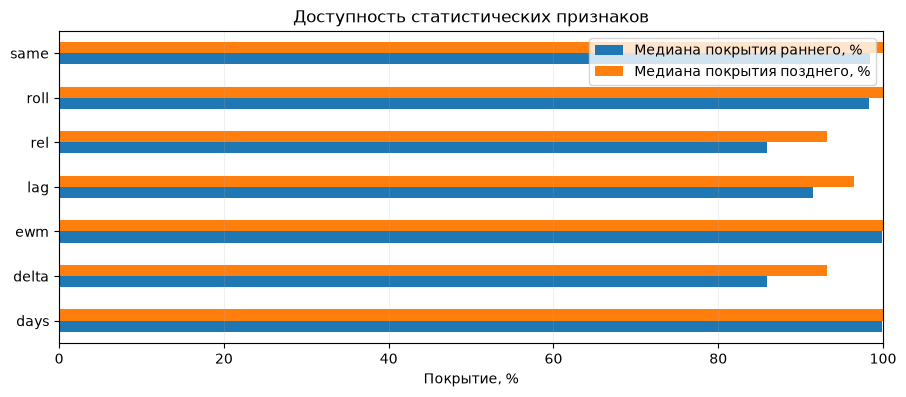

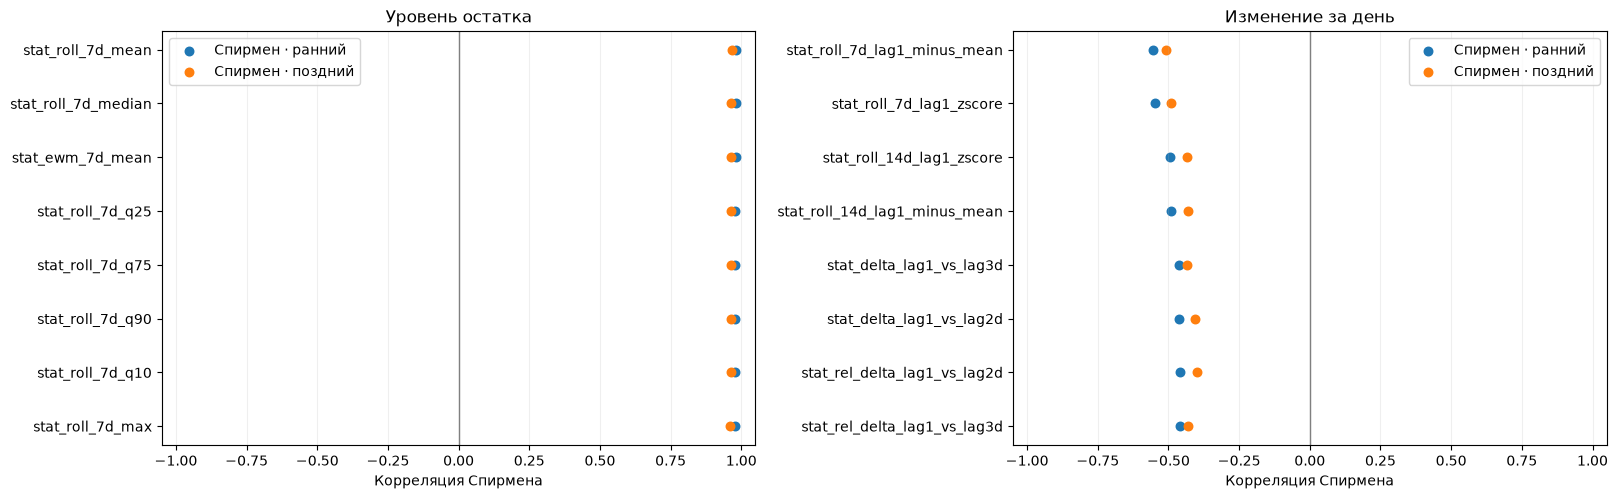

In [17]:
def stat_target_links(features, target, *, min_pairs=15):
    links = []
    for name, feature in features.items():
        paired = pd.concat([feature.rename("x"), target.rename("y")], axis=1).dropna()
        pearson = spearman = np.nan
        if len(paired) >= min_pairs and paired.nunique().min() > 1:
            pearson = paired["x"].corr(paired["y"])
            ranks = paired.rank()
            spearman = ranks["x"].corr(ranks["y"])
        links.append((name, len(paired), pearson, spearman))
    return pd.DataFrame(
        links, columns=["Признак", "Пар", "Пирсон", "Спирмен"]
    ).set_index("Признак")


def audit_stat_relationships(currency_stats, group_stat_audit, early_stat, late_stat):
    stat_target = pd.to_numeric(currency_stats["OST_VAL"], errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    )
    prev_day = stat_target.reindex(stat_target.index - pd.Timedelta(days=1))
    prev_day.index = stat_target.index
    targets = {
        "Уровень остатка": stat_target,
        "Изменение за день": stat_target - prev_day,
    }
    stat_links = {}

    for target_label, target_data in targets.items():
        early_links = stat_target_links(early_stat, target_data.reindex(early_stat.index))
        late_links = stat_target_links(late_stat, target_data.reindex(late_stat.index))
        combined = early_links.add_suffix(" · ранний").join(late_links.add_suffix(" · поздний"))
        combined = combined.sort_values(
            "Спирмен · ранний", key=lambda value: value.abs(), ascending=False
        )
        stat_links[target_label] = combined
        print(target_label)
        ranked = combined.dropna(subset=["Спирмен · ранний"])
        display(ranked.head(15).round(3))
        if ranked.empty:
            print("Недостаточно пар с ненулевым разбросом для оценки связи.")

    coverage_cols = ["Медиана покрытия раннего, %", "Медиана покрытия позднего, %"]
    fig, ax = plt.subplots(figsize=(9, 4))
    group_stat_audit[coverage_cols].plot.barh(ax=ax, xlim=(0, 100))
    ax.set(title="Доступность статистических признаков", xlabel="Покрытие, %", ylabel="")
    ax.grid(axis="x", alpha=0.2)
    plt.tight_layout()
    plt.show()

    ranked_links = {
        label: links.dropna(subset=["Спирмен · ранний"]).head(8)
        for label, links in stat_links.items()
    }
    if any(len(links) for links in ranked_links.values()):
        fig, axes = plt.subplots(1, len(ranked_links), figsize=(16, 5), squeeze=False)
        for ax, (label, links) in zip(axes[0], ranked_links.items()):
            if links.empty:
                ax.set_axis_off()
                continue
            plot_links = links[["Спирмен · ранний", "Спирмен · поздний"]].iloc[::-1]
            y = np.arange(len(plot_links))
            for column in plot_links:
                ax.scatter(plot_links[column], y, label=column)
            ax.set_yticks(y, plot_links.index)
            ax.axvline(0, color="gray", linewidth=1)
            ax.set(title=label, xlabel="Корреляция Спирмена", xlim=(-1.05, 1.05))
            ax.grid(axis="x", alpha=0.2)
            ax.legend(loc="best")
        plt.tight_layout()
        plt.show()

    return stat_target, stat_links


stat_target_by_currency, stat_links_by_currency = {}, {}
for currency in iter_eda_currencies():
    stat_target_by_currency[currency], stat_links_by_currency[currency] = audit_stat_relationships(
        df_stat_by_currency[currency], *stat_distribution_inputs[currency]
    )

### Простые ориентиры на позднем отрезке каждой валюты

Сравниваем вчерашний остаток, остаток неделю назад и скользящую медиану за 7 дней как прогнозы уровня на одну дату вперёд. Для всех трёх берём одни и те же даты, где доступны целевое значение и каждый прогноз. MAE и RMSE выражены в исходных единицах остатка. Положительное смещение означает завышение прогноза. История обновляется каждый день, когда появляется фактический остаток. Эти результаты относятся к прогнозу на следующий день с таким обновлением.

In [18]:
def compare_baselines(late_stat, stat_target):
    baseline_names = {
        "stat_lag_1d": "Остаток вчера",
        "stat_lag_7d": "Остаток неделю назад",
        "stat_roll_7d_median": "Медиана за 7 дней",
    }
    baseline_scores = pd.DataFrame()
    if all(name in late_stat for name in baseline_names):
        baseline_rows = late_stat[list(baseline_names)].assign(Факт=stat_target).dropna()
        print(f"Общих дат для сравнения: {len(baseline_rows):,} из {len(late_stat):,}.")
        if len(baseline_rows):
            forecast_errors = baseline_rows[list(baseline_names)].sub(
                baseline_rows["Факт"], axis=0
            )
            baseline_scores = pd.DataFrame({
                "MAE": forecast_errors.abs().mean(),
                "RMSE": forecast_errors.pow(2).mean().pow(0.5),
                "Медианная абсолютная ошибка": forecast_errors.abs().median(),
                "Смещение": forecast_errors.mean(),
            }).rename(index=baseline_names).sort_values("MAE")
            display(baseline_scores.round(3))
    else:
        print("Для сравнения нужны лаги 1 и 7 дней и скользящее окно 7 дней.")
    return baseline_scores


baseline_scores_by_currency = {
    currency: compare_baselines(stat_distribution_inputs[currency][2], stat_target_by_currency[currency])
    for currency in iter_eda_currencies()
}


Валюта EUR
Общих дат для сравнения: 235 из 257.


,MAE,RMSE,Медианная абсолютная ошибка,Смещение
Медиана за 7 дней,2.572,3.212,2.24,0.222
Остаток вчера,3.000,3.835,2.53,0.031
Остаток неделю назад,3.573,4.463,3.05,0.598



Валюта RUB
Общих дат для сравнения: 333 из 348.


,MAE,RMSE,Медианная абсолютная ошибка,Смещение
Остаток вчера,57.751,76.758,46.33,-2.646
Медиана за 7 дней,64.010,82.967,52.61,0.537
Остаток неделю назад,77.051,99.839,61.82,1.026



Валюта USD
Общих дат для сравнения: 285 из 308.


,MAE,RMSE,Медианная абсолютная ошибка,Смещение
Медиана за 7 дней,1.850,2.360,1.49,0.074
Остаток вчера,2.105,2.734,1.65,-0.044
Остаток неделю назад,2.427,3.063,1.97,0.264


## Что использовать дальше

- `df_work` — очищенные отчётные строки. `model_daily` — дневная сетка с индексом из валюты и даты.
- `df_stat` — отчётные строки со статистическими признаками. Для объединения с другими данными используйте оба столбца ключа, валюту и `REP_DT`.
- При прогнозе на несколько дней вперёд используйте только остатки и календарь, доступные на дату выпуска прогноза. Сохранённые в ноутбуке результаты относятся к синтетическому файлу.